# 🏠 보스턴 주택가격 회귀분석 — 품질 점검부터 최종 모델 진단까지

> 보스턴 506개 지역의 주택 데이터로 **품질 점검 → EDA → 전처리 조합 비교 → 최종 모델 진단**을 하나의 흐름으로 수행했습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | Boston Housing · 506행 × 14개 변수 |
| **종속변수** | `MEDV` 주택가격 중앙값 ($1,000) |
| **분석 질문** | ① 집값을 가장 크게 좌우하는 요인은? ② 어떤 전처리가 실제로 성능을 올리는가? ③ 데이터의 '상한 50' 문제는 모델에 얼마나 영향을 주는가? |
| **주요 기법** | Spearman 상관 · Mann-Whitney U · 로그/반사 로그변환 · VIF · 후진소거 OLS · HC3 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드, 분석 설정
1. **PART 1. 데이터 품질 점검** — 자료형 · 중복 · 결측 · 기술통계 · 로그변환 판정
2. **PART 2. EDA** — 단변량 → 이변량(채택 기준) → 다변량(중복 정보)
3. **PART 3. 회귀모델링** — 전처리 체크포인트 비교, 상한값 민감도 분석, 최종 모델 보고
4. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_ols` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [33]:
# ----- 라이브러리 참조
import numpy as np
from pandas import DataFrame, concat, set_option
from IPython.display import display, Markdown

from jussam import load_data      # 실습 데이터 로더
from helpers import *             # my_qtcheck · my_plot · my_stats · my_prep · my_ols

# ----- 출력 형식 (소수점 3자리, 컬럼 생략 없이)
set_option("display.float_format", "{:,.3f}".format)
set_option("display.max_columns", 50)

### (2) 데이터 로드

In [34]:
origin = load_data("boston")
print(f'데이터 크기: {origin.shape}')
origin.head()

📚 보스턴 인근 지역의 인구·환경·교육·범죄·세금 정보 등을 기반으로 주택의 중위가격(MEDV)을 예측하기 위해 수집된 대표적인 회귀 분석용 주택시장 데이터 (출처: https://www.kaggle.com/datasets/altavish/boston-housing-dataset)

    field    description
--  -------  ---------------------------------------------------------------------------------------------
 0  CRIM     타운별 1인당 범죄율 (Per capita crime rate by town)
 1  ZN       25,000 sqft 이상 주거용 대지 비율 (Proportion of residential land zoned for large lots)
 2  INDUS    비소매 상업구역 비율 (Proportion of non-retail business acres per town)
 3  CHAS     명목형, 찰스강 인접 여부 (Charles River dummy variable: 1 if tract bounds river; 0 otherwise)
 4  NOX      대기 오염 정도 (Nitric oxides concentration, parts per 10 million)
 5  RM       주택당 평균 방(Room) 수 (Average number of rooms per dwelling)
 6  AGE      1940년 이전 건축 비율 (Proportion of owner-occupied units built prior to 1940)
 7  DIS      5개 주요 고용센터까지의 거리 (Weighted distances to five Boston employment centers)
 8  RAD      고속도로 접근성 지수 (Index of accessibility to radial highways)
 9  T

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.006,18.000,2.310,0,0.538,6.575,65.200,4.090,1,296,15.300,396.900,4.980,24.000
1,0.027,0.000,7.070,0,0.469,6.421,78.900,4.967,2,242,17.800,396.900,9.140,21.600
2,0.027,0.000,7.070,0,0.469,7.185,61.100,4.967,2,242,17.800,392.830,4.030,34.700
3,0.032,0.000,2.180,0,0.458,6.998,45.800,6.062,3,222,18.700,394.630,2.940,33.400
4,0.069,0.000,2.180,0,0.458,7.147,54.200,6.062,3,222,18.700,396.900,5.330,36.200


### (3) 분석 설정

- 데이터셋마다 달라지는 값(종속변수 · 명목형 지정 · 컬럼 의미)은 **이 셀 하나에 모아** 두고, 아래 코드는 이 값만 참조한다.

In [35]:
target = "MEDV"                 # 종속변수
as_category = ["CHAS"]          # 명목형으로 지정할 컬럼 (0/1 더미지만 의미는 '강변 인접 여부')

column_means = {
    "CRIM": "범죄율", "ZN": "대규모주거지비율", "INDUS": "비소매상업지비율",
    "CHAS": "찰스강인접여부", "NOX": "대기오염도", "RM": "평균방수",
    "AGE": "노후주택비율", "DIS": "고용센터거리", "RAD": "고속도로접근성",
    "TAX": "재산세율", "PTRATIO": "학생교사비율", "B": "흑인비율지수",
    "LSTAT": "저소득층비율", "MEDV": "주택가격중앙값($1,000)",
}

---
# PART 1. 데이터 품질 점검 

### (1) 자료형 변환

In [36]:
df = my_qtcheck.set_type(data=origin, as_category=as_category)

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float32 
 1   ZN       506 non-null    float32 
 2   INDUS    506 non-null    float32 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float32 
 5   RM       506 non-null    float32 
 6   AGE      506 non-null    float32 
 7   DIS      506 non-null    float32 
 8   RAD      506 non-null    int32   
 9   TAX      506 non-null    int32   
 10  PTRATIO  506 non-null    float32 
 11  B        506 non-null    float32 
 12  LSTAT    506 non-null    float32 
 13  MEDV     506 non-null    float32 
dtypes: category(1), float32(11), int32(2)
memory usage: 26.3 KB


### (2) 중복 · 결측치 점검

In [37]:
df = my_qtcheck.check_duplicates(data=df)
my_qtcheck.check_missing_values(data=df)

중복된 행의 수: 0


,Missing Count,Missing Ratio (%)
CRIM,0,0.000
ZN,0,0.000
INDUS,0,0.000
CHAS,0,0.000
NOX,0,0.000
RM,0,0.000
AGE,0,0.000
DIS,0,0.000
RAD,0,0.000
TAX,0,0.000


### (3) 명목형 변수 기술통계

In [38]:
cat_desc = my_qtcheck.categorical_summary(data=df)
cat_desc

컬럼 'CHAS'의 value_counts( ):


,count
CHAS,
0,471
1,35


,CHAS
count,506
unique,2
top,0
freq,471


### (4) 연속형 변수 기술통계 · 이상치 · 왜도/첨도 · 로그변환 판정

In [40]:
num_desc = my_qtcheck.numerical_summary(data=df)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,total_outliers,total_outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
CRIM,506.000,3.614,8.602,0.006,0.082,0.257,3.677,88.976,13.087,large_diff,3.595,9.070,-5.311,66,0.130,0,0.000,66,0.130,5.223,right tail,37.131,leptokurtic,log
ZN,506.000,11.364,23.322,0.000,0.000,0.000,12.500,100.000,inf,large_diff,12.500,31.250,-18.750,68,0.134,0,0.000,68,0.134,2.226,right tail,4.032,leptokurtic,log1p
INDUS,506.000,11.137,6.860,0.460,5.190,9.690,18.100,27.740,0.149,diff,12.910,37.465,-14.175,0,0.000,0,0.000,0,0.000,0.295,symmetric,-1.234,platykurtic,none
NOX,506.000,0.555,0.116,0.385,0.449,0.538,0.624,0.871,0.031,similar,0.175,0.887,0.186,0,0.000,0,0.000,0,0.000,0.729,right tail,-0.065,platykurtic,none
RM,506.000,6.285,0.703,3.561,5.886,6.209,6.623,8.780,0.012,similar,0.738,7.730,4.779,22,0.043,8,0.016,30,0.059,0.404,symmetric,1.892,leptokurtic,none
AGE,506.000,68.575,28.149,2.900,45.025,77.500,94.075,100.000,0.115,diff,49.050,167.650,-28.550,0,0.000,0,0.000,0,0.000,-0.599,left tail,-0.968,platykurtic,none
DIS,506.000,3.795,2.106,1.130,2.100,3.207,5.188,12.127,0.183,diff,3.088,9.821,-2.532,5,0.010,0,0.000,5,0.010,1.012,right tail,0.488,leptokurtic,log
RAD,506.000,9.549,8.707,1.000,4.000,5.000,24.000,24.000,0.910,large_diff,20.000,54.000,-26.000,0,0.000,0,0.000,0,0.000,1.005,right tail,-0.867,platykurtic,log
TAX,506.000,408.237,168.537,187.000,279.000,330.000,666.000,711.000,0.237,diff,387.000,"1,246.500",-301.500,0,0.000,0,0.000,0,0.000,0.670,right tail,-1.142,platykurtic,none
PTRATIO,506.000,18.456,2.165,12.600,17.400,19.050,20.200,22.000,0.031,similar,2.800,24.400,13.200,0,0.000,15,0.030,15,0.030,-0.802,left tail,-0.285,platykurtic,none


### (5) 도메인 점검 — 종속변수 상한값

- 보스턴 데이터의 `MEDV`는 **50(= $50,000)에서 잘려 있다**고 알려져 있다. 실제로 몇 건이 상한에 걸려 있는지 확인한다.
- 상한에 걸린 집이 '고급 주거지'인지 확인하기 위해, 방향이 분명한 대표 변수로 비교한다.
  - 집의 크기 : `RM`(평균 방 수) — 클수록 고급
  - 동네의 소득 수준 : `LSTAT`(저소득층 비율) — 낮을수록 고급
  - 입지 : `CHAS`(강변 여부) — 강변일수록 선호

In [43]:
capped = (df[target] == df[target].max())
print(f"MEDV 최댓값: {df[target].max()} | 상한값과 같은 행: {capped.sum()}건 ({capped.mean():.1%})")

# 상한에 걸린 집은 어떤 동네인가? (평균 비교)
profile = df.assign(CHAS=df["CHAS"].astype(int)).groupby(capped)[["CHAS", "RM", "LSTAT"]].mean()
profile.index = ["나머지 490건", "MEDV = 50 (16건)"]
profile

MEDV 최댓값: 50.0 | 상한값과 같은 행: 16건 (3.2%)


,CHAS,RM,LSTAT
나머지 490건,0.059,6.245,12.924
MEDV = 50 (16건),0.375,7.484,4.355


> 💡 **인사이트 — 품질 점검**
>
> - 506행 모두 **결측 0건 · 중복 0건**으로 깨끗하다. 0/1로 저장된 `CHAS`만 의미에 맞게 category로 바꿨다.
> - 문제는 '값의 누락'이 아니라 **분포**였다. `CRIM`(왜도 5.22, 첨도 37.1) · `ZN`(이상치 13.4%) · `B`(하단 이상치 15.2%)가 극단적으로 치우쳐 있다. 모듈은 종속변수를 포함한 **7개 변수에 로그변환**을 판정했다.
>   - 우측 꼬리 6개 : `CRIM` · `DIS` · `RAD` · `LSTAT` · `MEDV`는 log, 0이 포함된 `ZN`은 log1p
>   - 좌측 꼬리 1개 : `B`는 **반사 후 log1p**
> - **종속변수에 상한(censoring)이 있다.** `MEDV = 50`인 16건(3.2%)은 실제 가격이 아니라 잘린 값이다.
>   이 16건은 나머지 490건과 비교해 **최고급 주거지**에 몰려 있다.
>
>   | | 상한 16건 | 나머지 490건 |
>   |---|---|---|
>   | 강변 비율 (`CHAS`) | 37.5% | 5.9% |
>   | 평균 방 수 (`RM`) | 7.5개 | 6.2개 |
>   | 저소득층 비율 (`LSTAT`) | 4.4% | 12.9% |
>
>   → PART 3에서 이 행이 모델을 얼마나 흔드는지 **민감도 분석**으로 검증한다.

---
# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

- 품질 점검에서 확정한 자료형을 기준으로 명목형 / 연속형을 나눈다.

In [44]:
nominal_cols = my_qtcheck.get_categorical_column_names(df)
continuous_cols = my_qtcheck.get_number_column_names(df)
continuous_cols.remove(target)

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : MEDV
명목형   : ['CHAS']
연속형   : ['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


## 2-1. 단변량 분석

### (1) 종속변수 분포

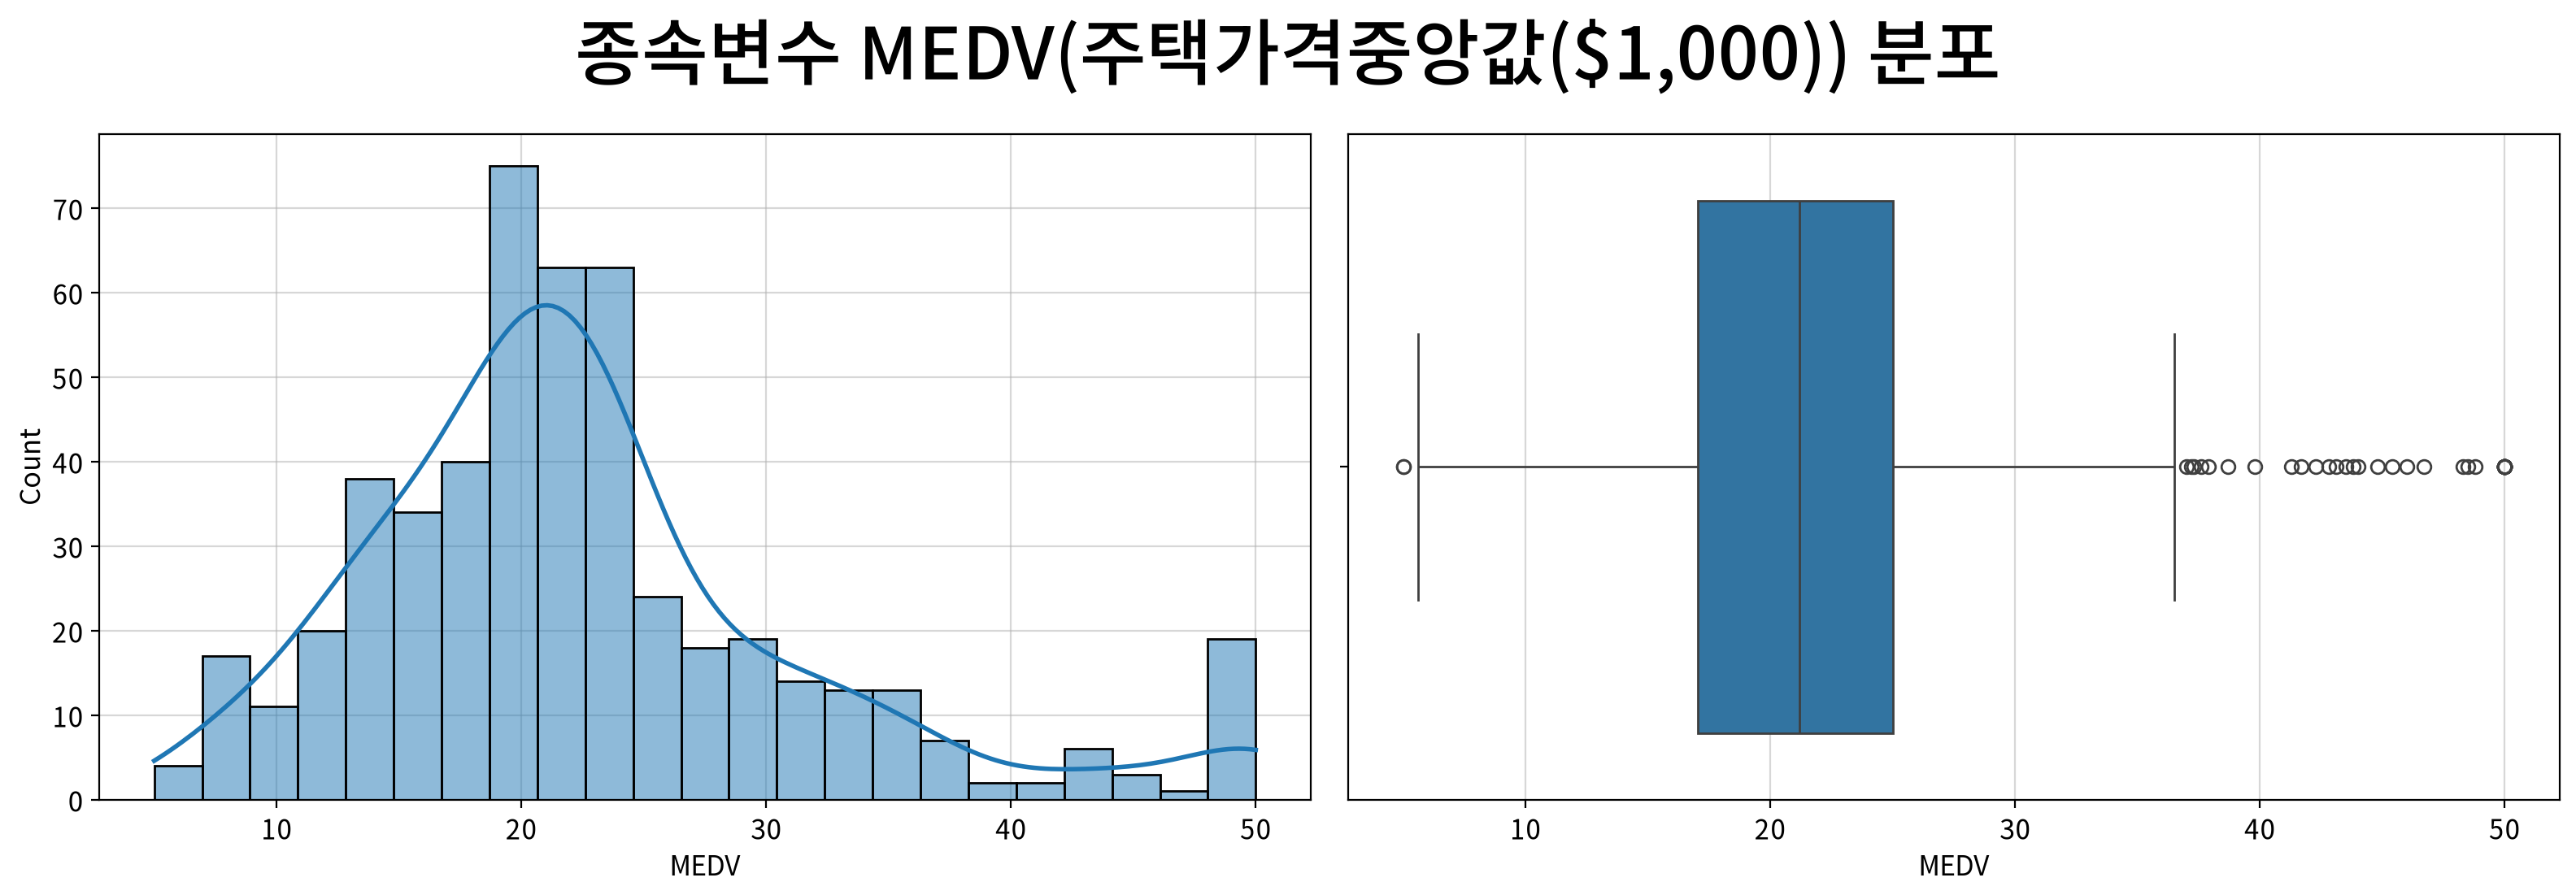

In [46]:
fig, ax = my_plot.init(rows=1, cols=2, width=800, height=560, title=f"종속변수 {target}({column_means[target]}) 분포")
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

### (2) 연속형 독립변수 분포

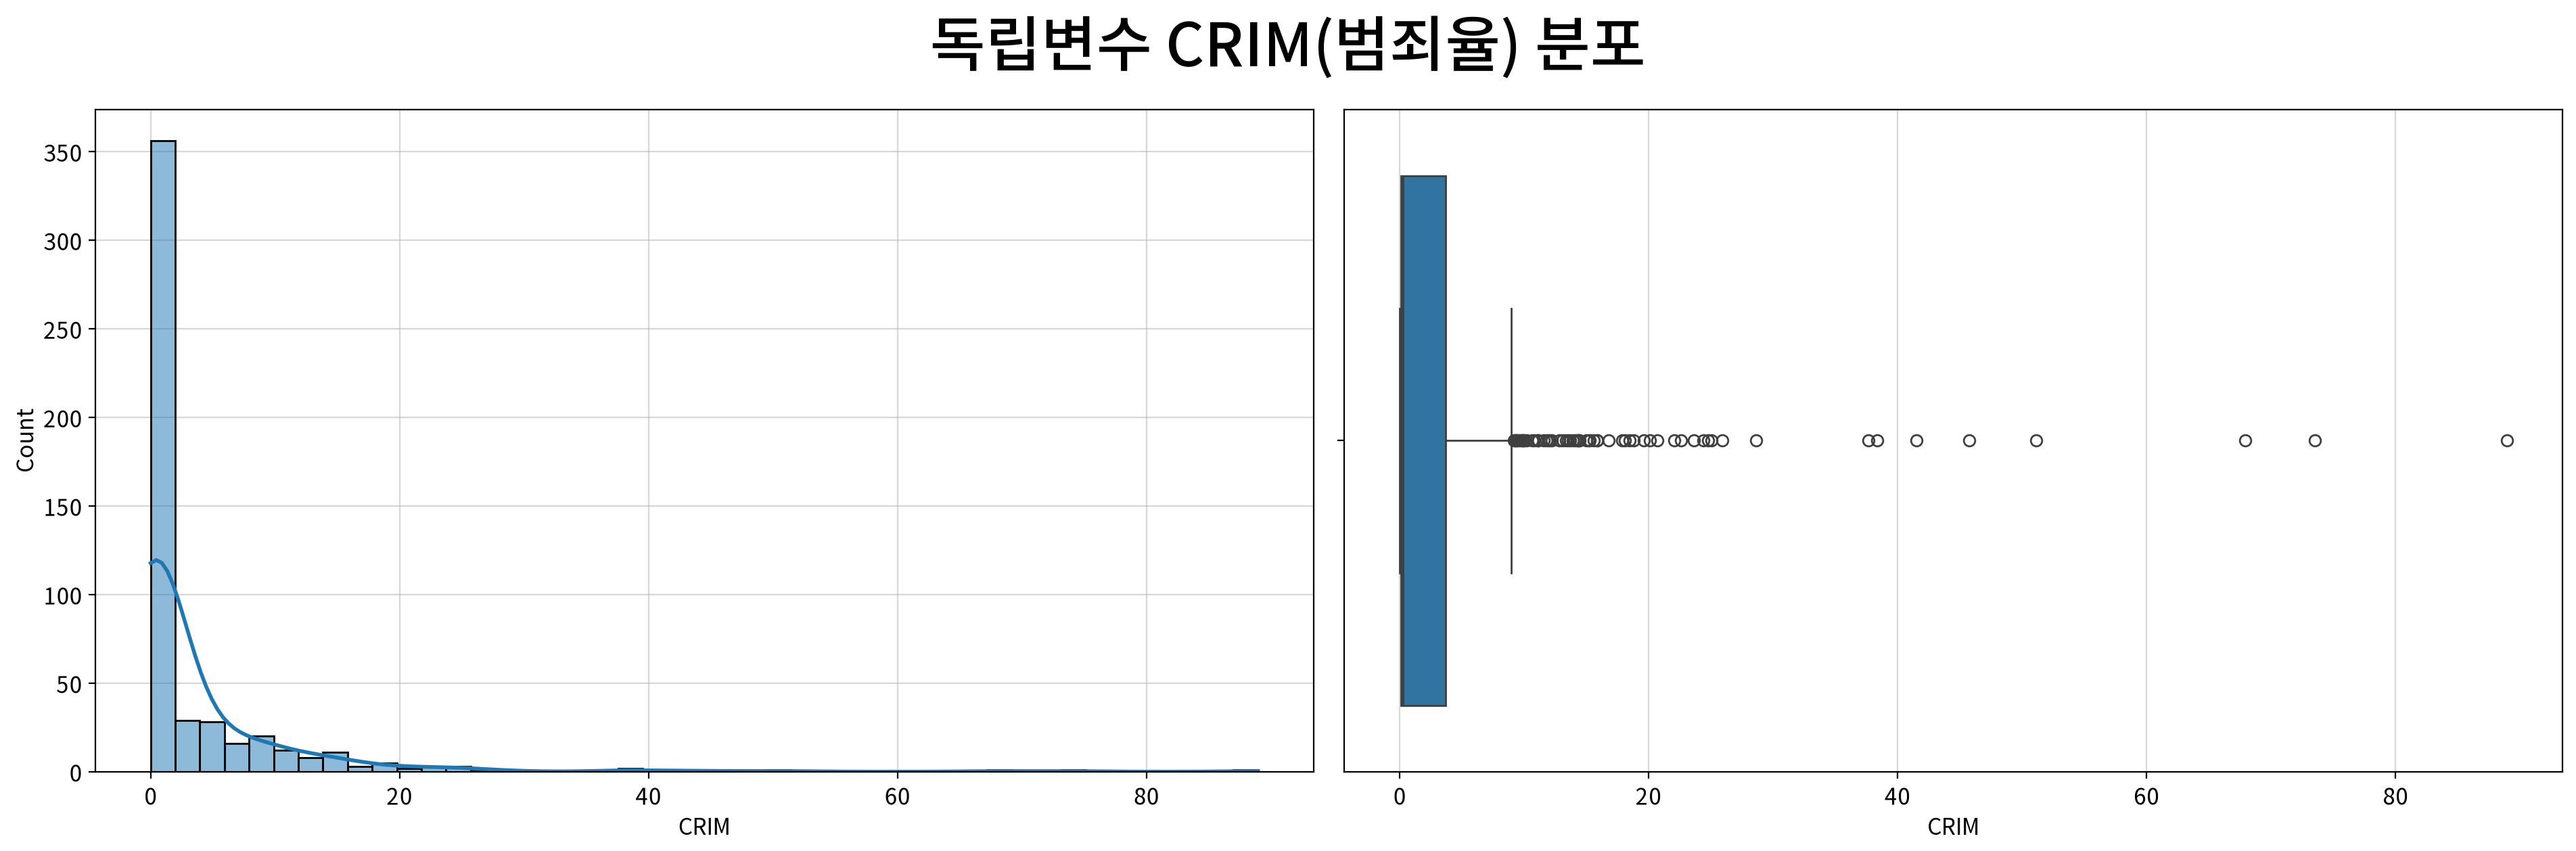

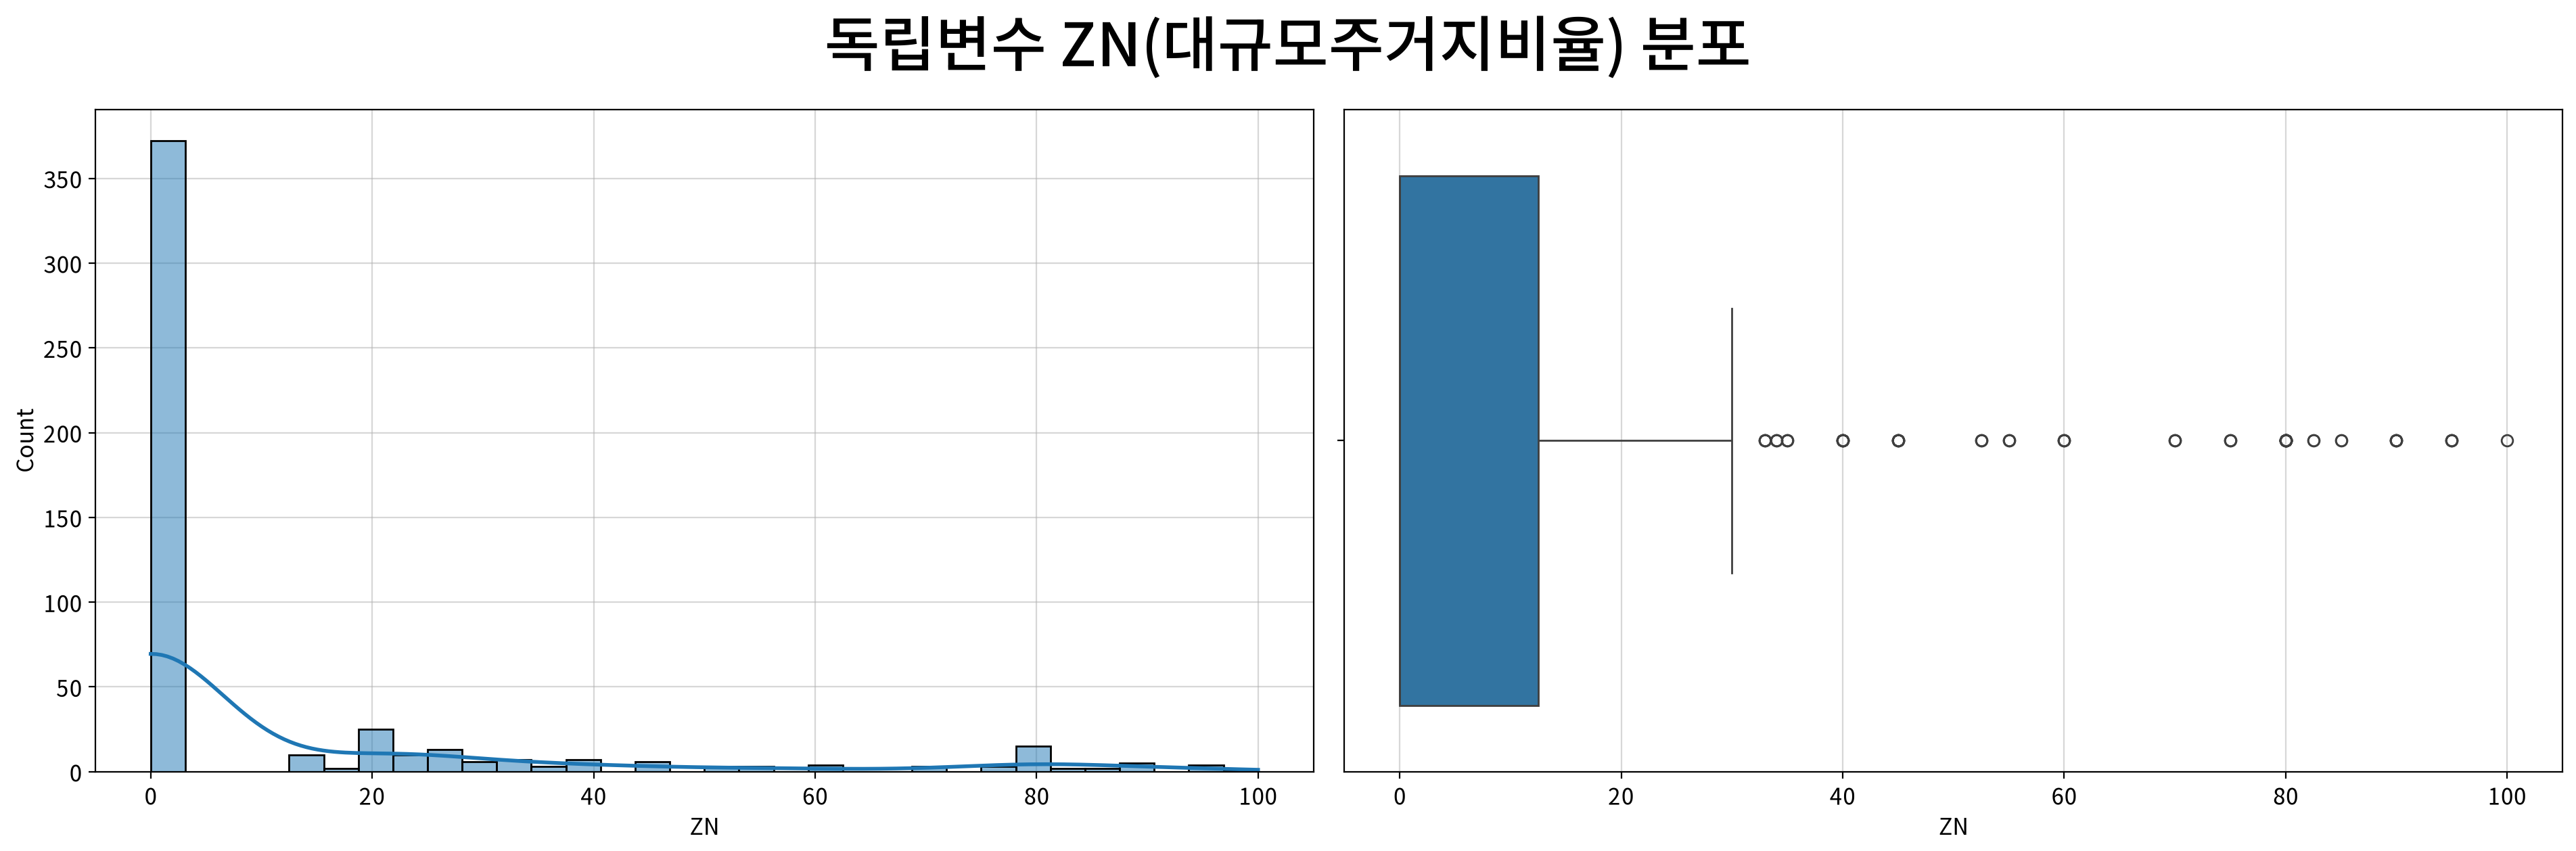

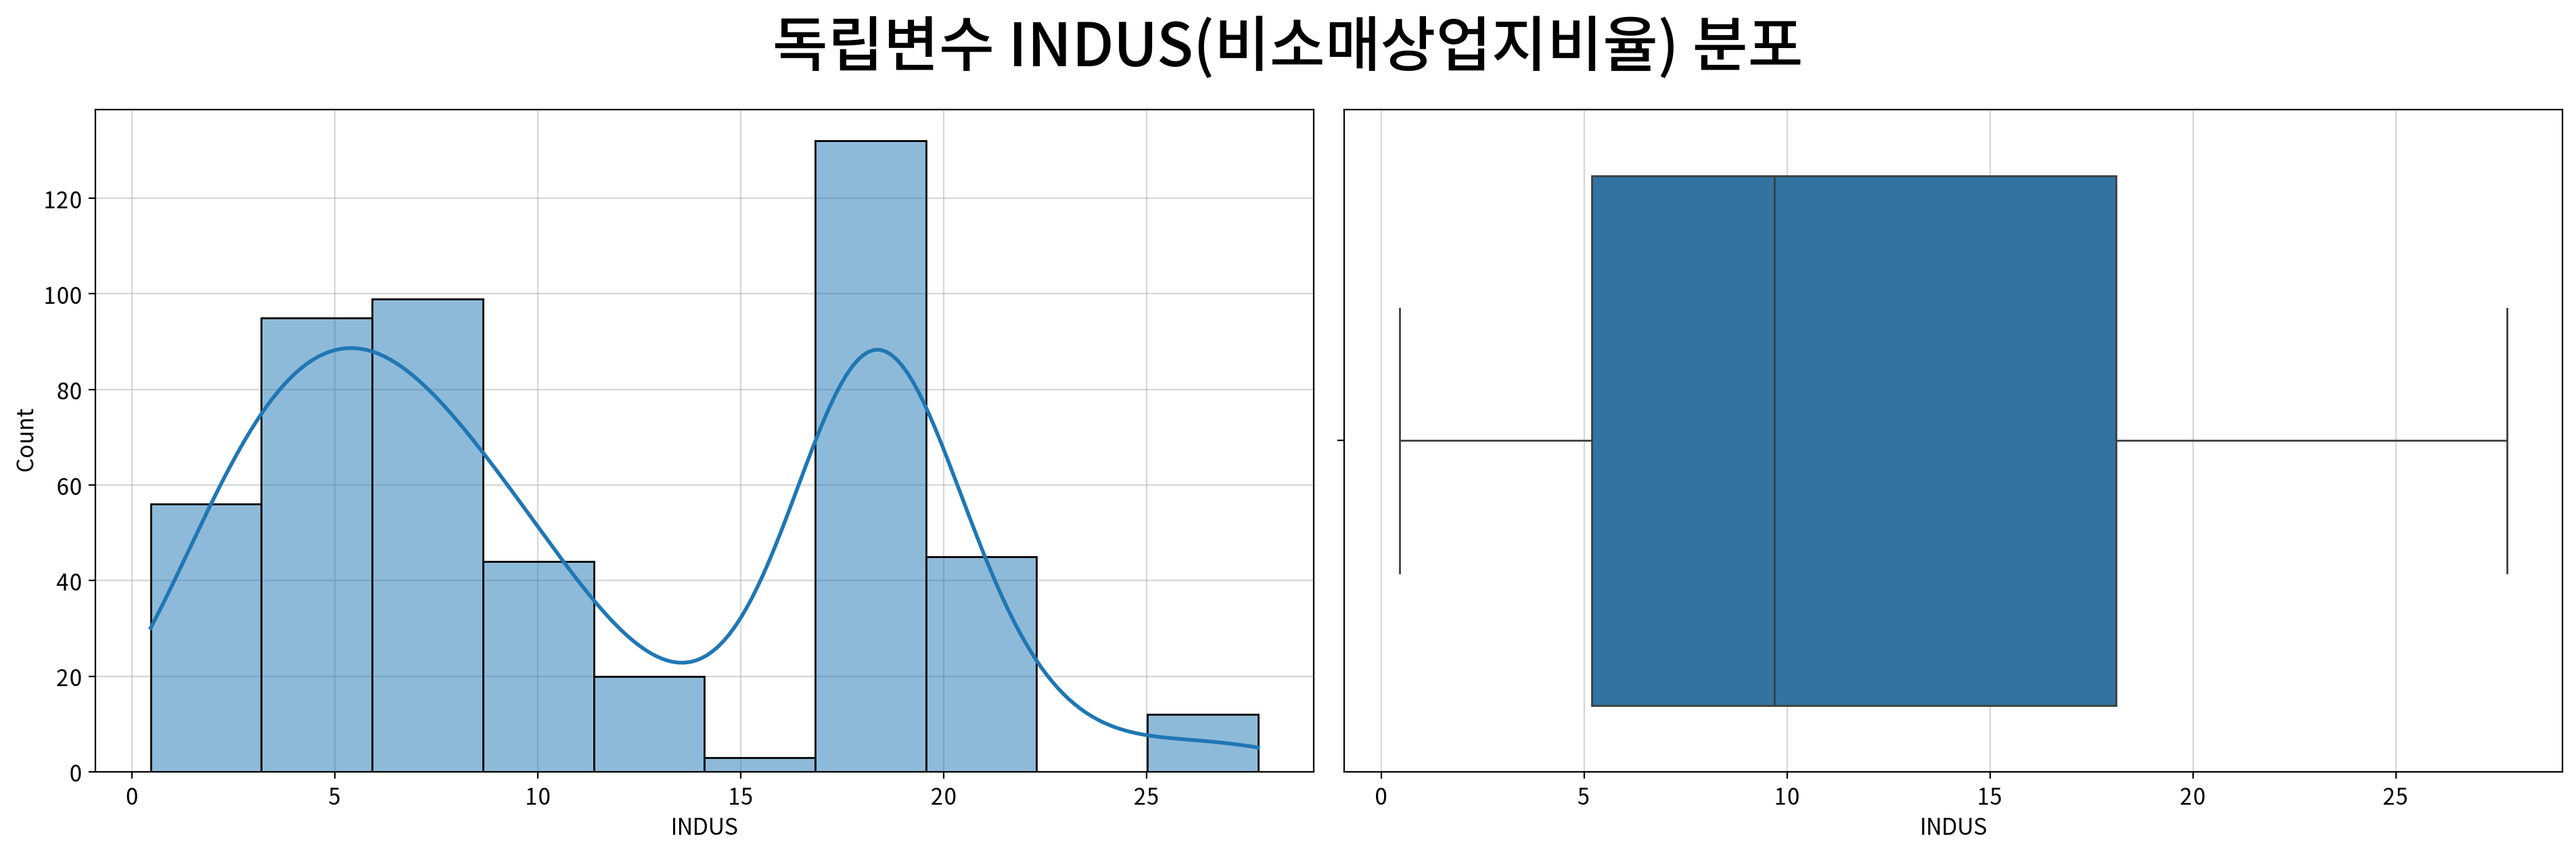

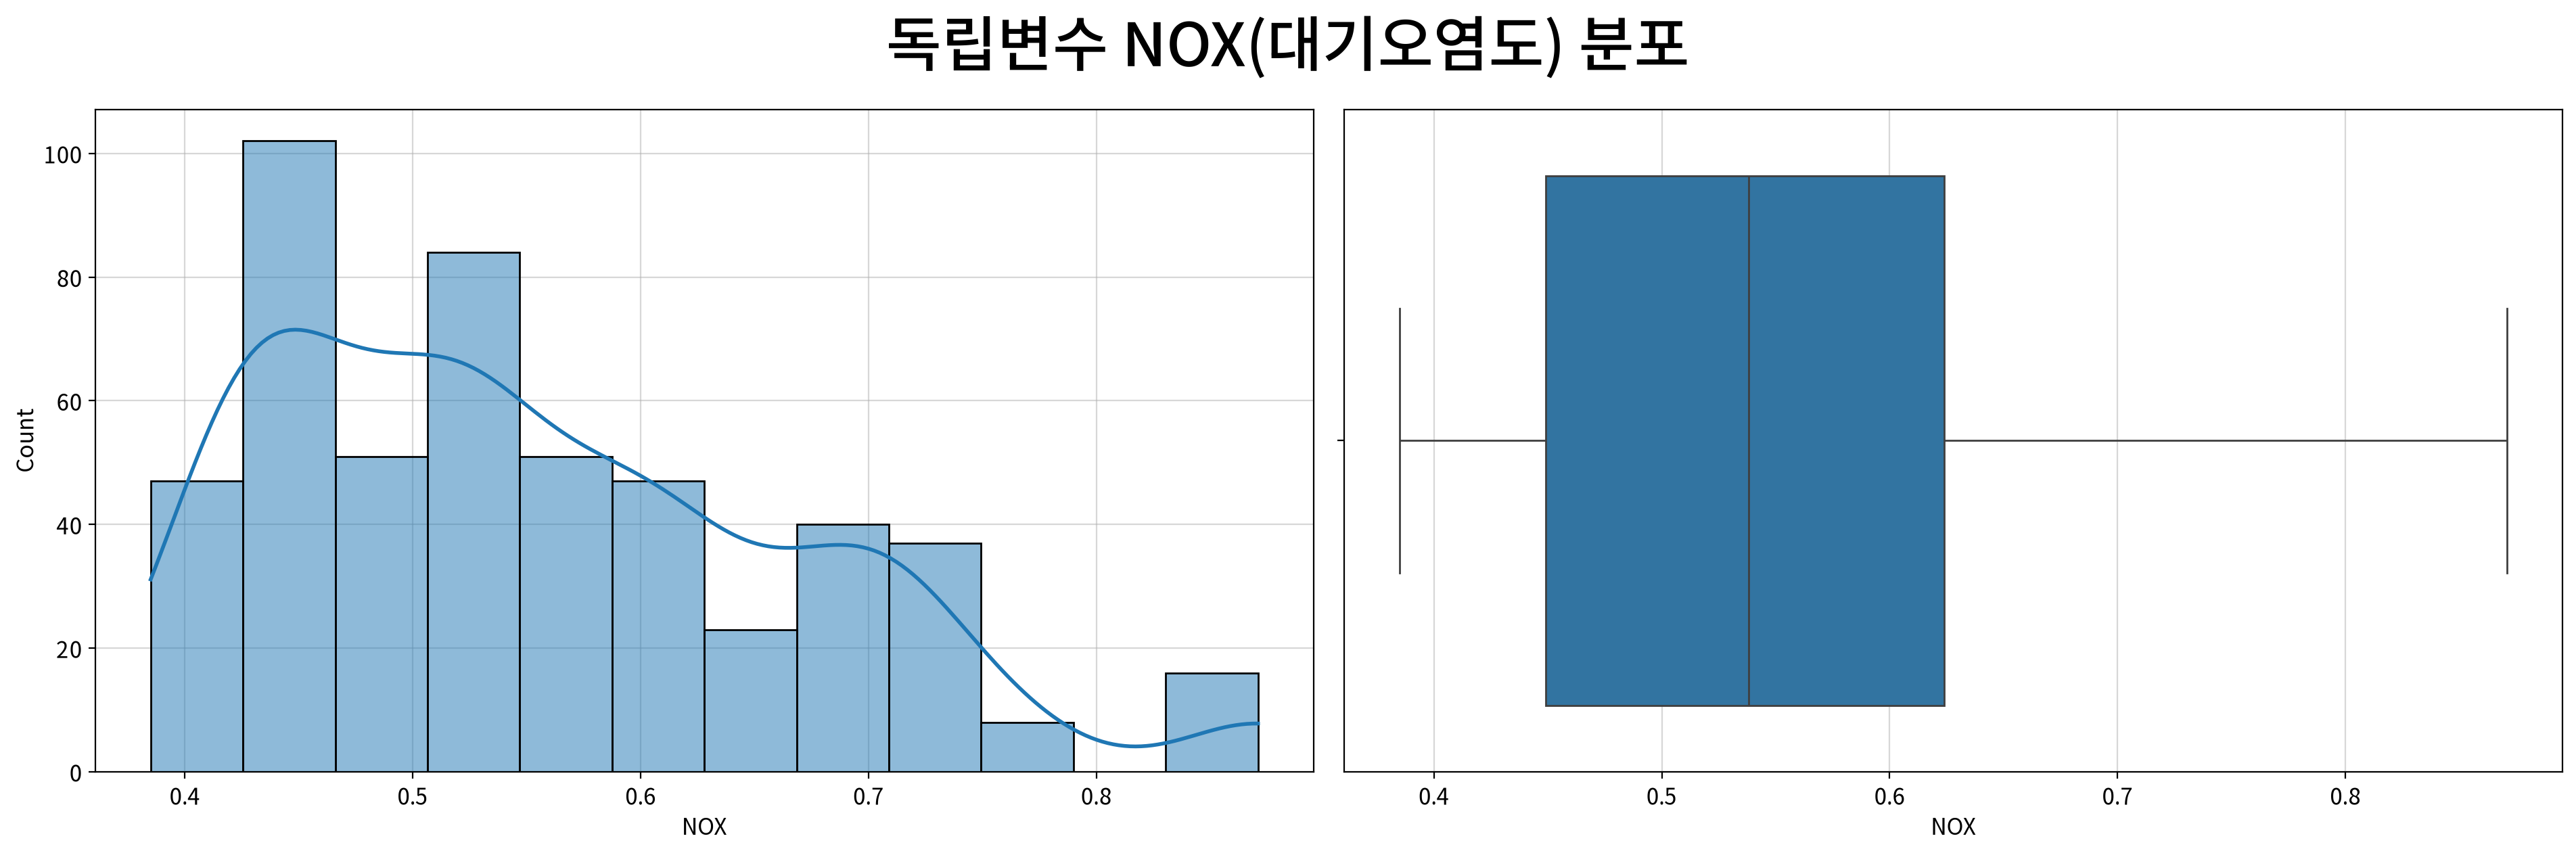

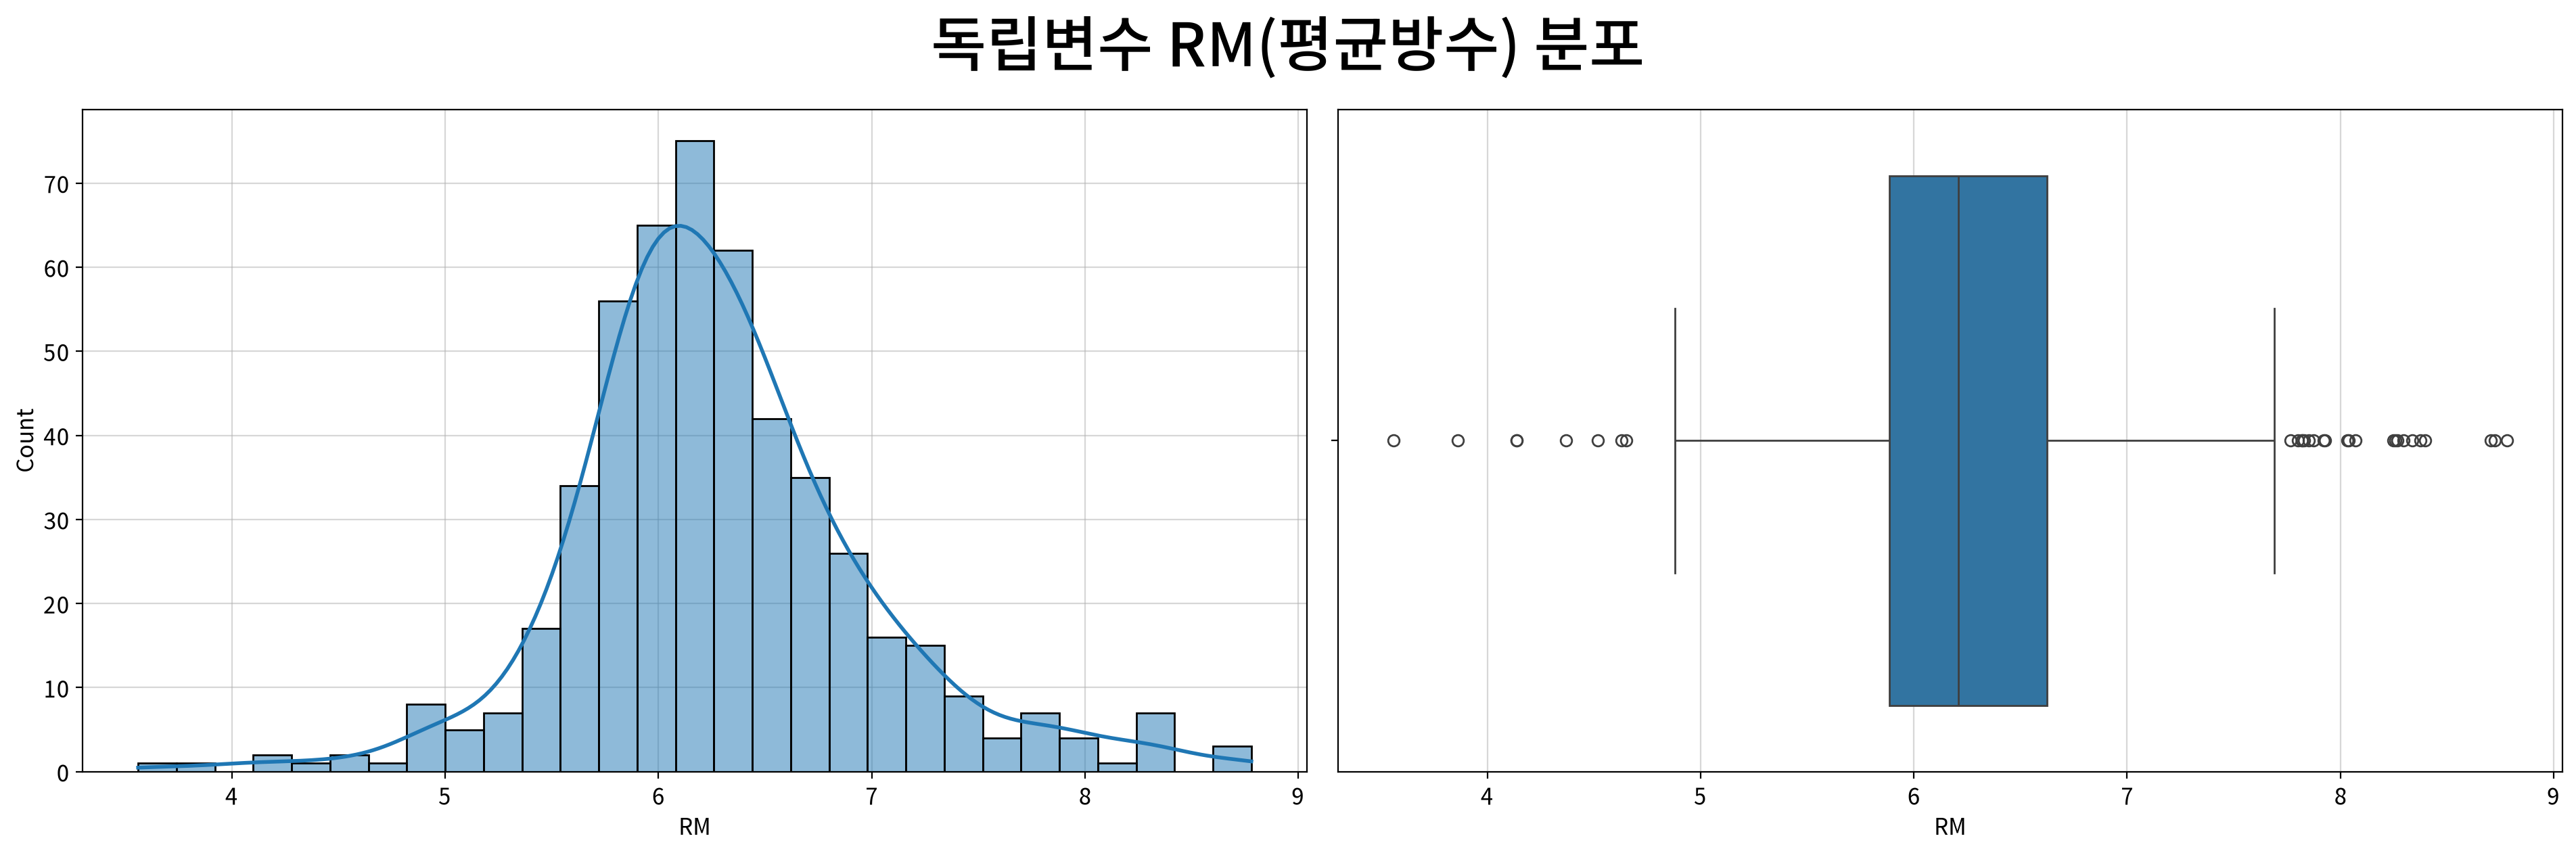

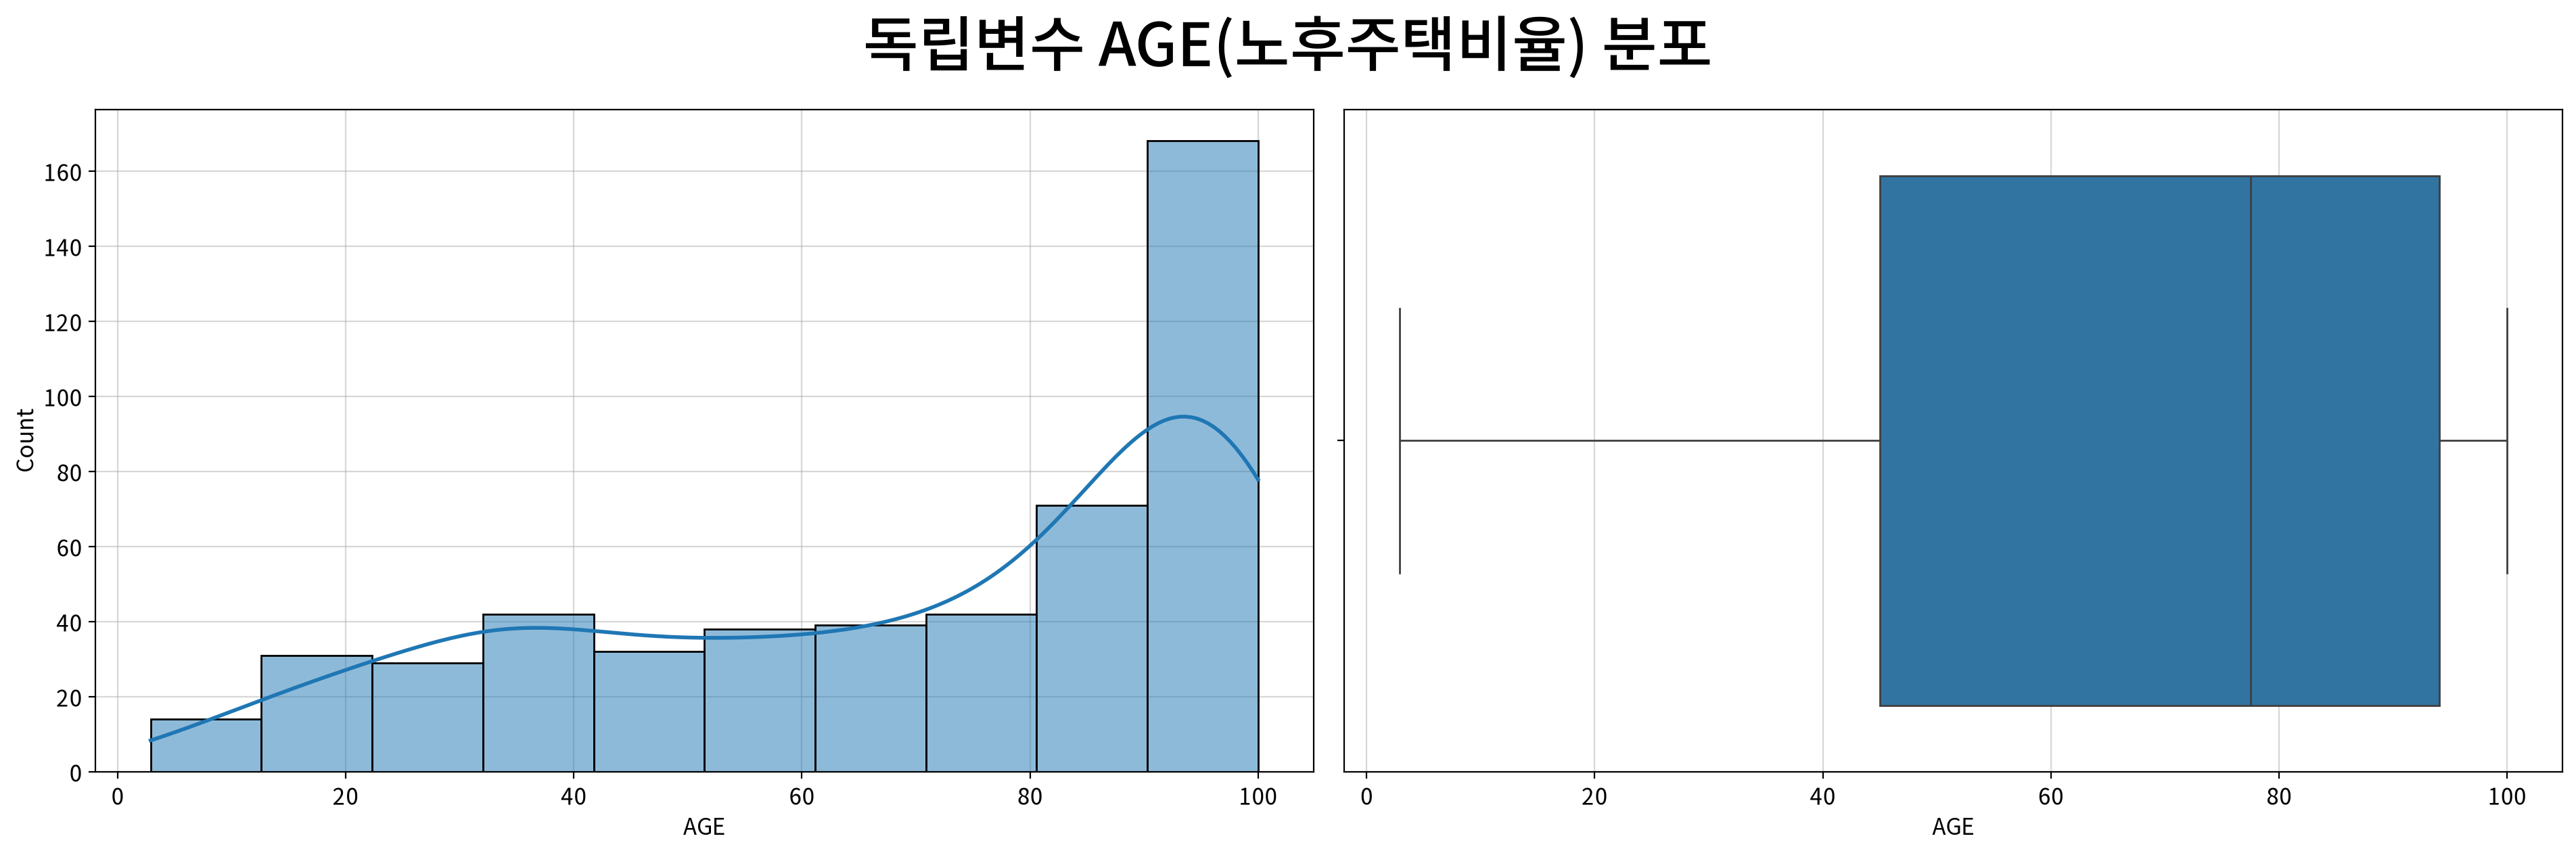

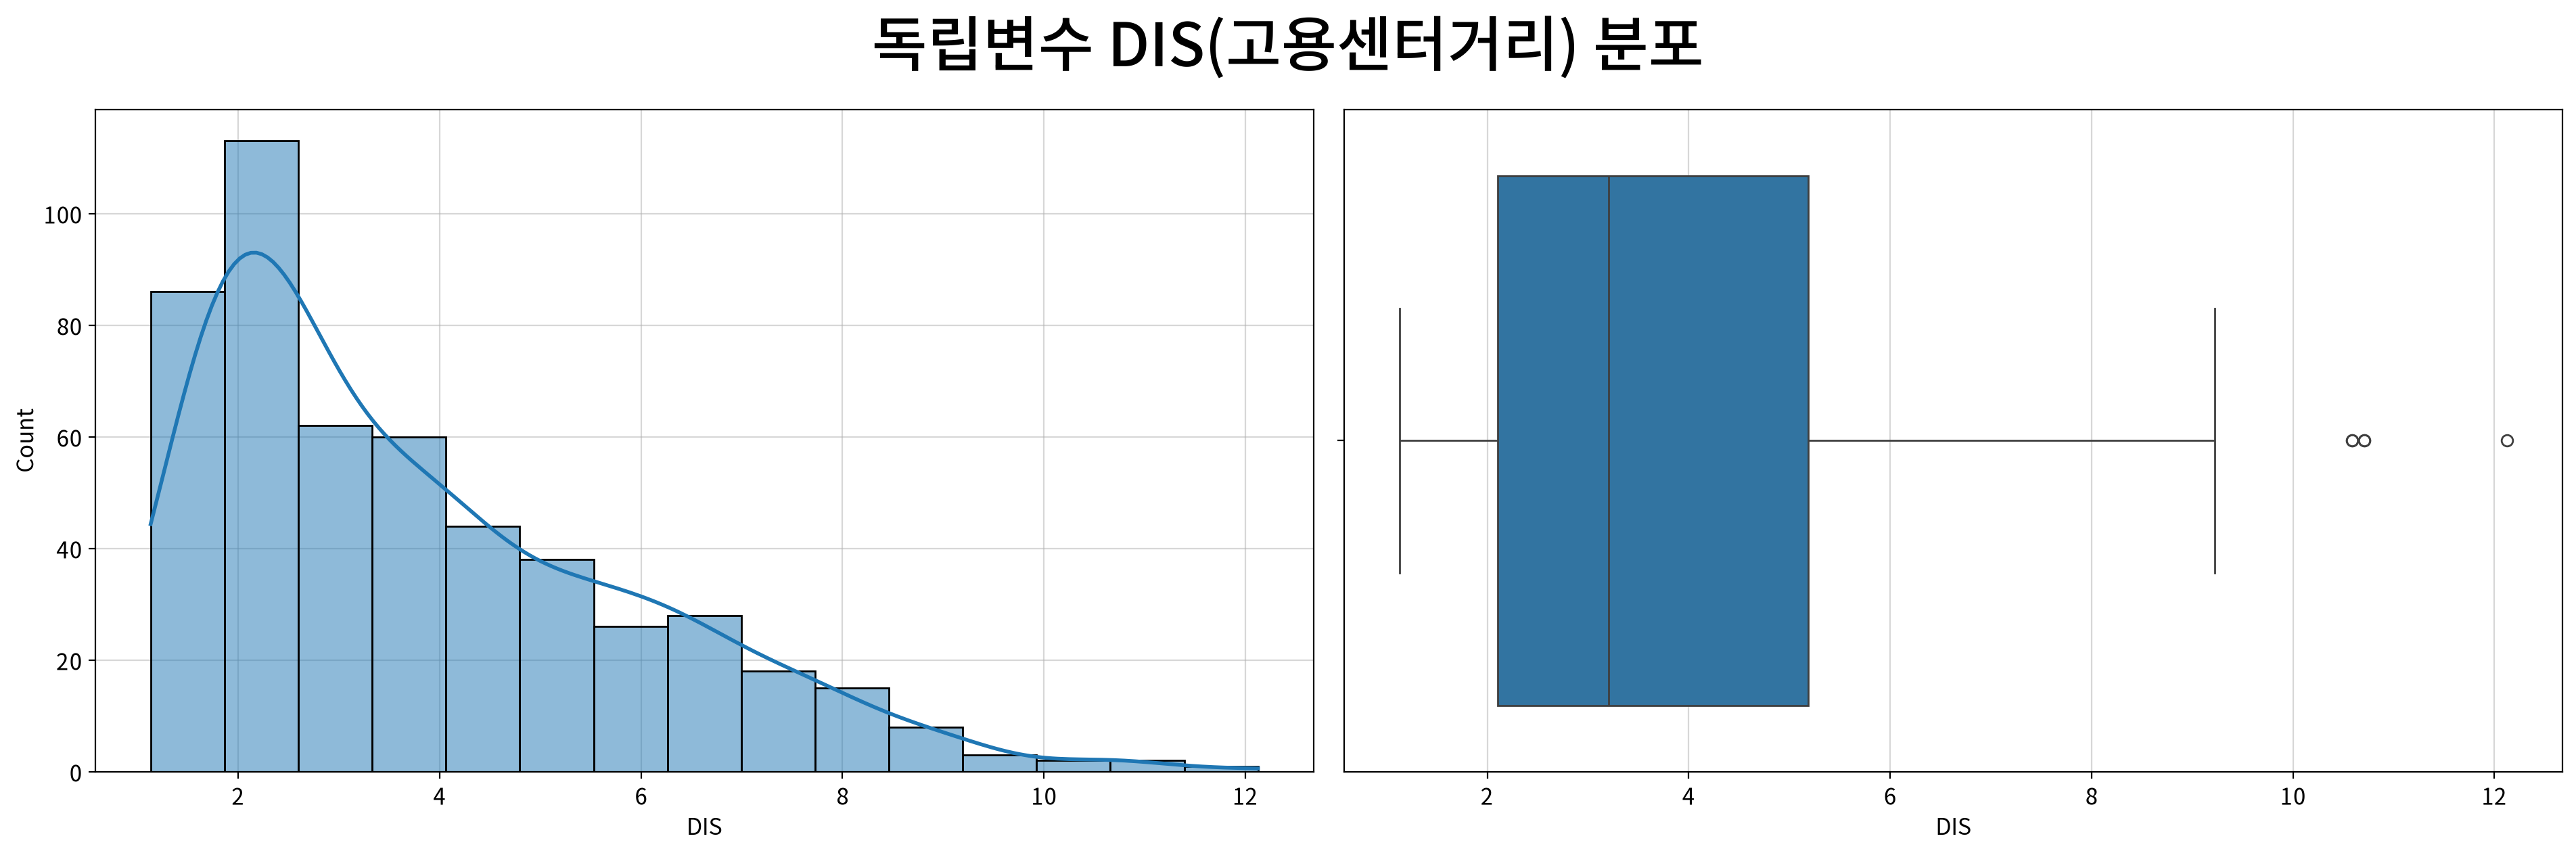

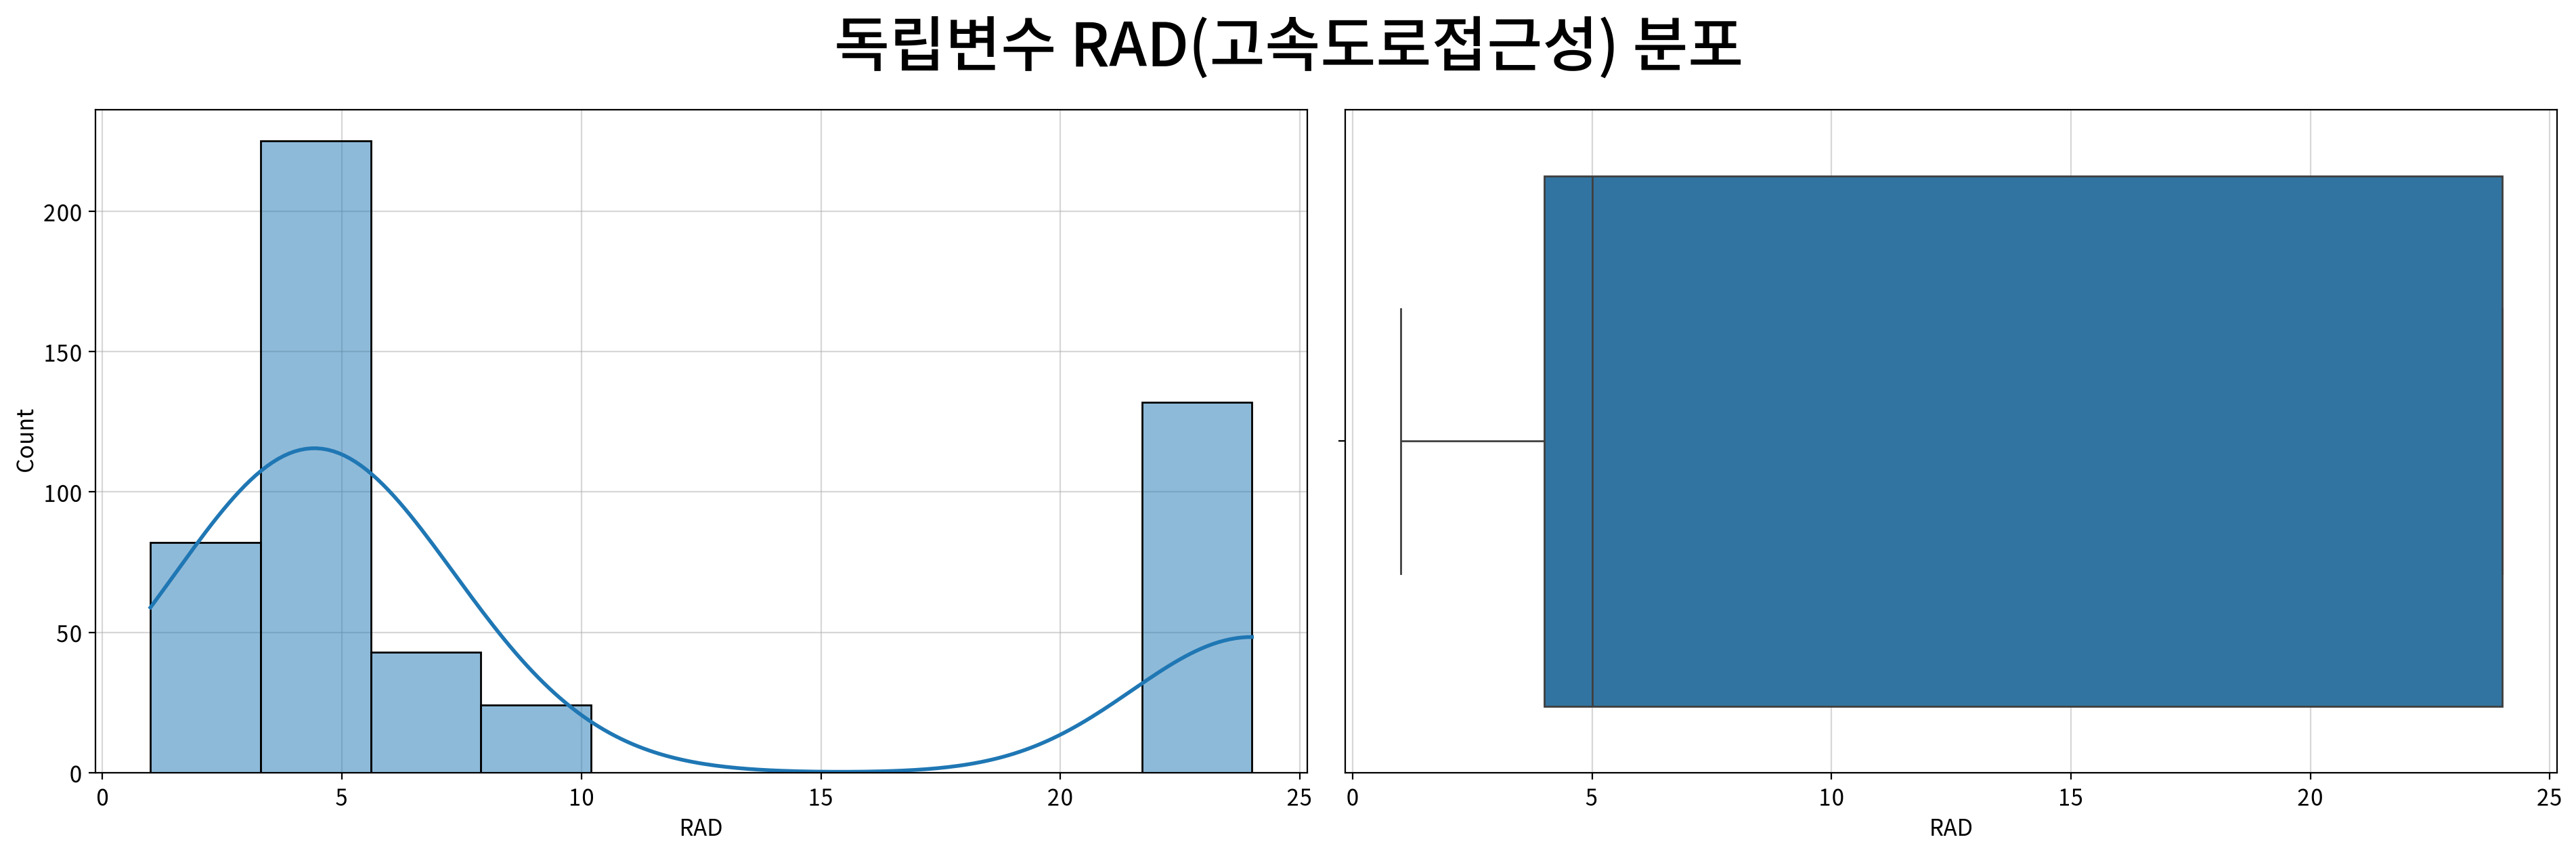

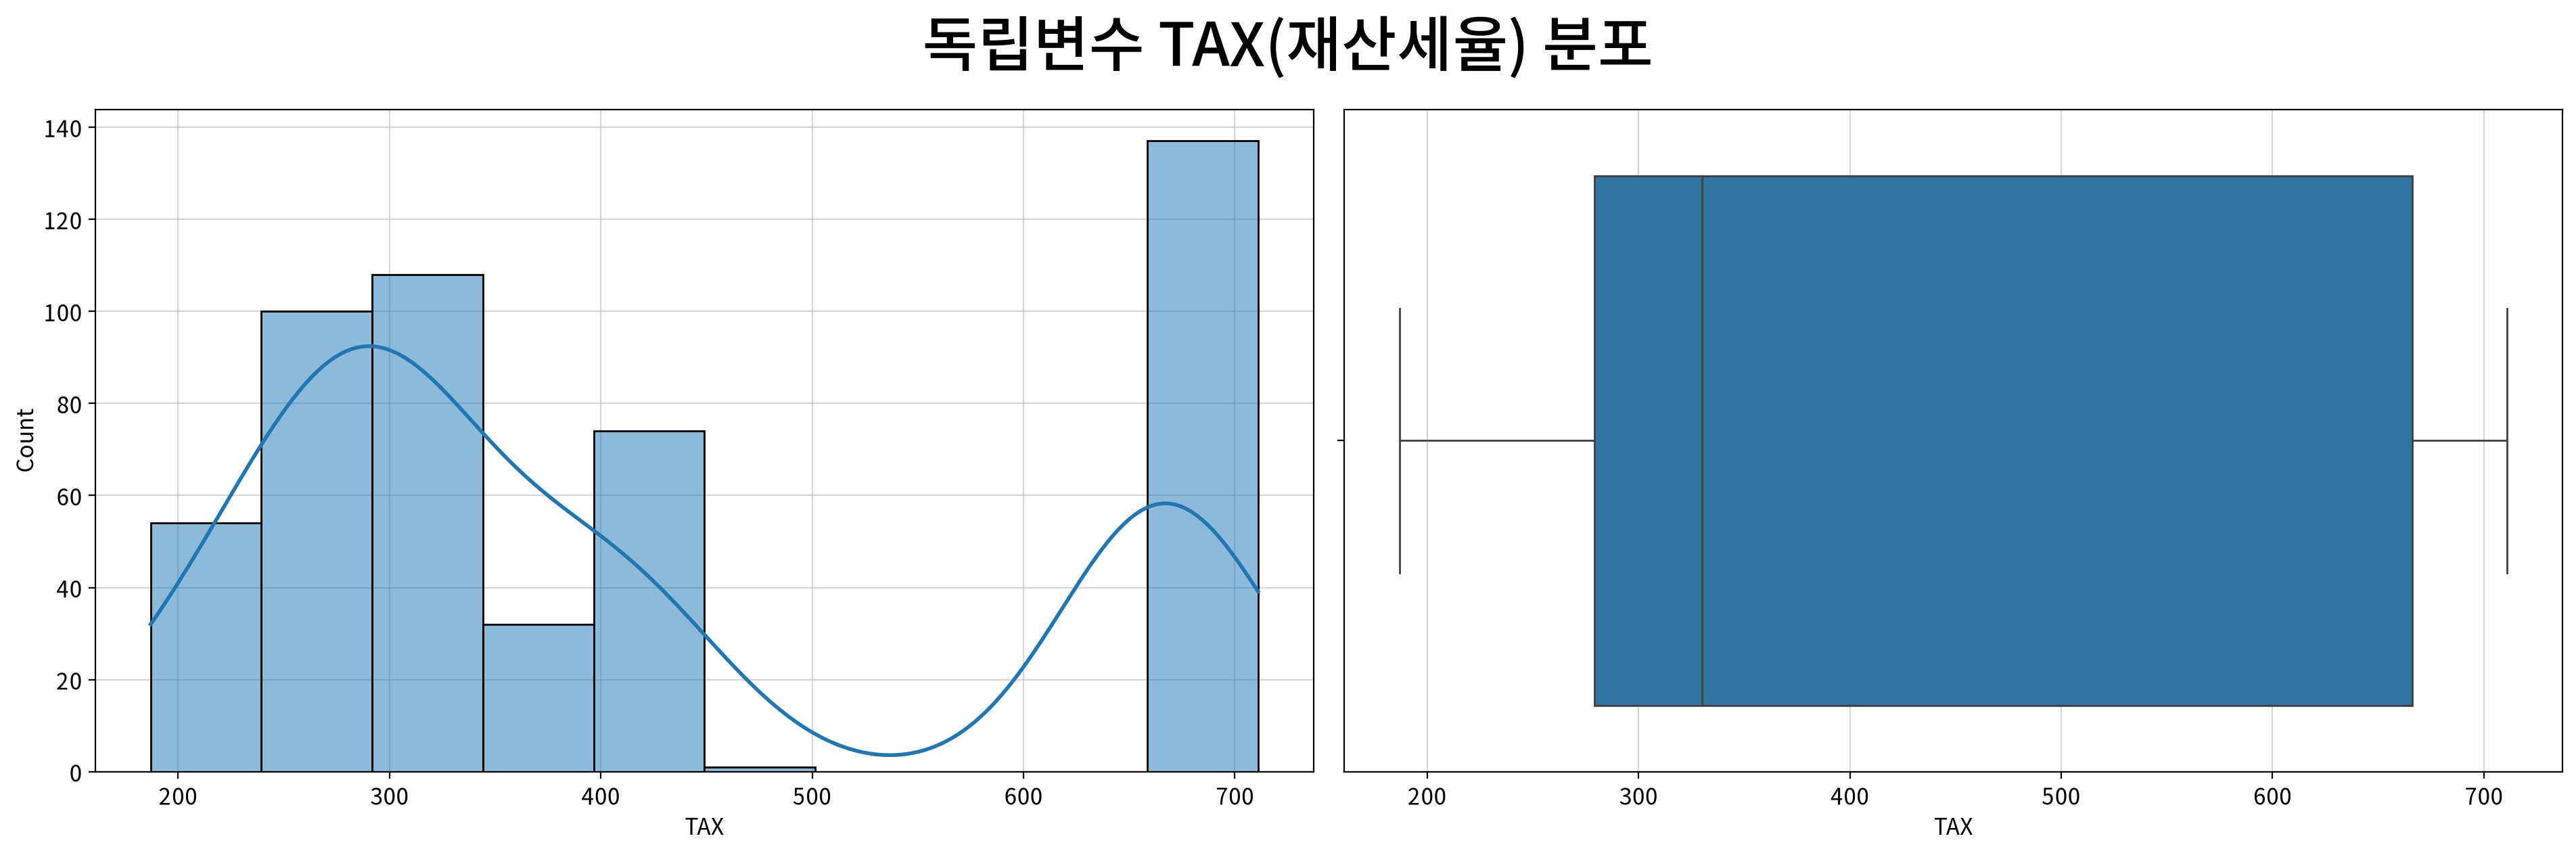

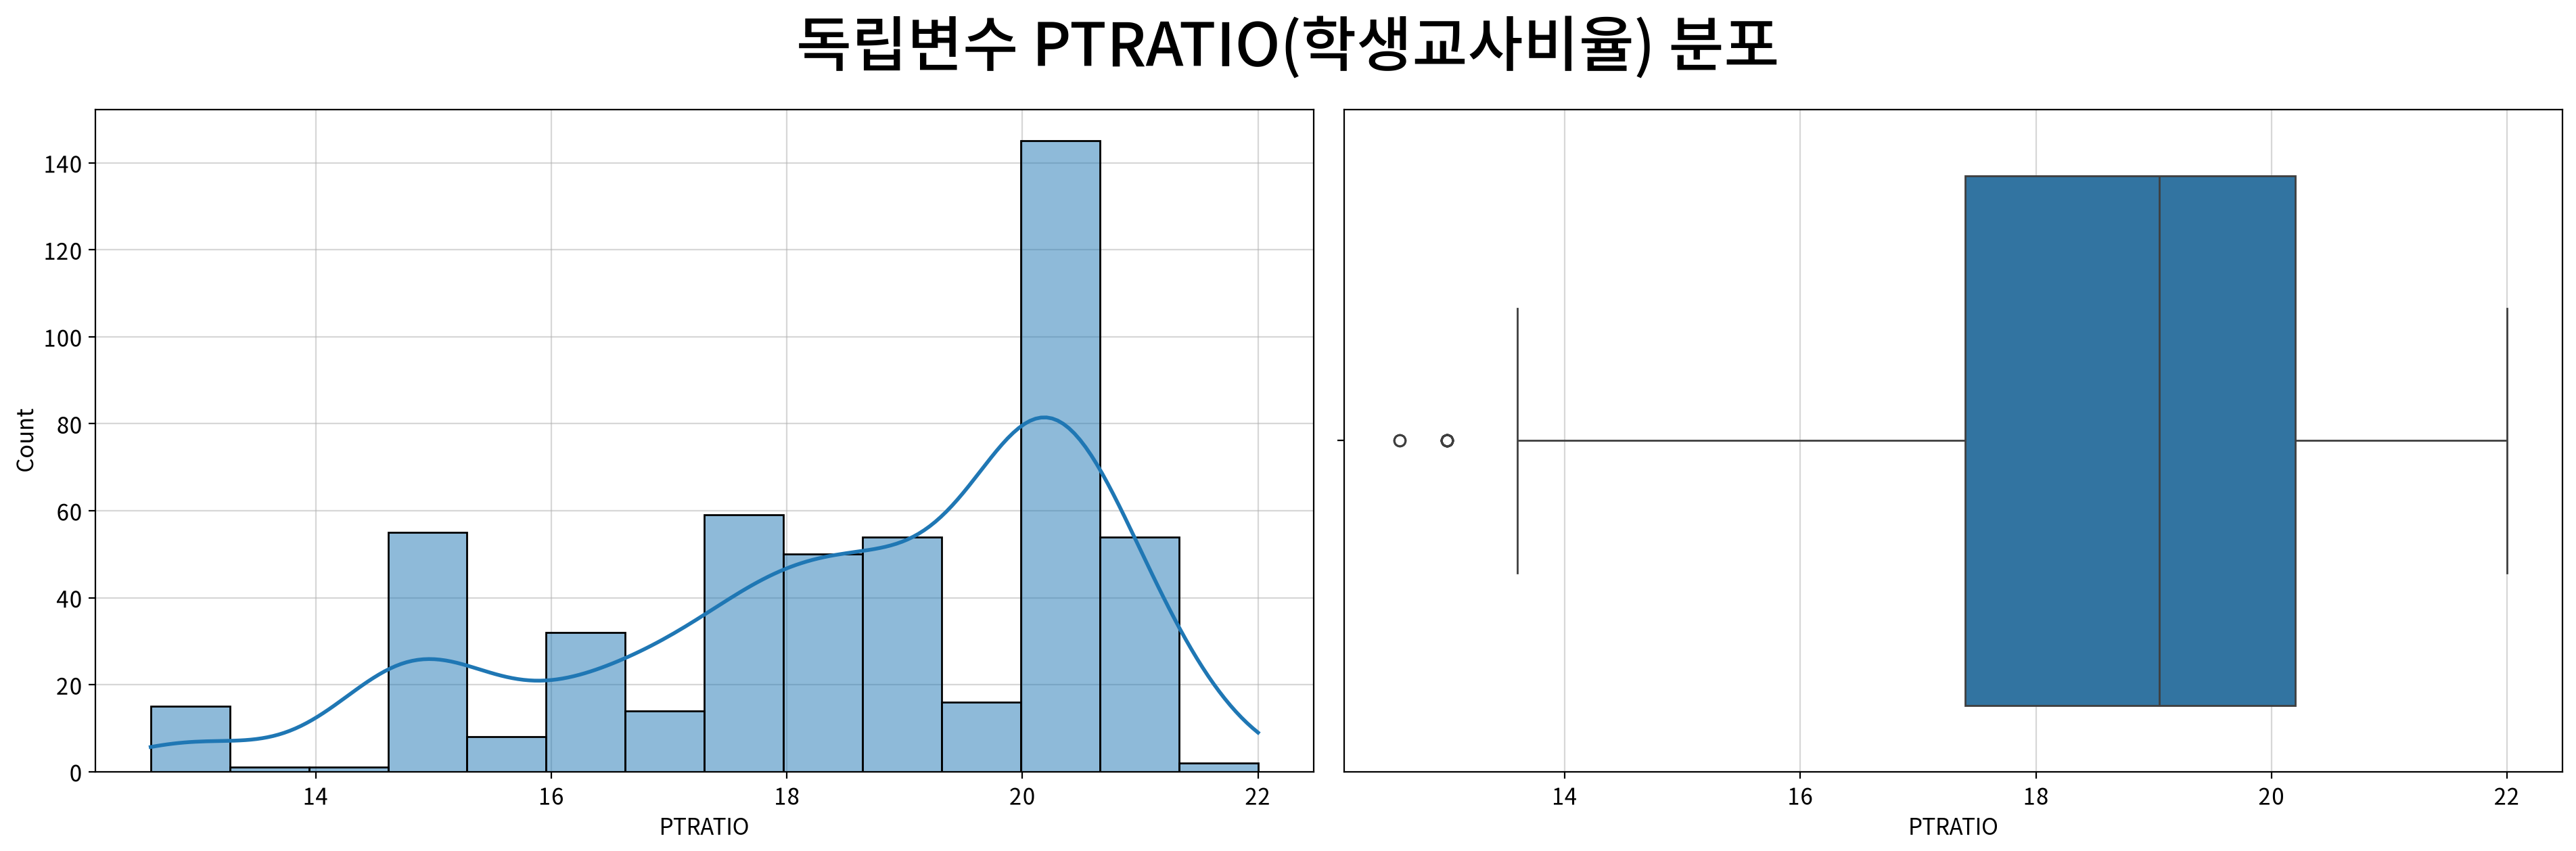

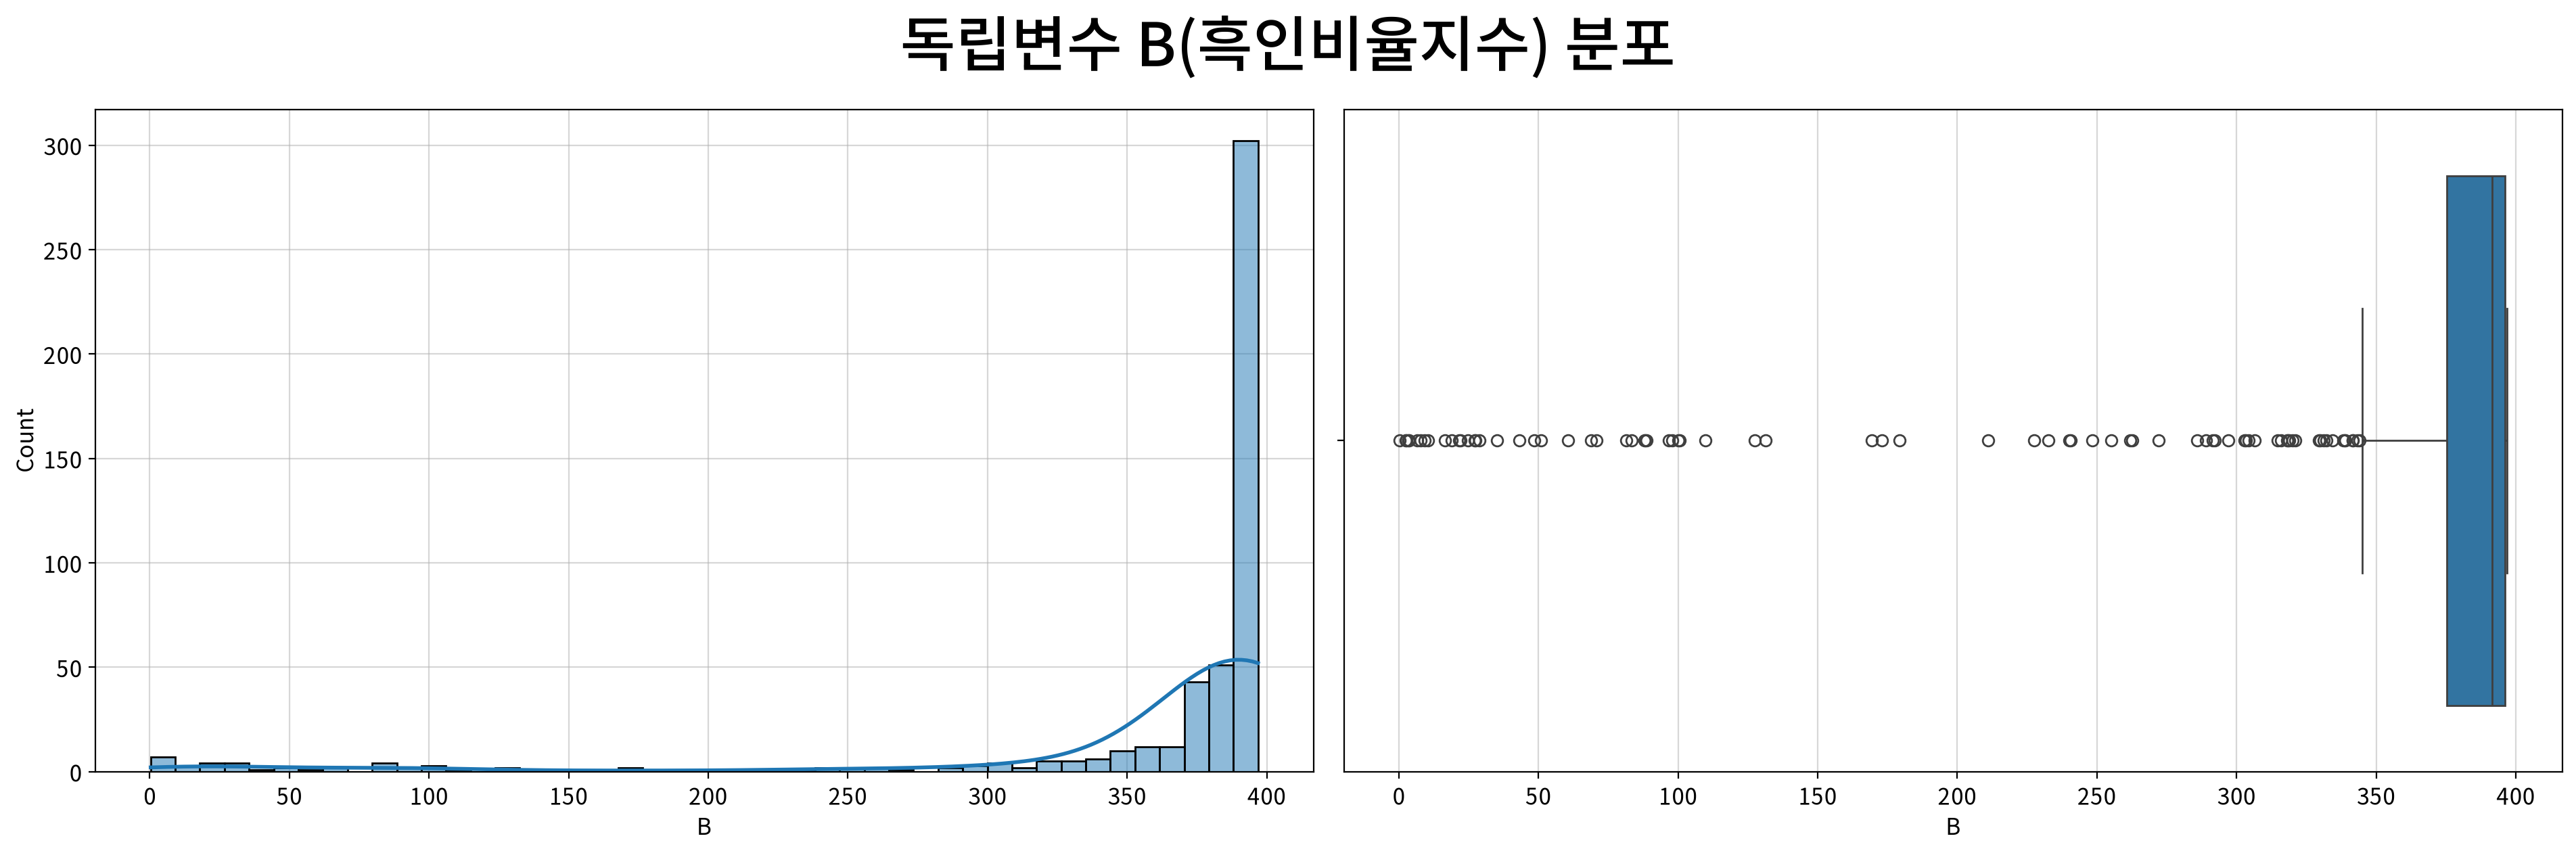

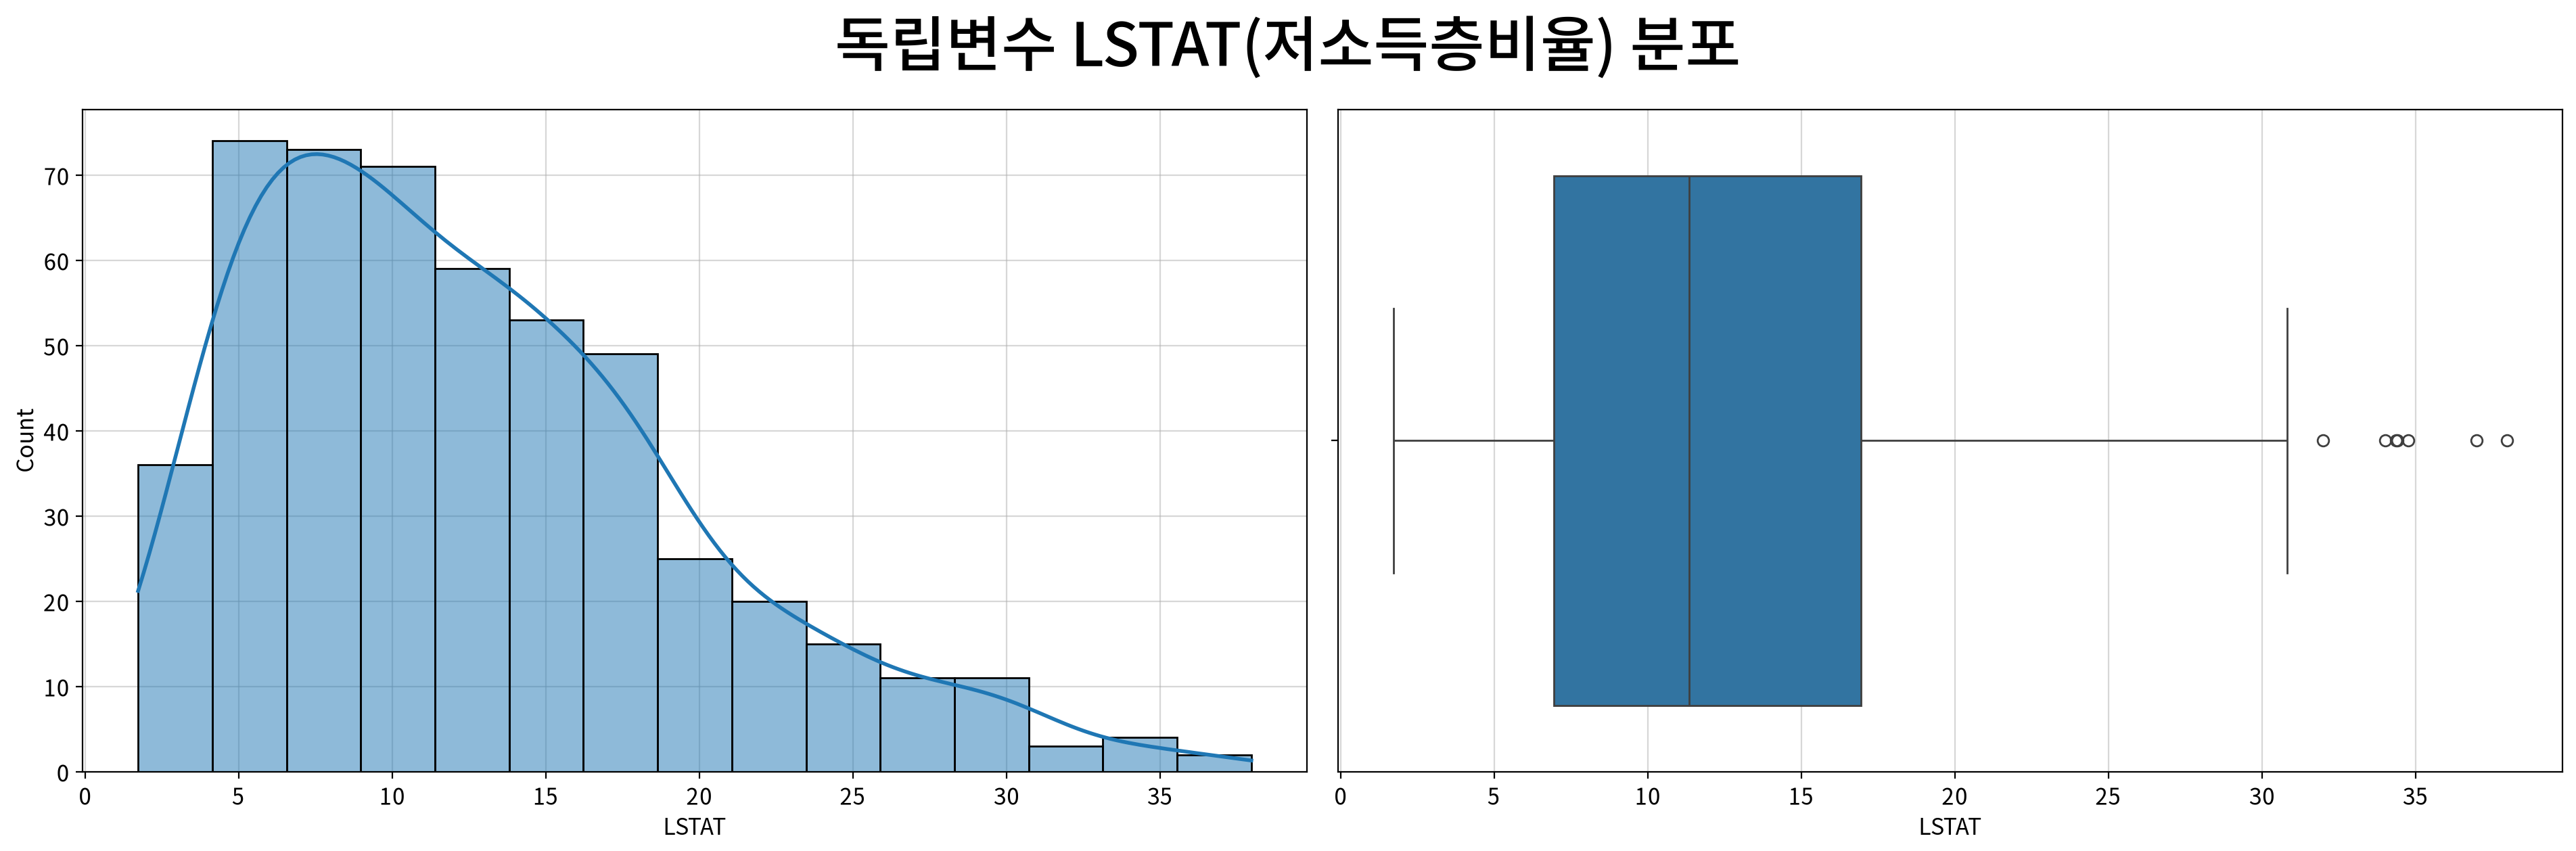

In [47]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

### (3) 명목형 독립변수 분포

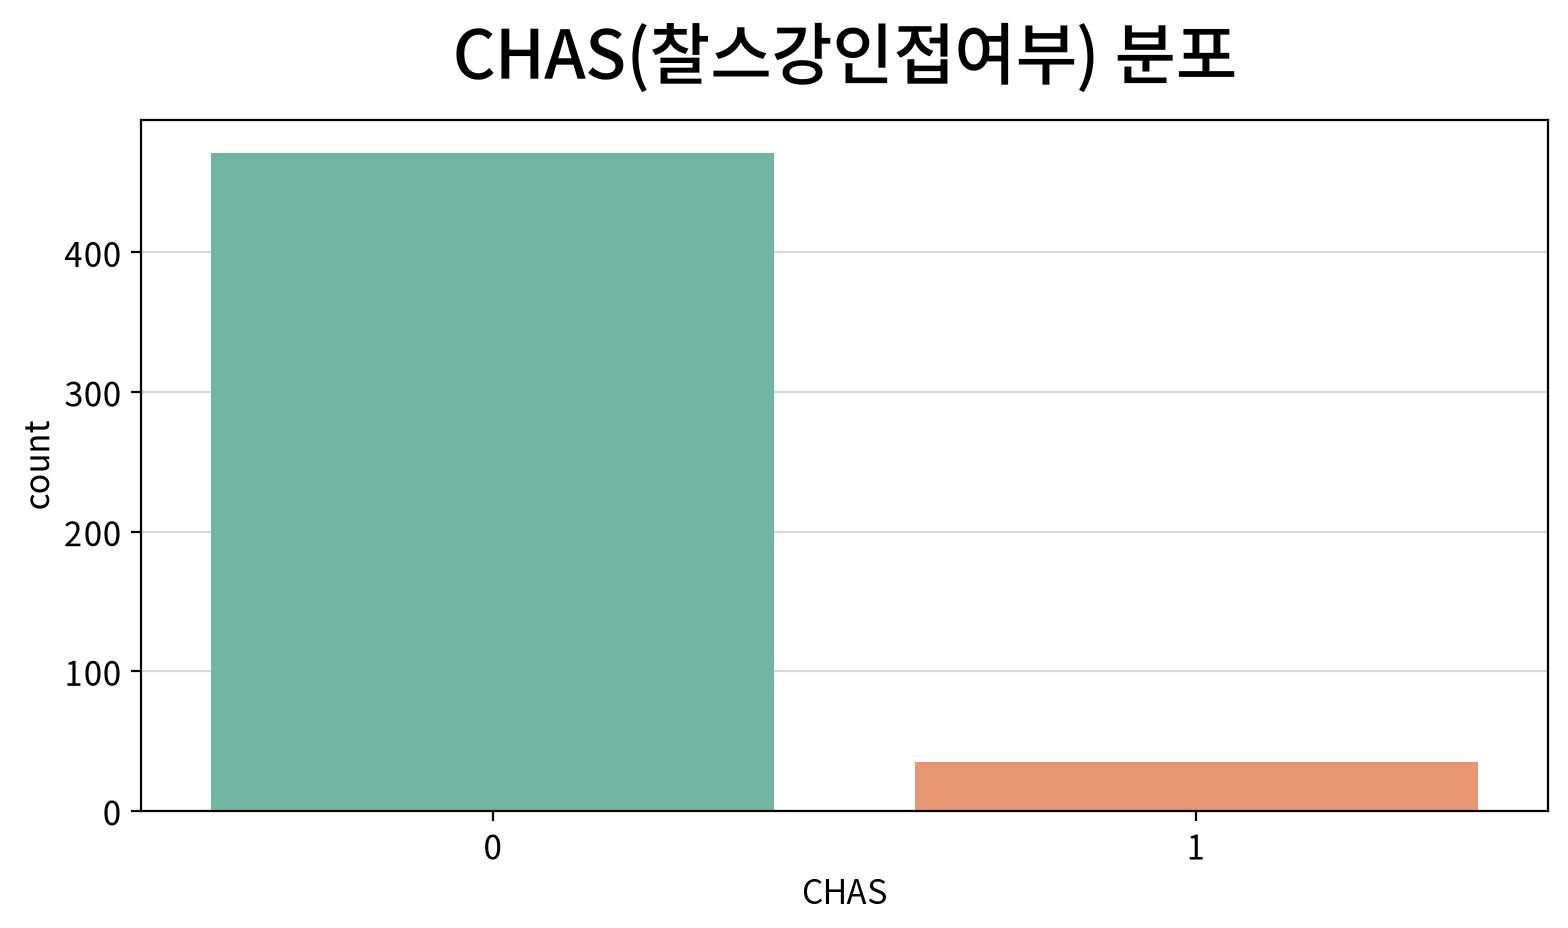

In [48]:
for n in nominal_cols:
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", width=800, height=480,
                      title=f"{n}({column_means[n]}) 분포")

> 💡 **인사이트 — 단변량**
>
> - `MEDV`는 우편향(왜도 1.11)이고 오른쪽 끝 50에 막대가 솟아 있다 — 앞에서 확인한 **상한 효과**가 그래프에서도 보인다.
> - 그래프와 기술통계를 함께 보면, 모델 투입 전에 처리를 검토할 변수는 다음과 같다.
>
> | 변수 | 그래프 모양 | 이상치 비율 | 처리 방향 |
> |---|---|---|---|
> | `MEDV` | 20 전후에 몰린 우편향 + 오른쪽 끝 50에 솟은 막대 (왜도 1.11) | 7.9% (상단 7.5%, 하단 0.4%) | **log** |
> | `CRIM` | 0 근처에 몰린 극단적 우편향 (왜도 5.22) | 13.0% | **log** |
> | `ZN` | 대부분 0 근처에 몰리고, 일부만 큰 값 (왜도 2.23) | 13.4% | **log1p** (0 포함) |
> | `B` | 오른쪽 끝에 몰리고 왼쪽으로 긴 꼬리 (왜도 −2.89) | 15.2% (하단) | **반사 후 log1p** |
> | `DIS` · `LSTAT` | 완만한 우편향 (왜도 1.01 · 0.91) | 1.0% · 1.4% | **log** |
> | `RAD` · `TAX` | 한쪽 끝에 큰 덩어리가 따로 떨어진 **이봉** | 0% | `RAD`는 **log**, `TAX`는 그대로 — 연속형이지만 값이 고르게 퍼져 있지 않아, 회귀계수를 해석할 때 주의가 필요 |
> | `RM` | 대칭에 가깝지만 양쪽 꼬리가 길다 (첨도 1.89) | 5.9% | 그대로 (변환 불필요) |
>
> - `MEDV`의 상단 이상치에는 상한 50에 걸린 16건이 포함돼 있다. 입력 오류가 아니라 **잘린 값**이라 제거하지 않고, PART 3의 민감도 분석에서 영향을 따로 확인한다.
> - 이상치 비율이 높은 `CRIM` · `ZN` · `B`는 모두 **로그 대상**이기도 하다. 로그로 꼬리를 먼저 누르면 IQR 경계를 벗어나는 값이 크게 줄어든다. 이상치를 따로 대체할 필요가 있는지는 PART 3의 `2_이상치대체` 체크포인트로 검증한다.
> - `CHAS`는 0 : 1 = 471 : 35로 **심한 불균형**이라, 집단 비교 시 소수 집단(35건)의 검정력이 낮을 수 있다.

## 2-2. 이변량 분석 — 각 독립변수가 종속변수를 설명하는가?

### (1) 연속형 × 연속형 : 상관분석

- 정규성 · 선형성 · 영향점을 점검해 **Pearson / Spearman을 자동 선택**한다.
- 채택 기준 : **유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)**

#### ▶︎ CRIM(범죄율) → MEDV

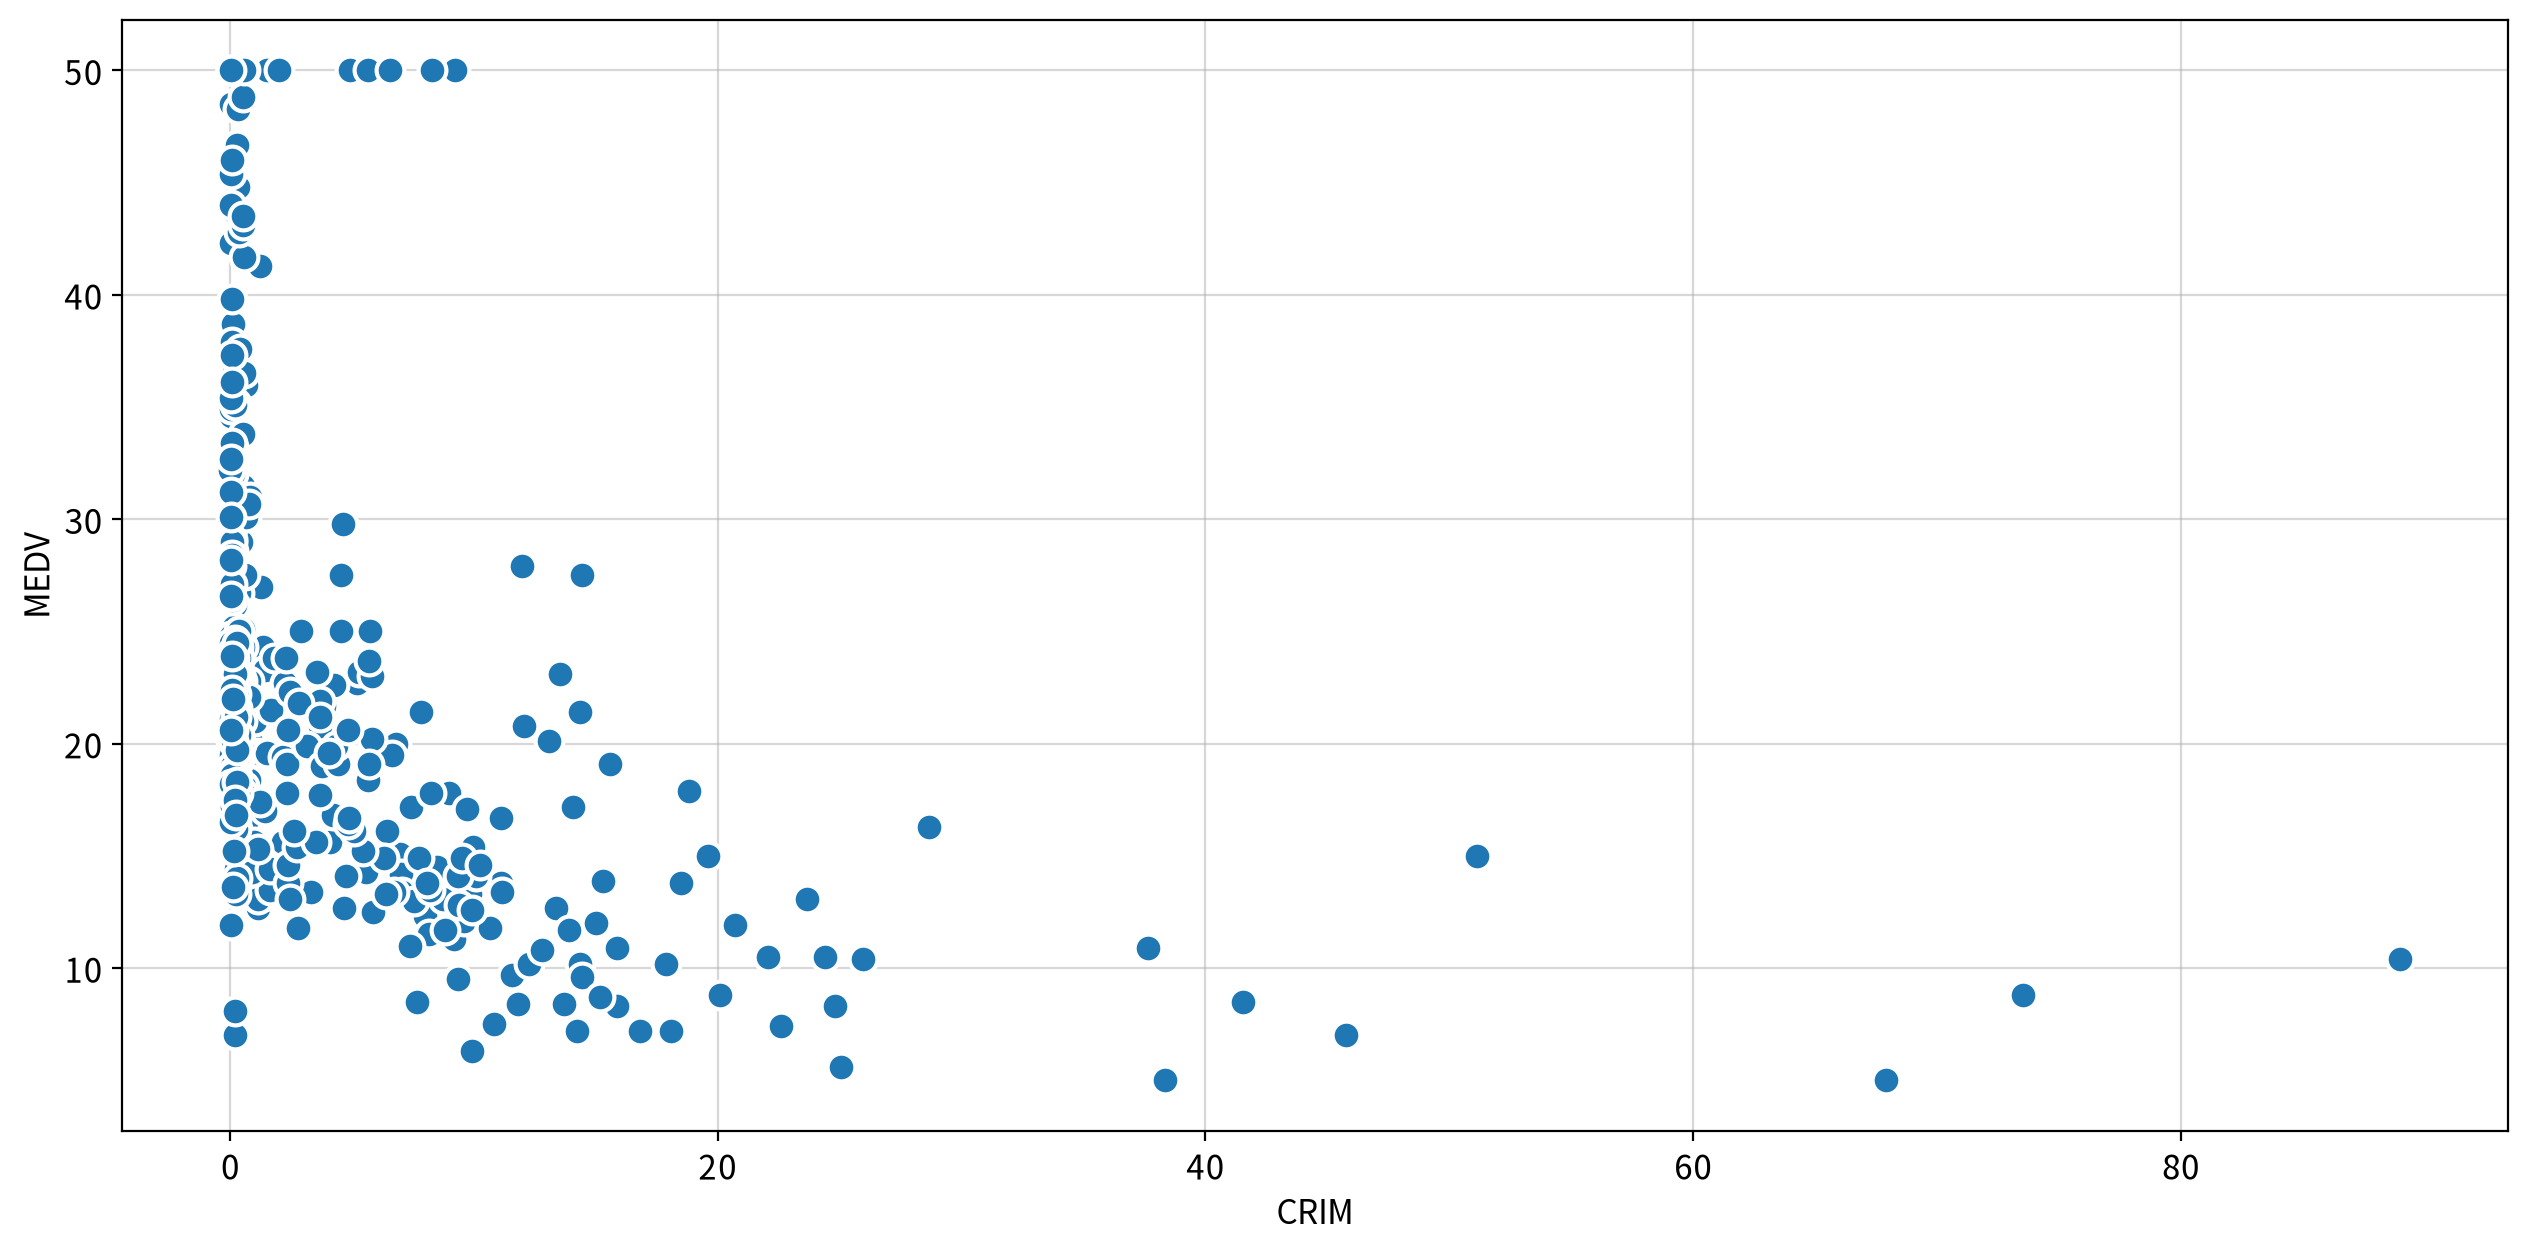

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
CRIM,MEDV,Spearman,-0.559,0.000,Moderate,True,False,False,False,False,True


#### ▶︎ ZN(대규모주거지비율) → MEDV

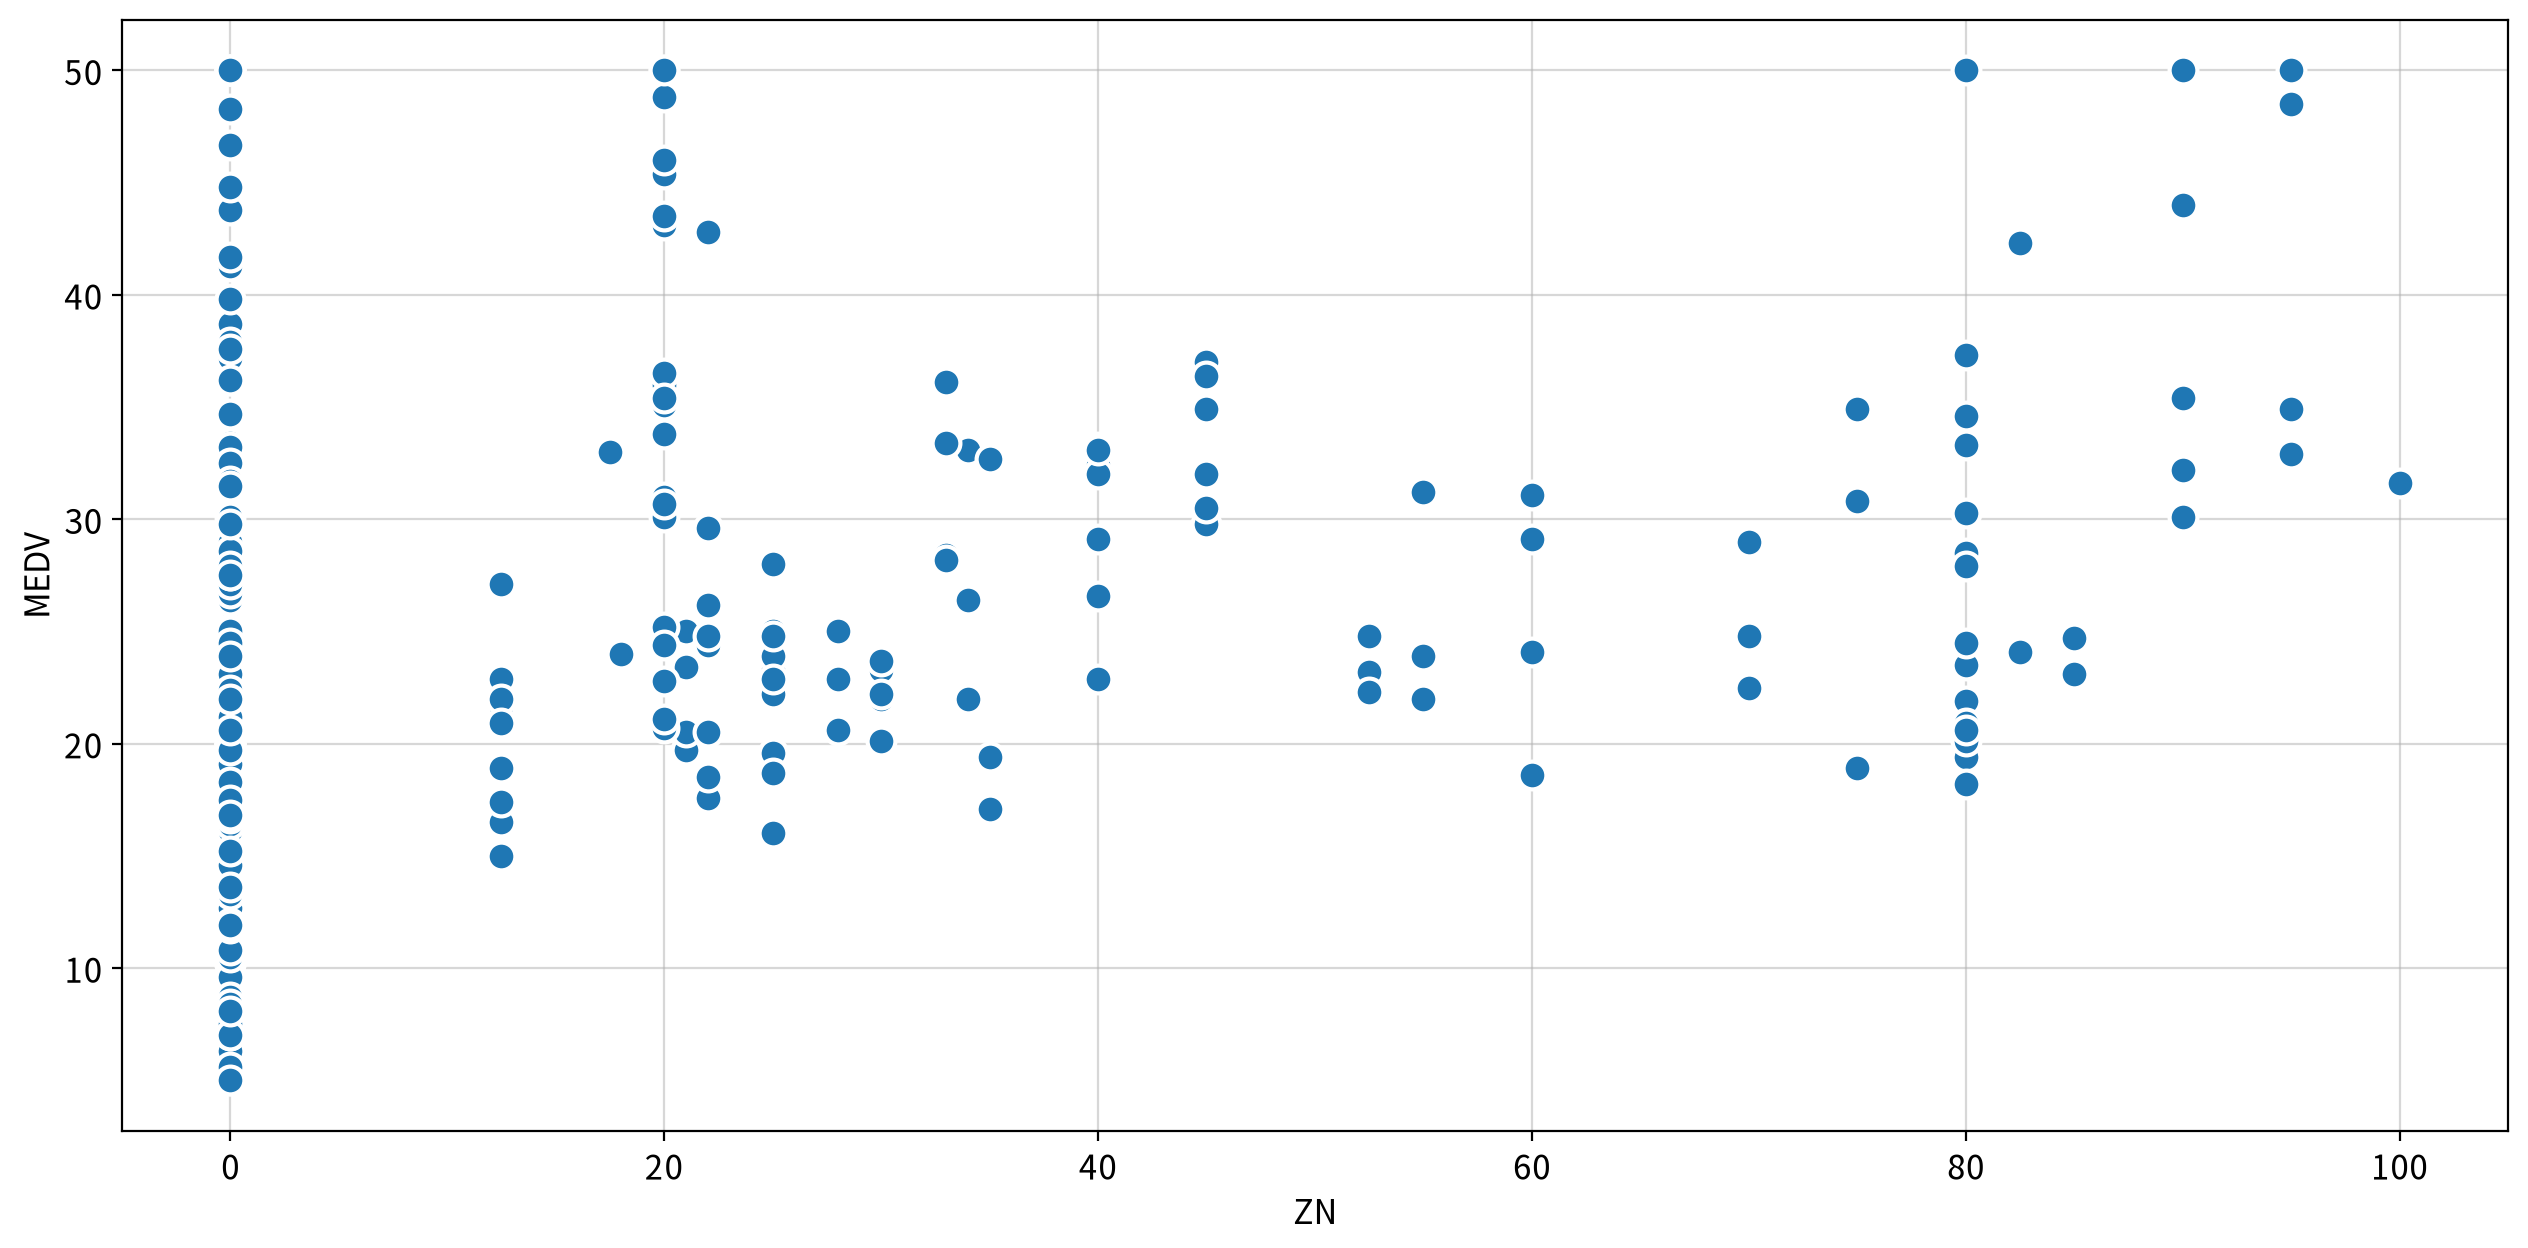

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
ZN,MEDV,Spearman,0.438,0.000,Moderate,True,False,False,False,False,True


#### ▶︎ INDUS(비소매상업지비율) → MEDV

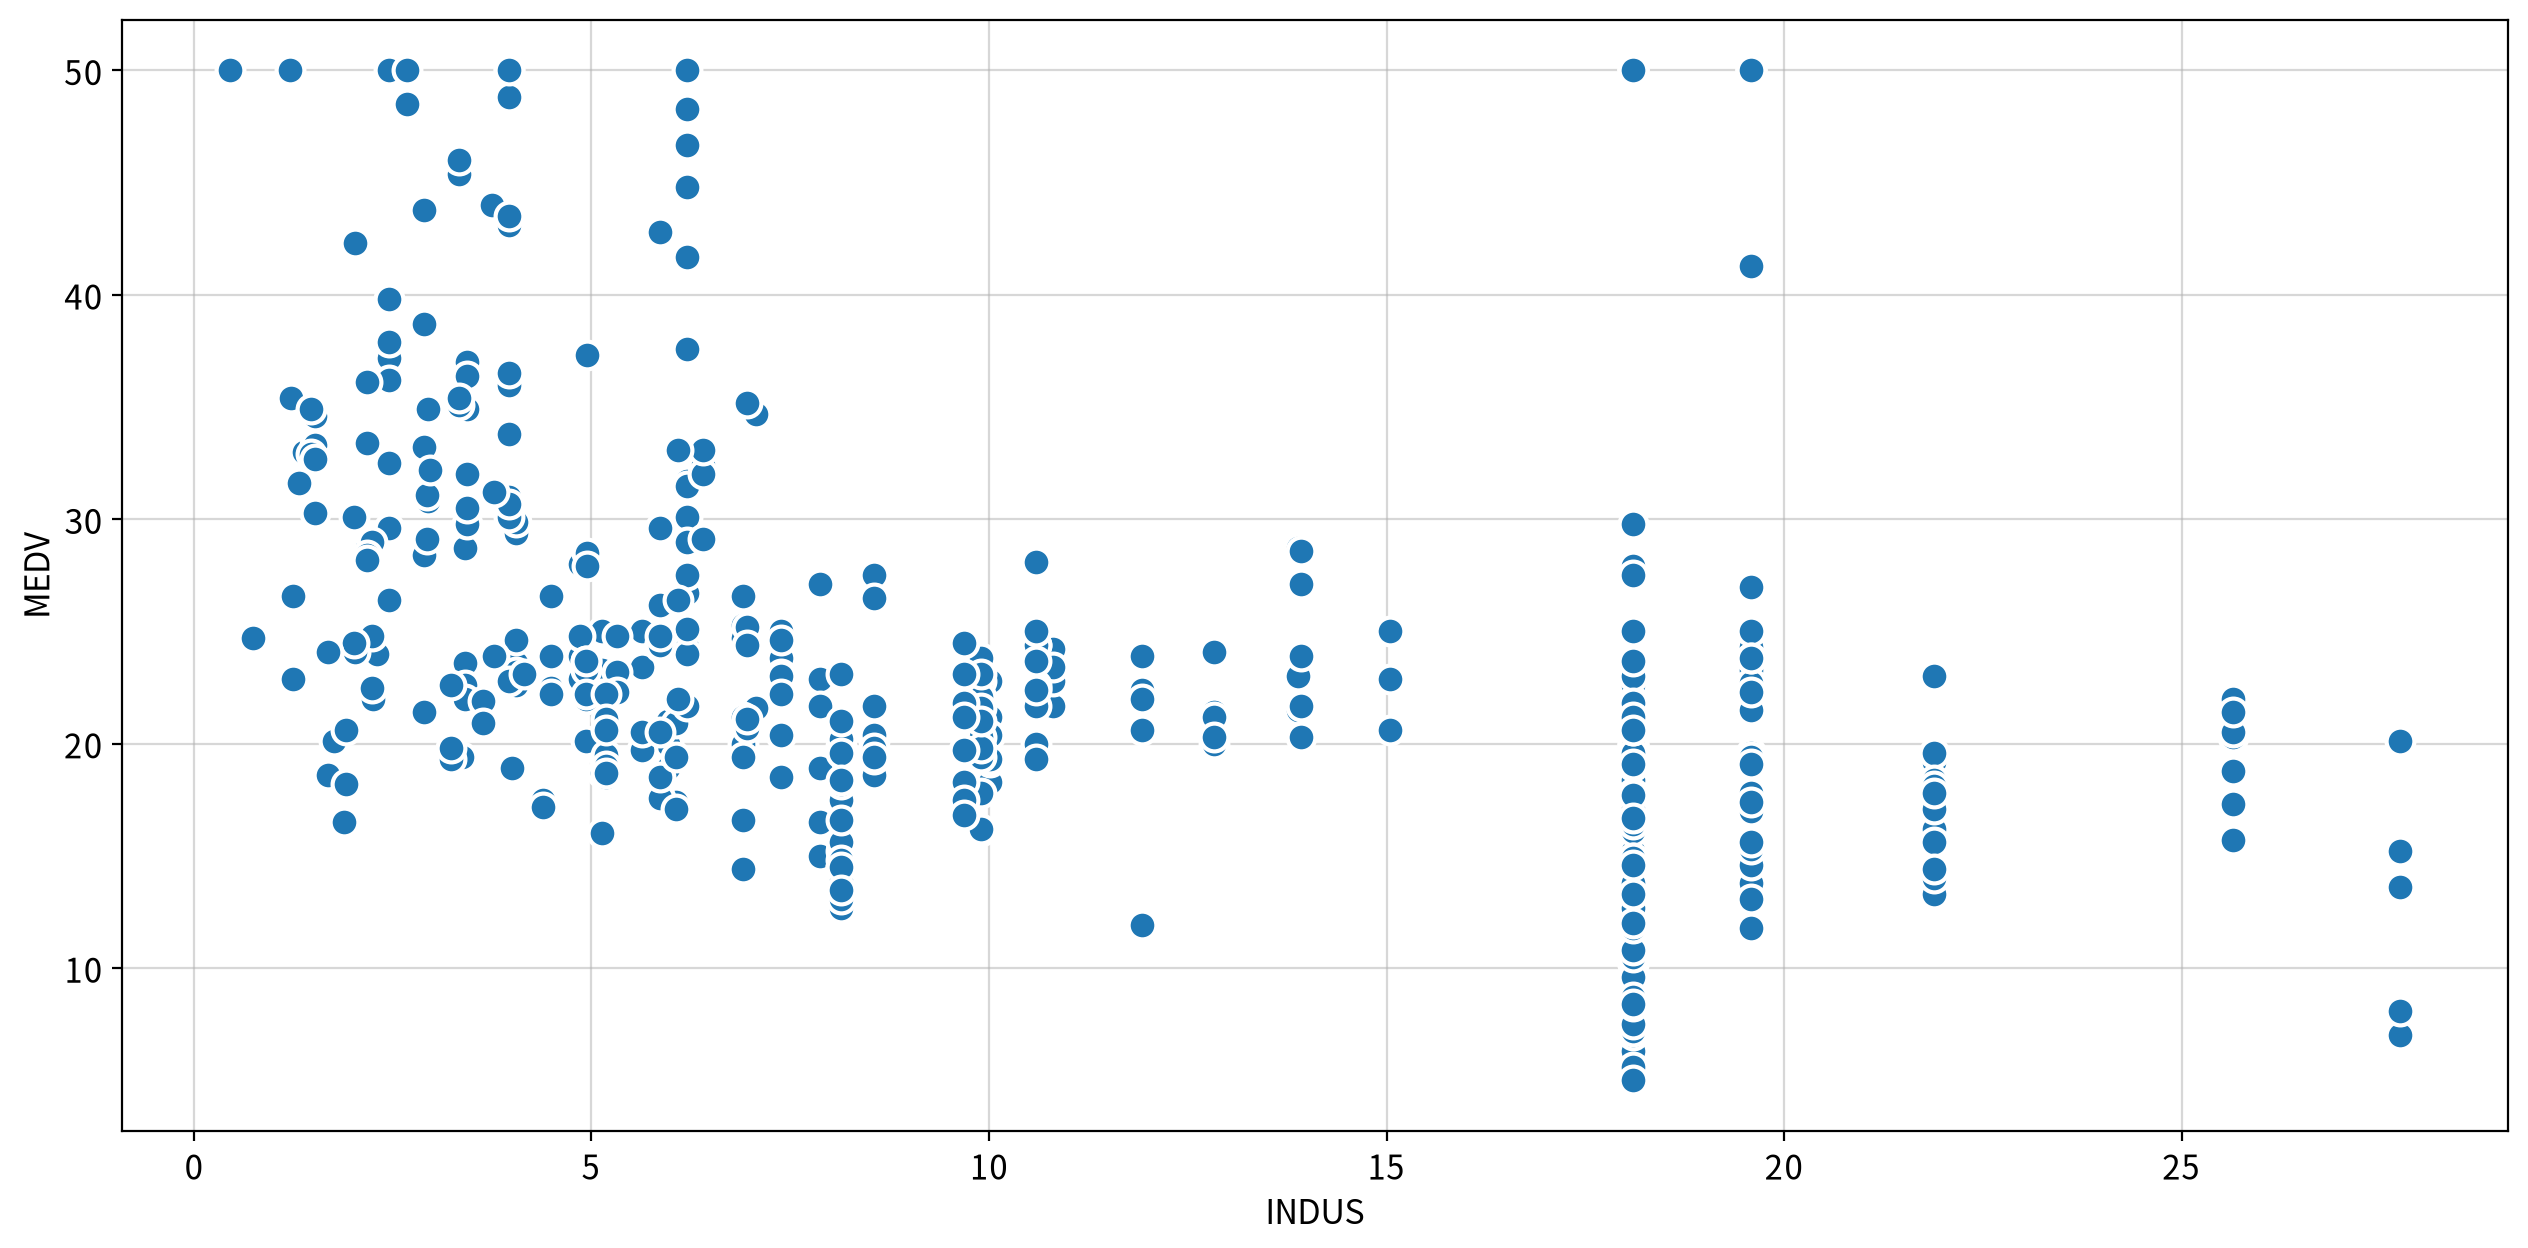

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
INDUS,MEDV,Spearman,-0.578,0.000,Moderate,True,False,False,False,True,True


#### ▶︎ NOX(대기오염도) → MEDV

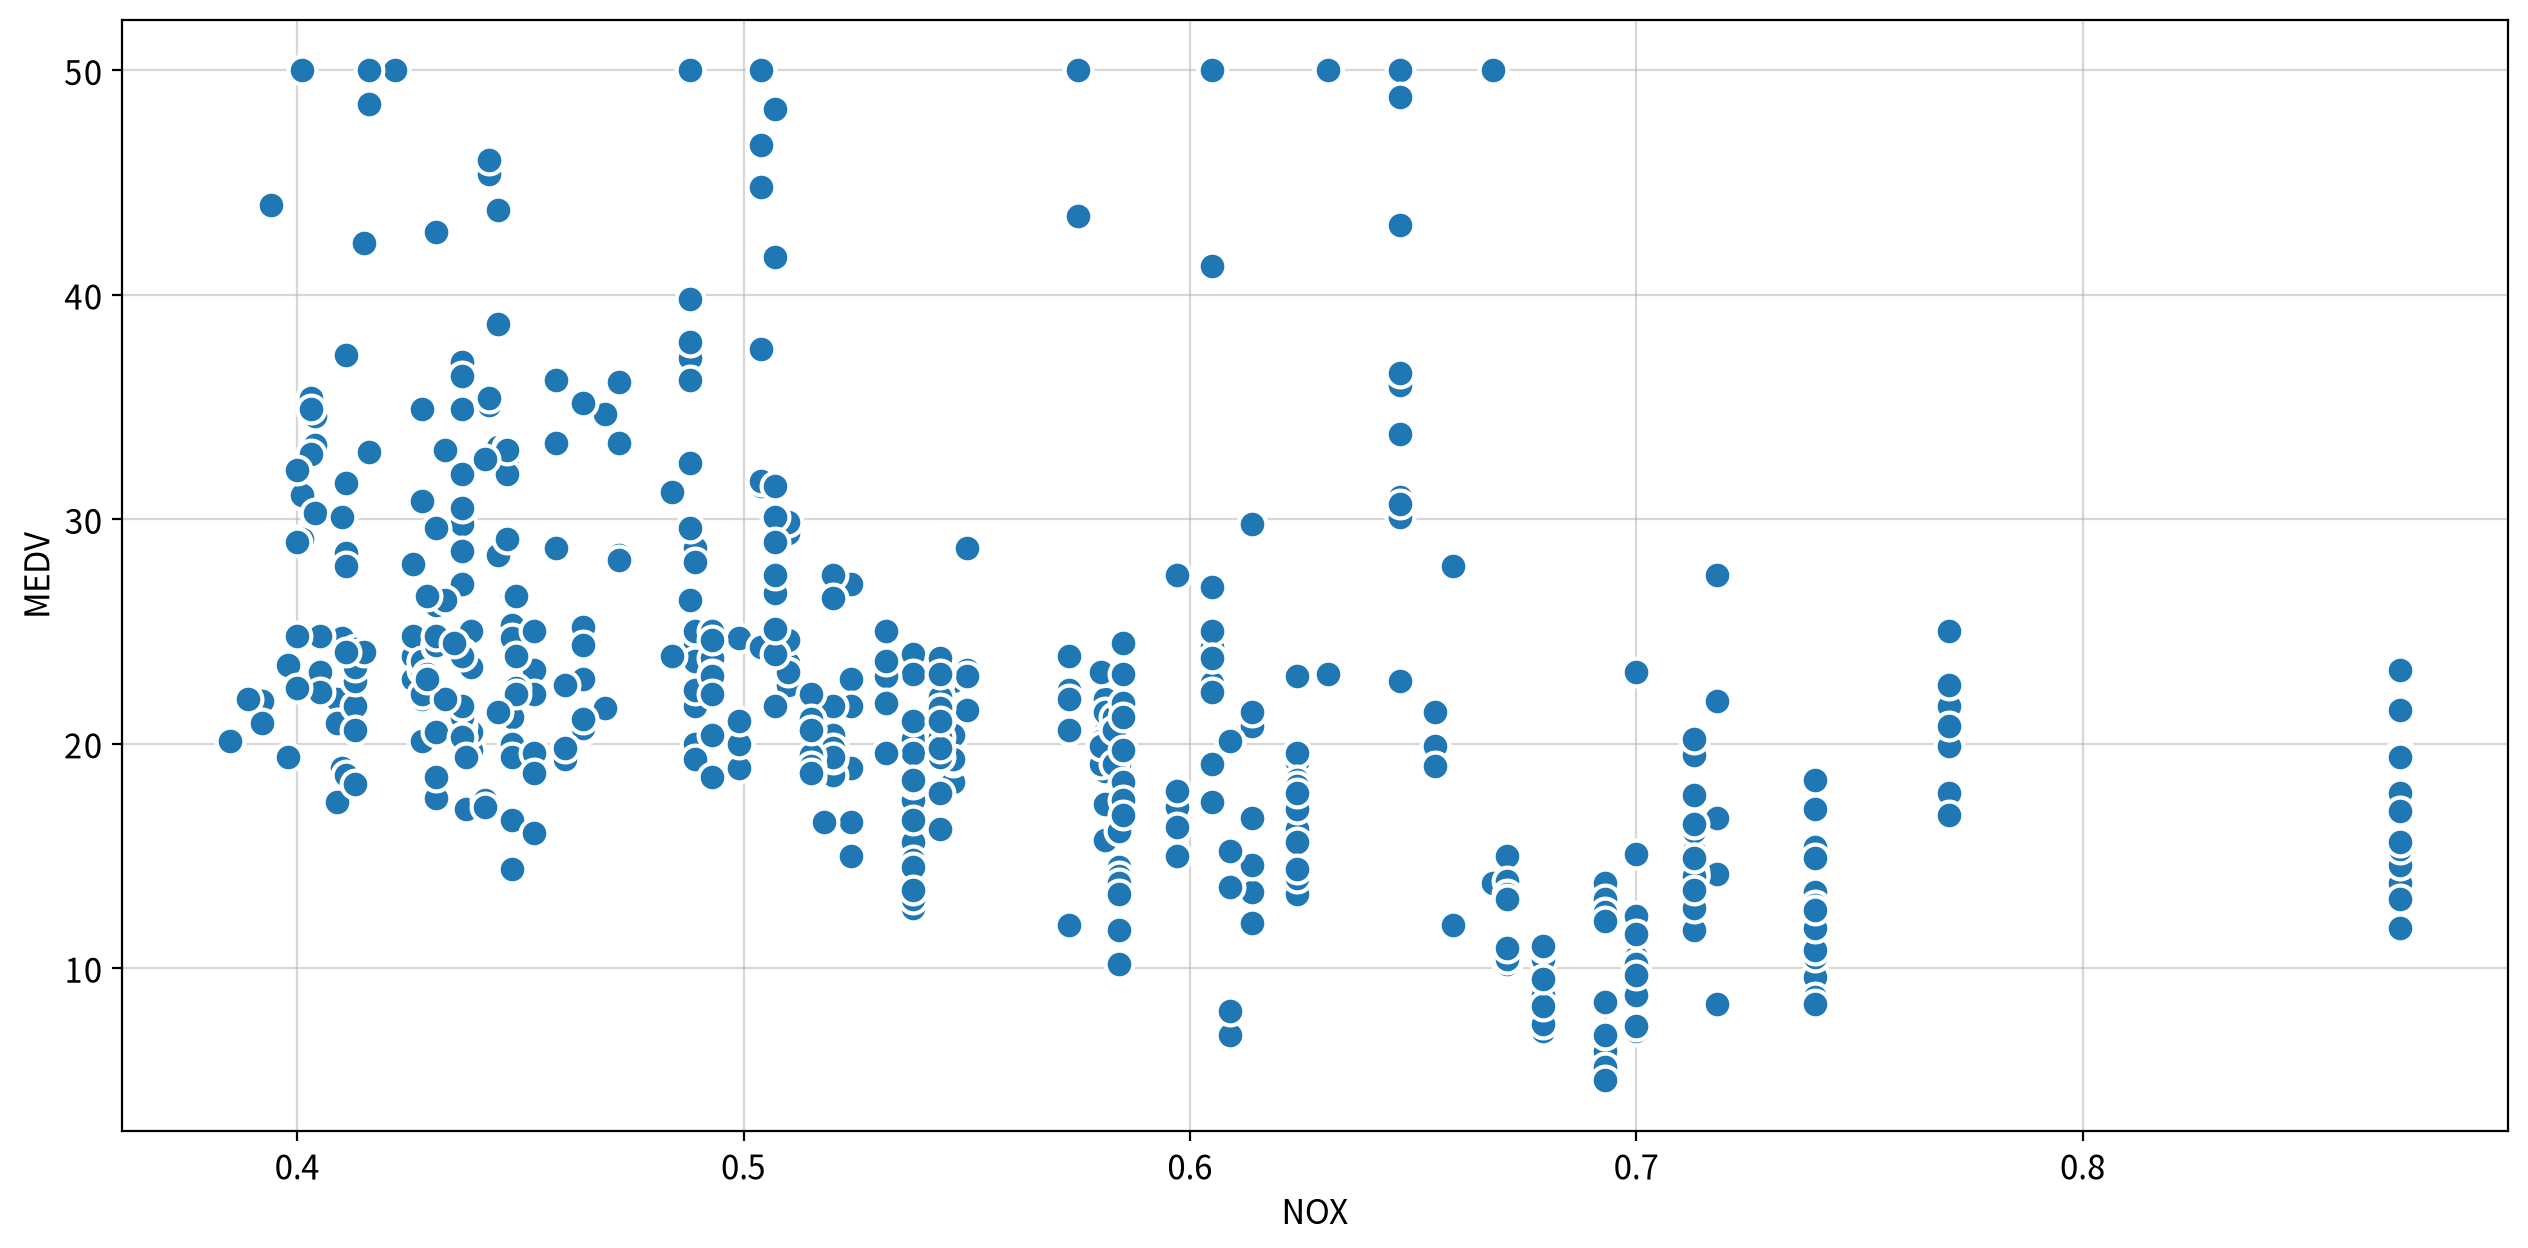

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
NOX,MEDV,Spearman,-0.563,0.000,Moderate,True,False,False,True,True,True


#### ▶︎ RM(평균방수) → MEDV

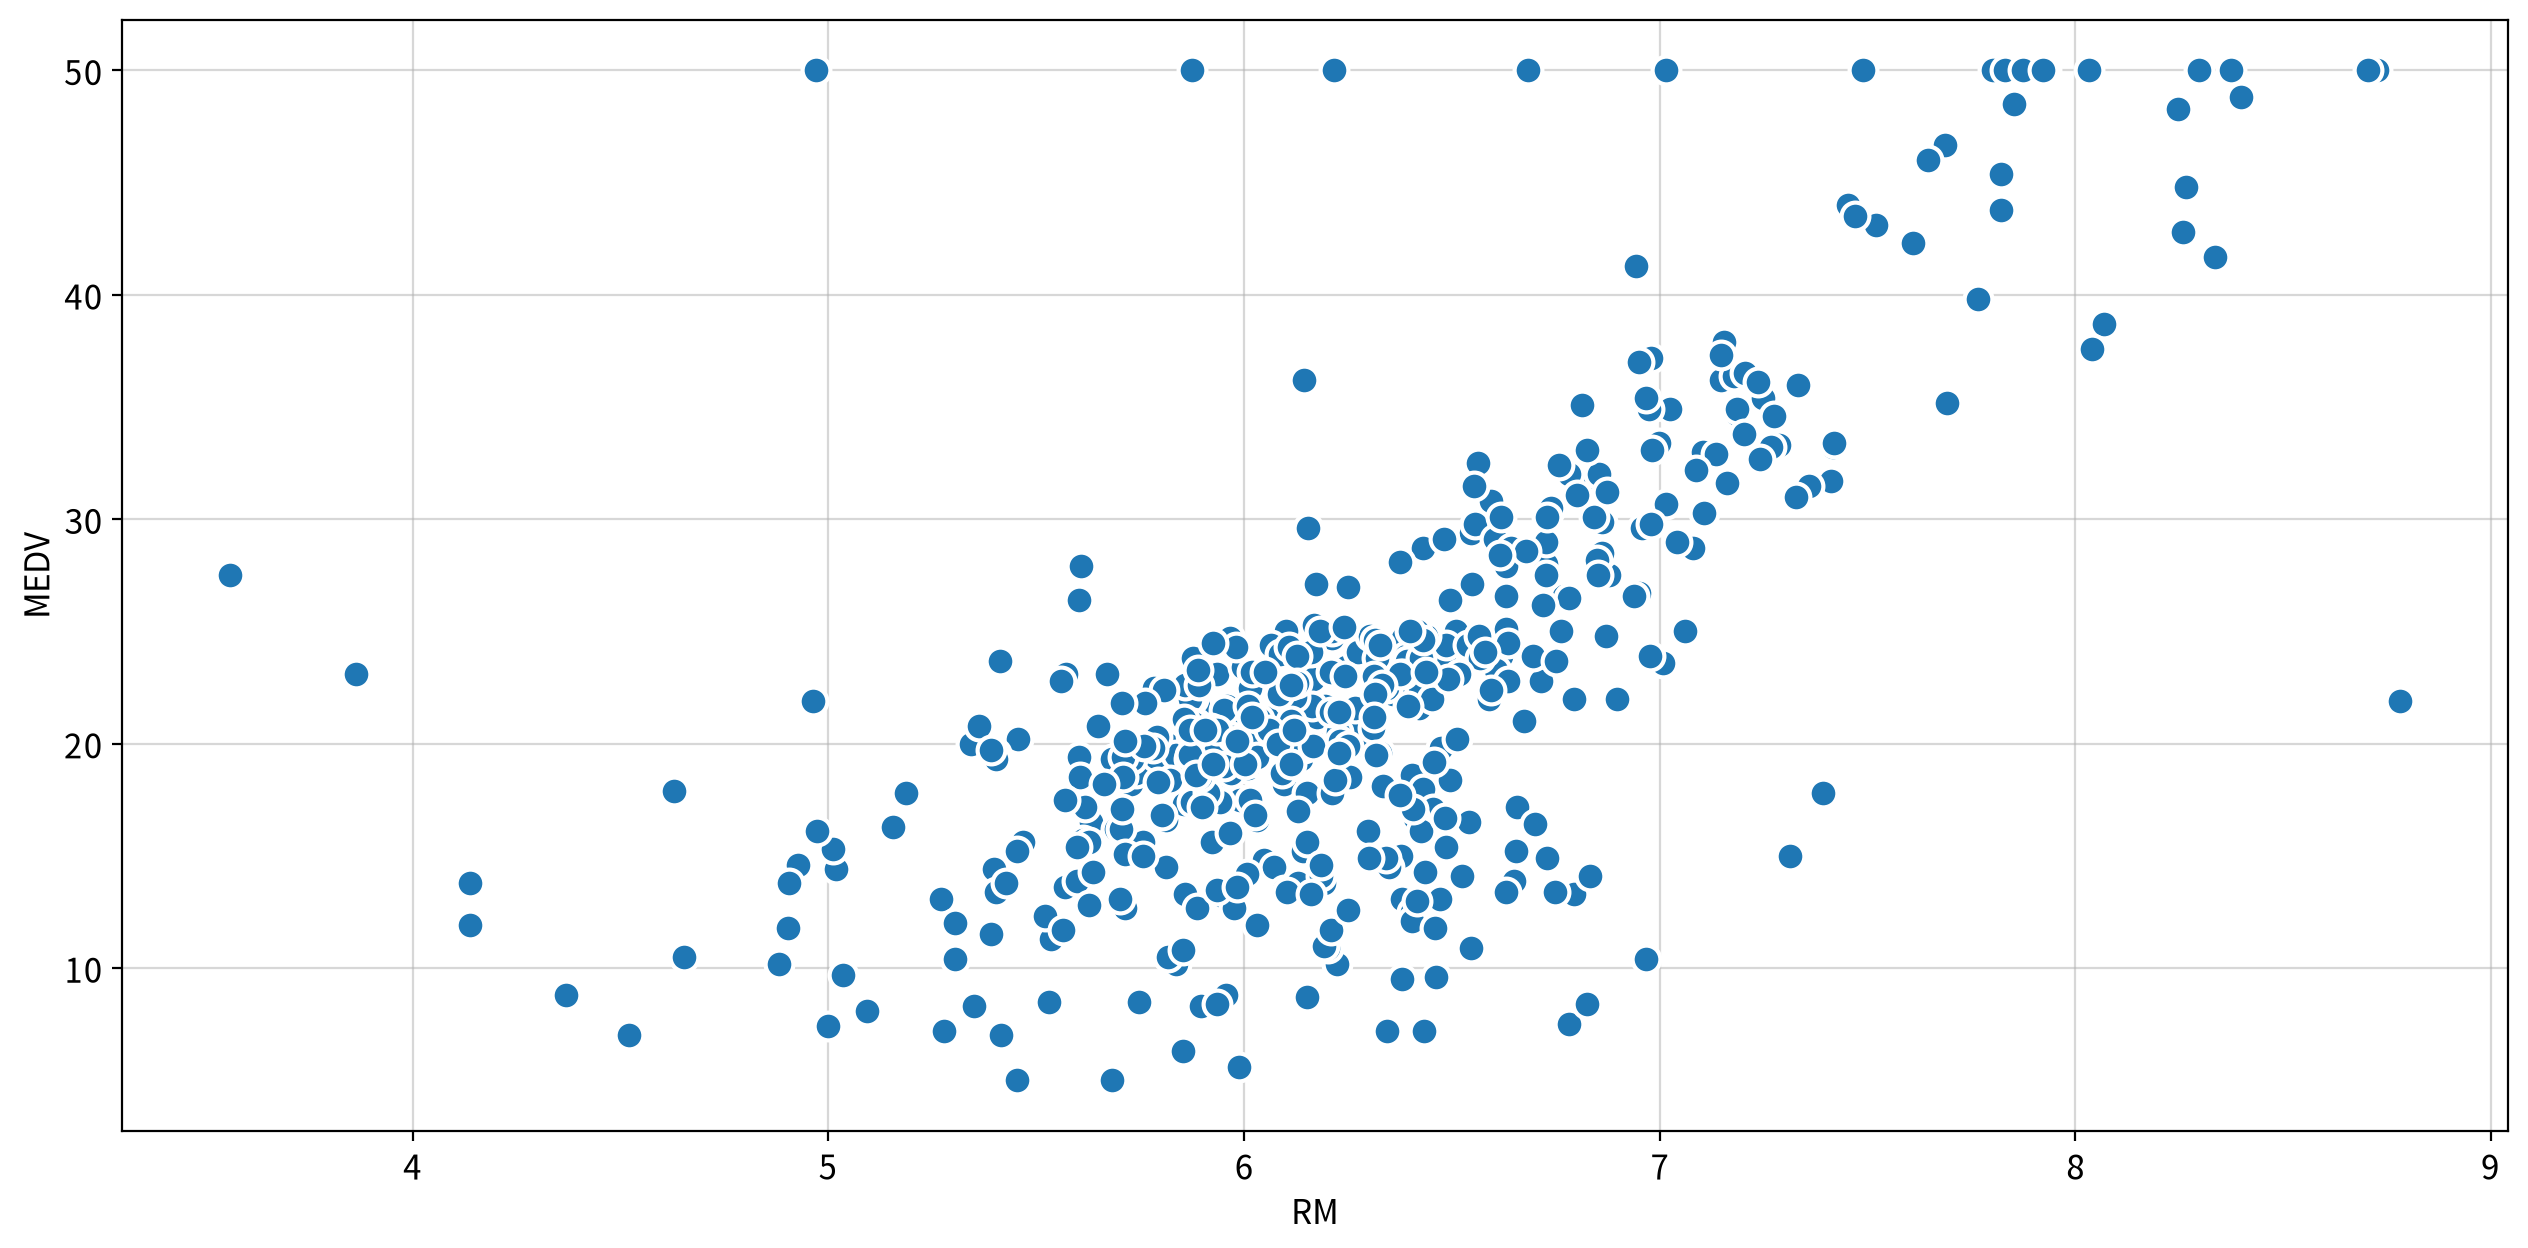

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
RM,MEDV,Spearman,0.634,0.000,Moderate,True,False,False,False,False,True


#### ▶︎ AGE(노후주택비율) → MEDV

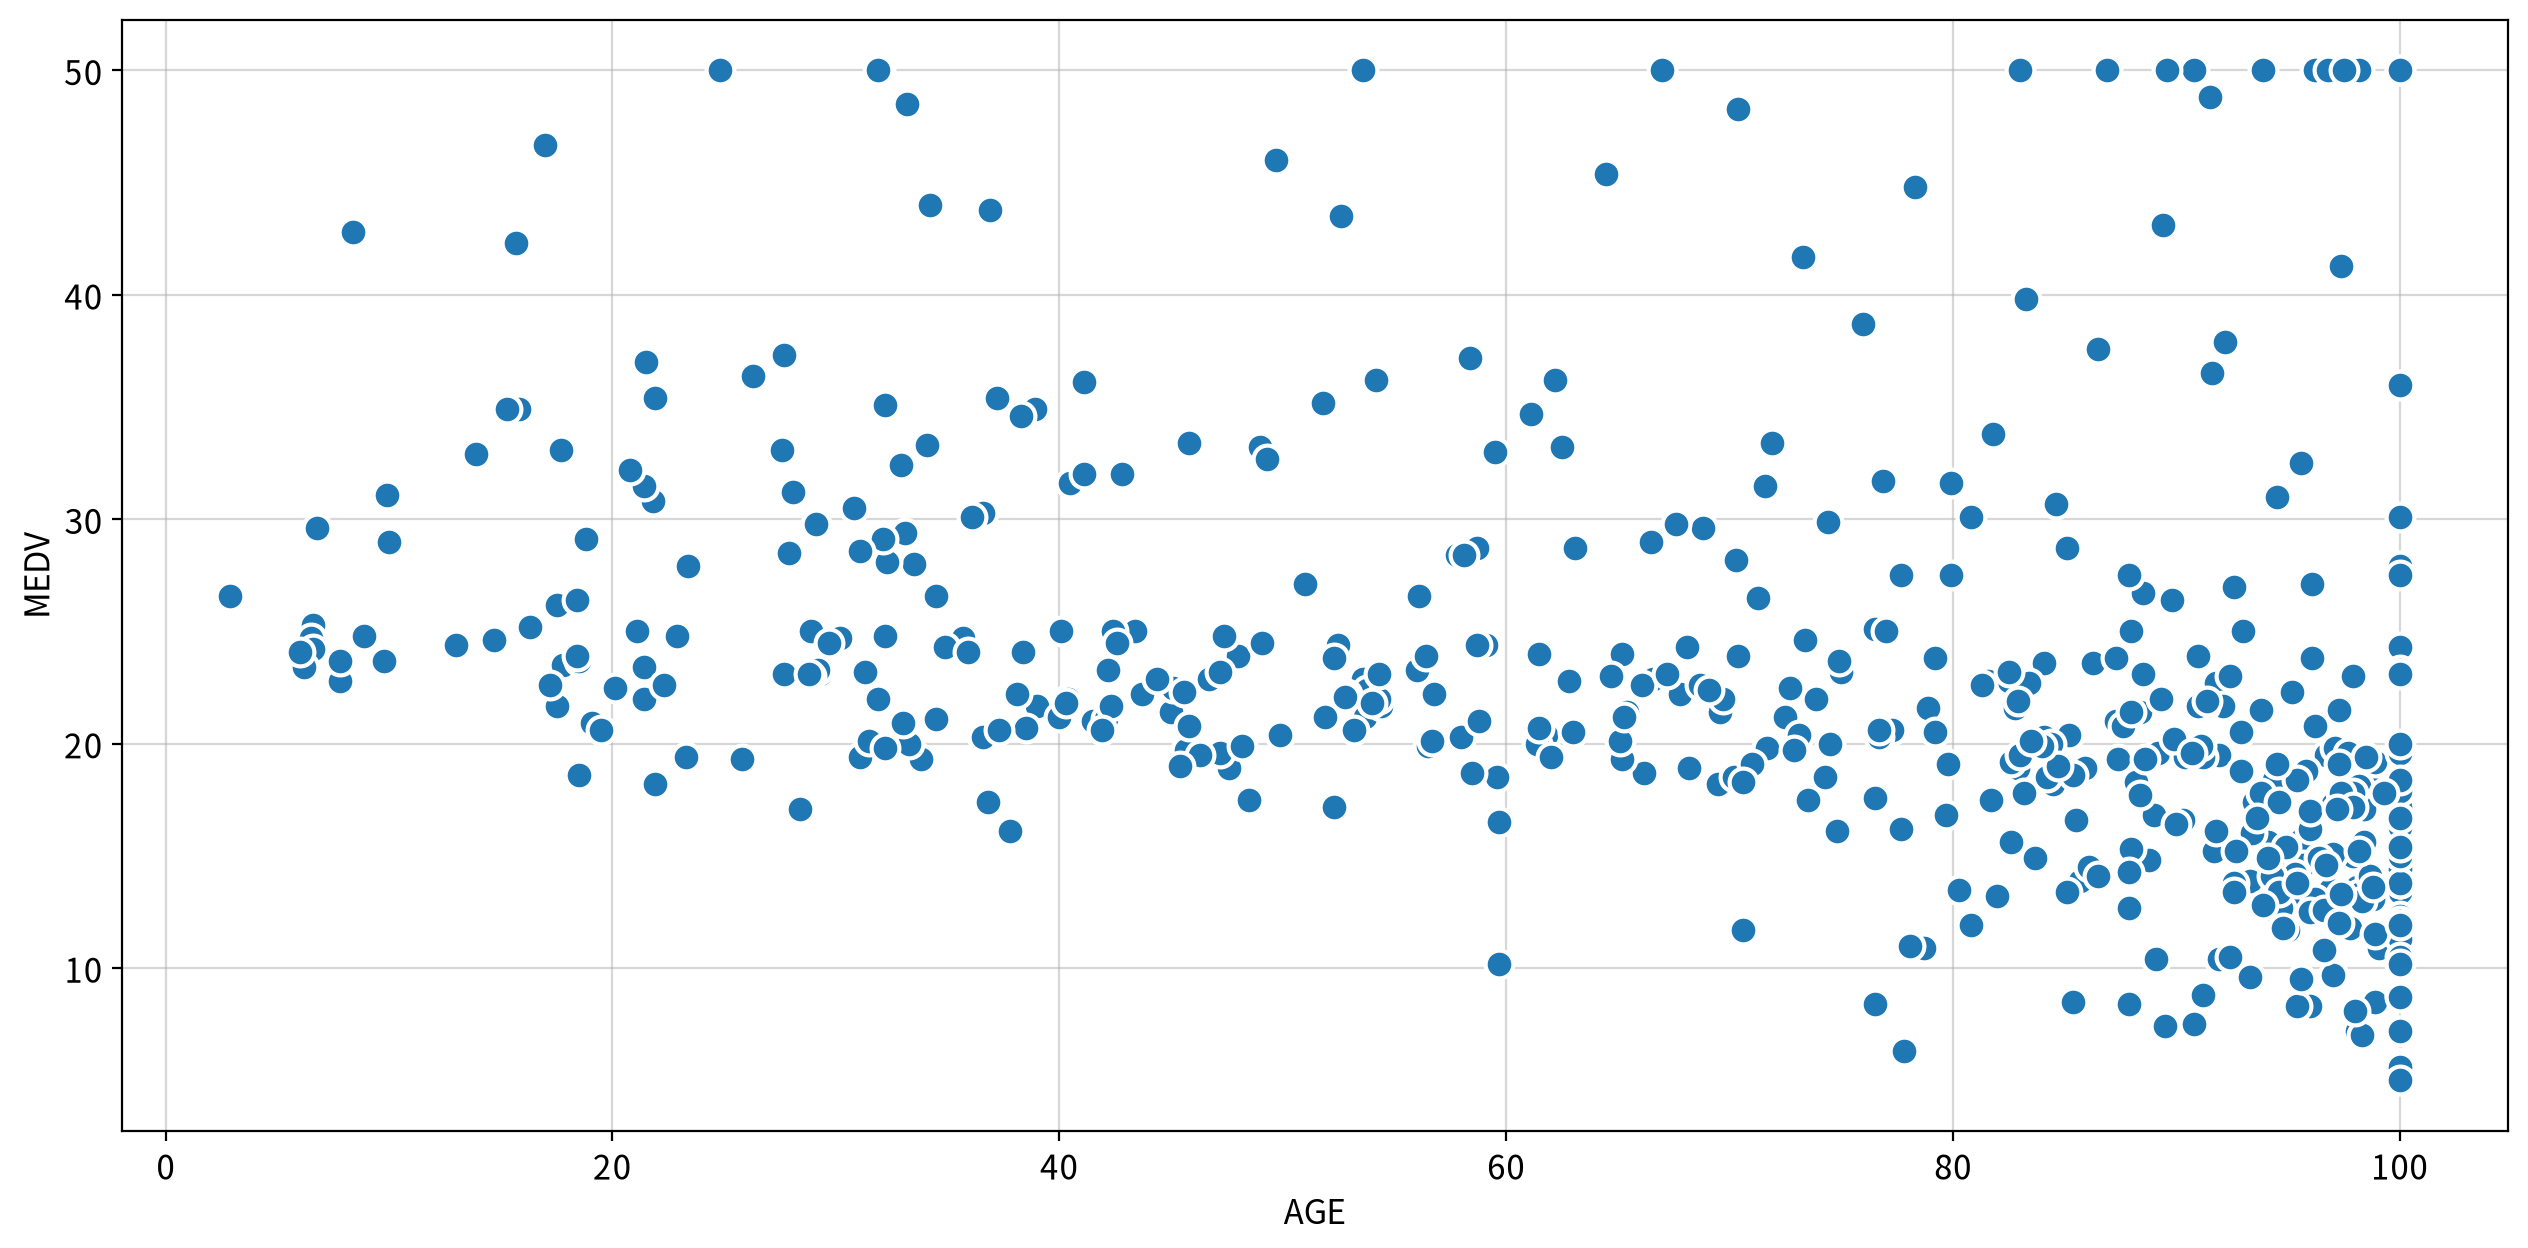

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
AGE,MEDV,Spearman,-0.548,0.000,Moderate,True,False,False,False,True,True


#### ▶︎ DIS(고용센터거리) → MEDV

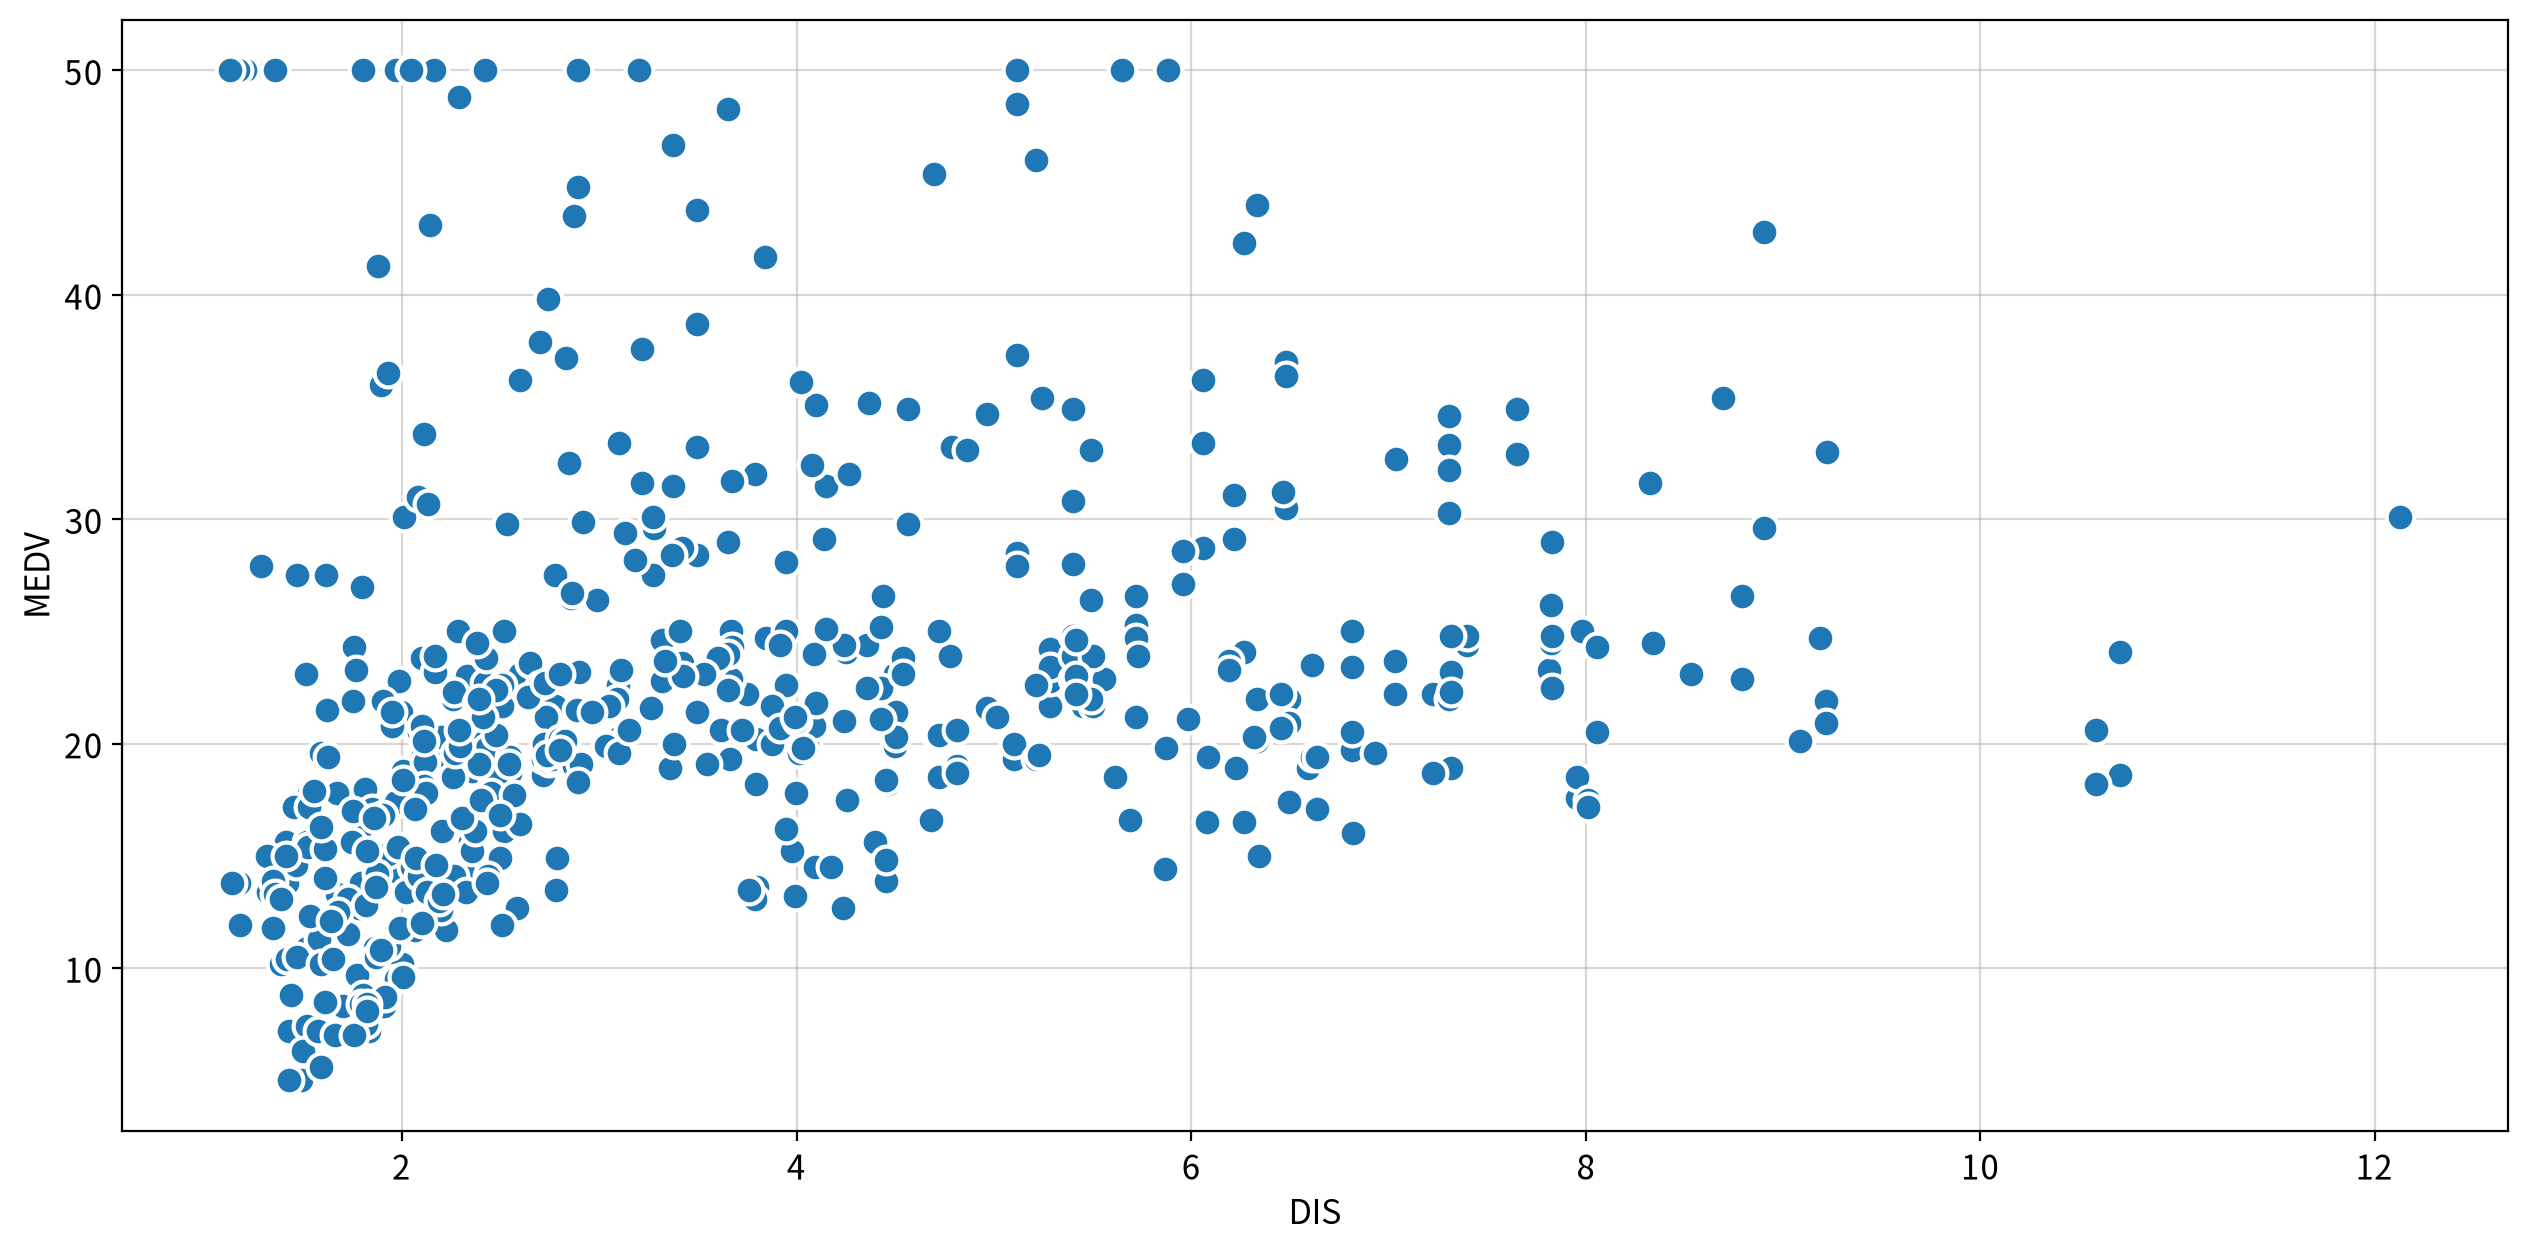

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
DIS,MEDV,Spearman,0.446,0.000,Moderate,True,False,False,False,True,True


#### ▶︎ RAD(고속도로접근성) → MEDV

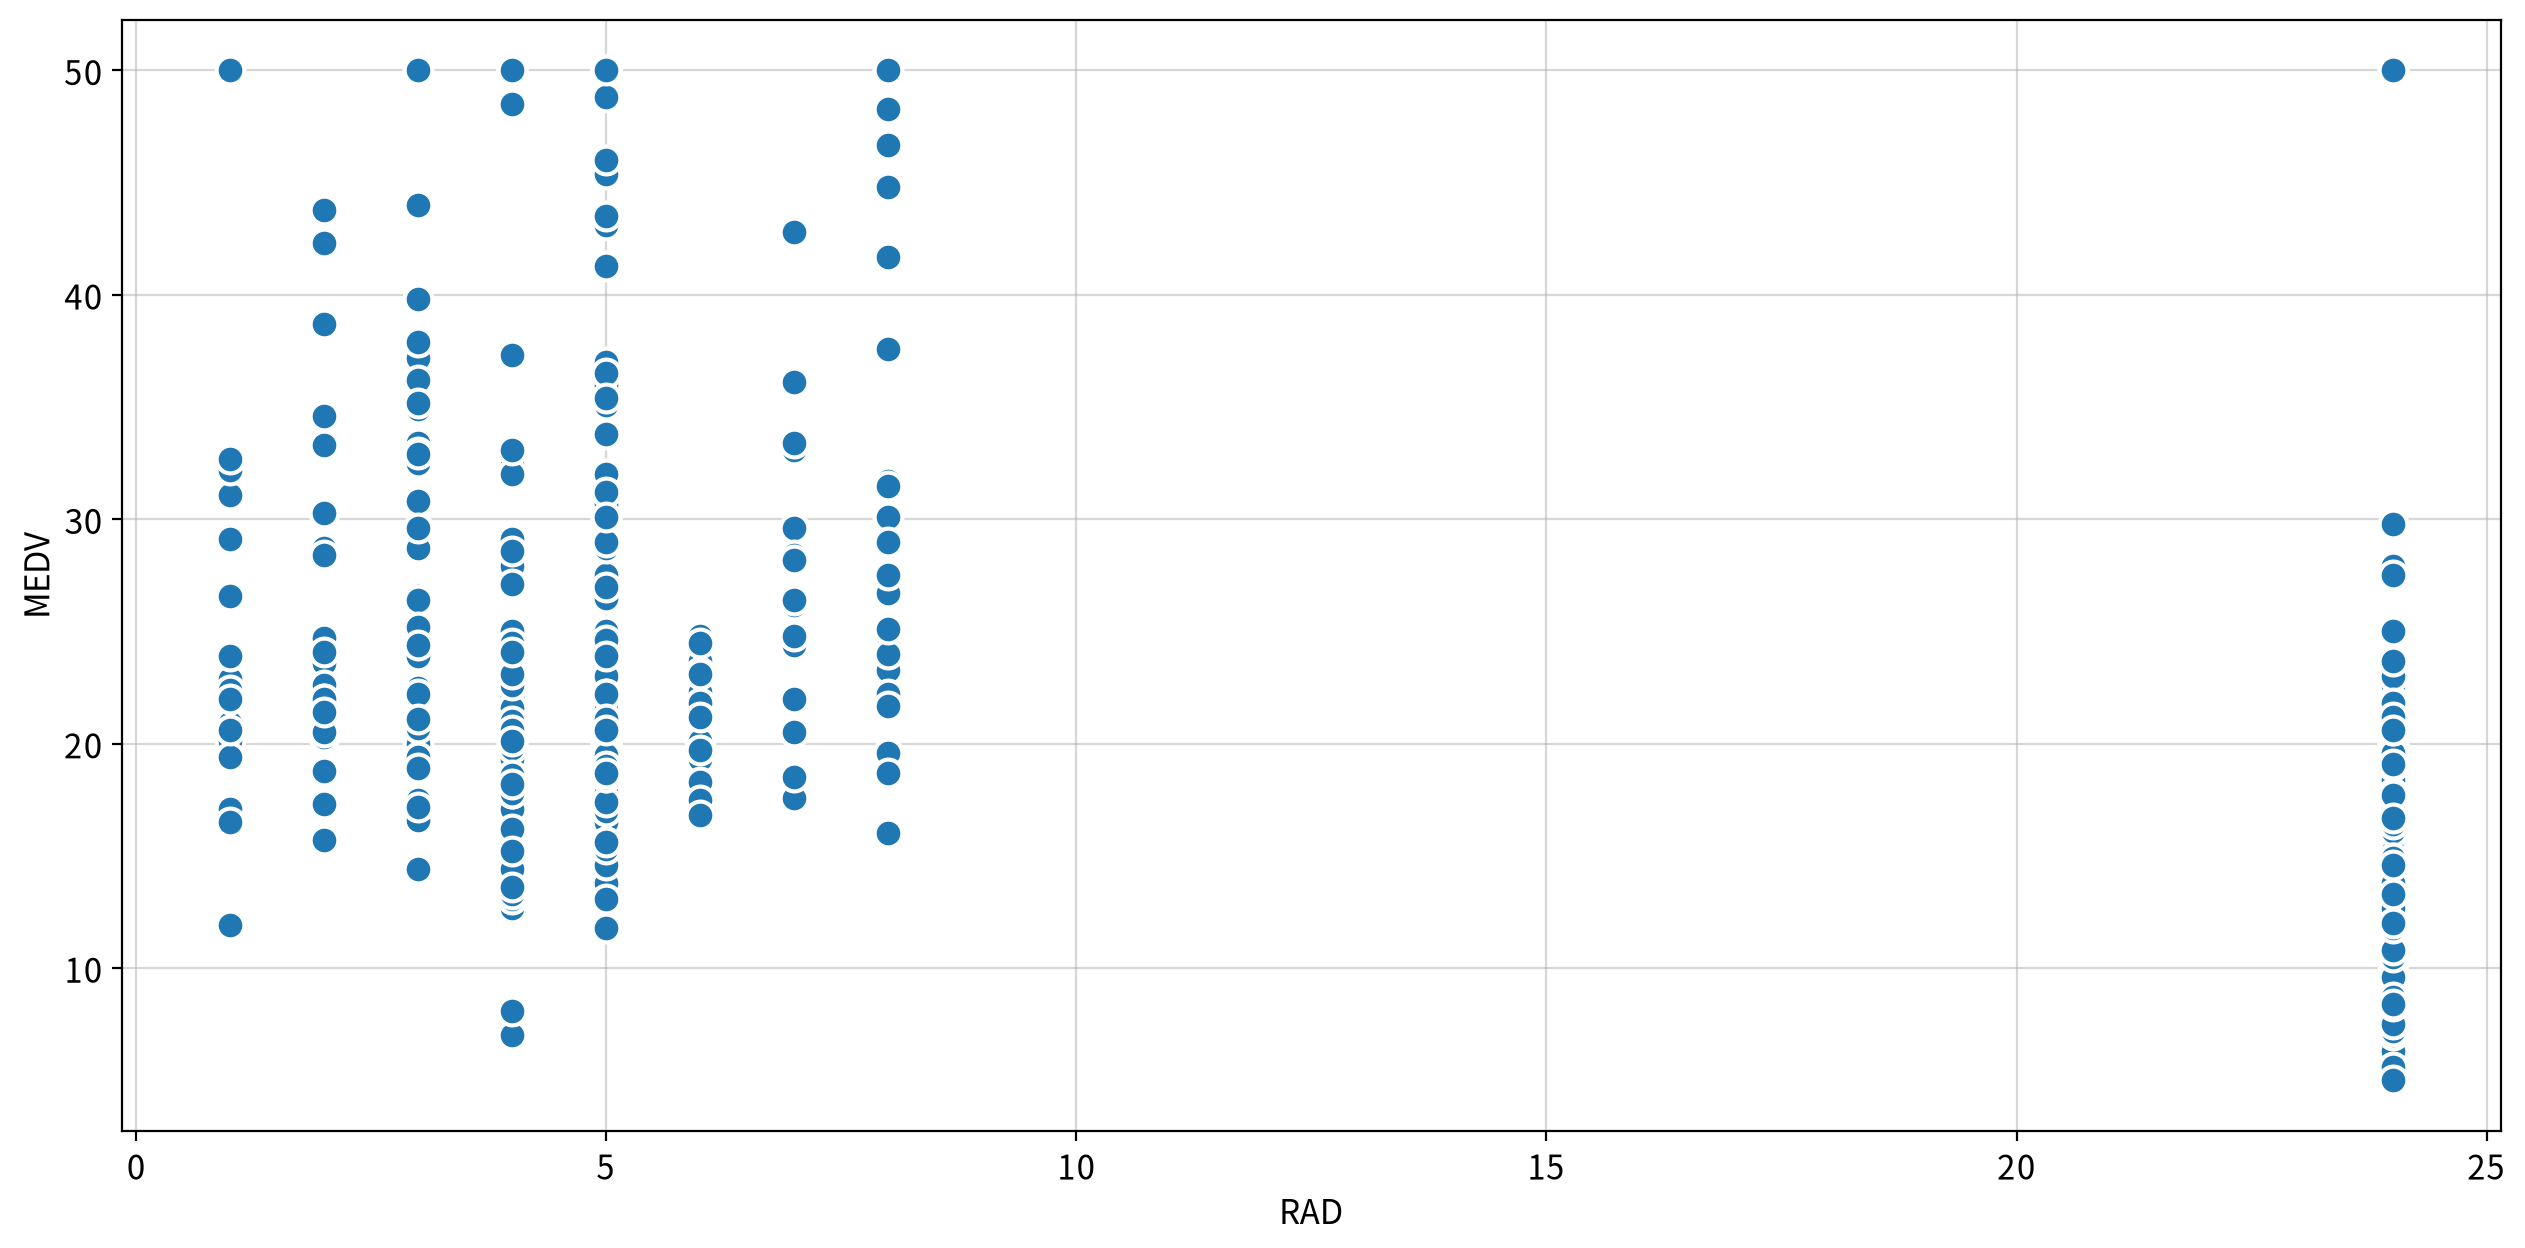

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
RAD,MEDV,Spearman,-0.347,0.000,Moderate,True,False,False,False,True,True


#### ▶︎ TAX(재산세율) → MEDV

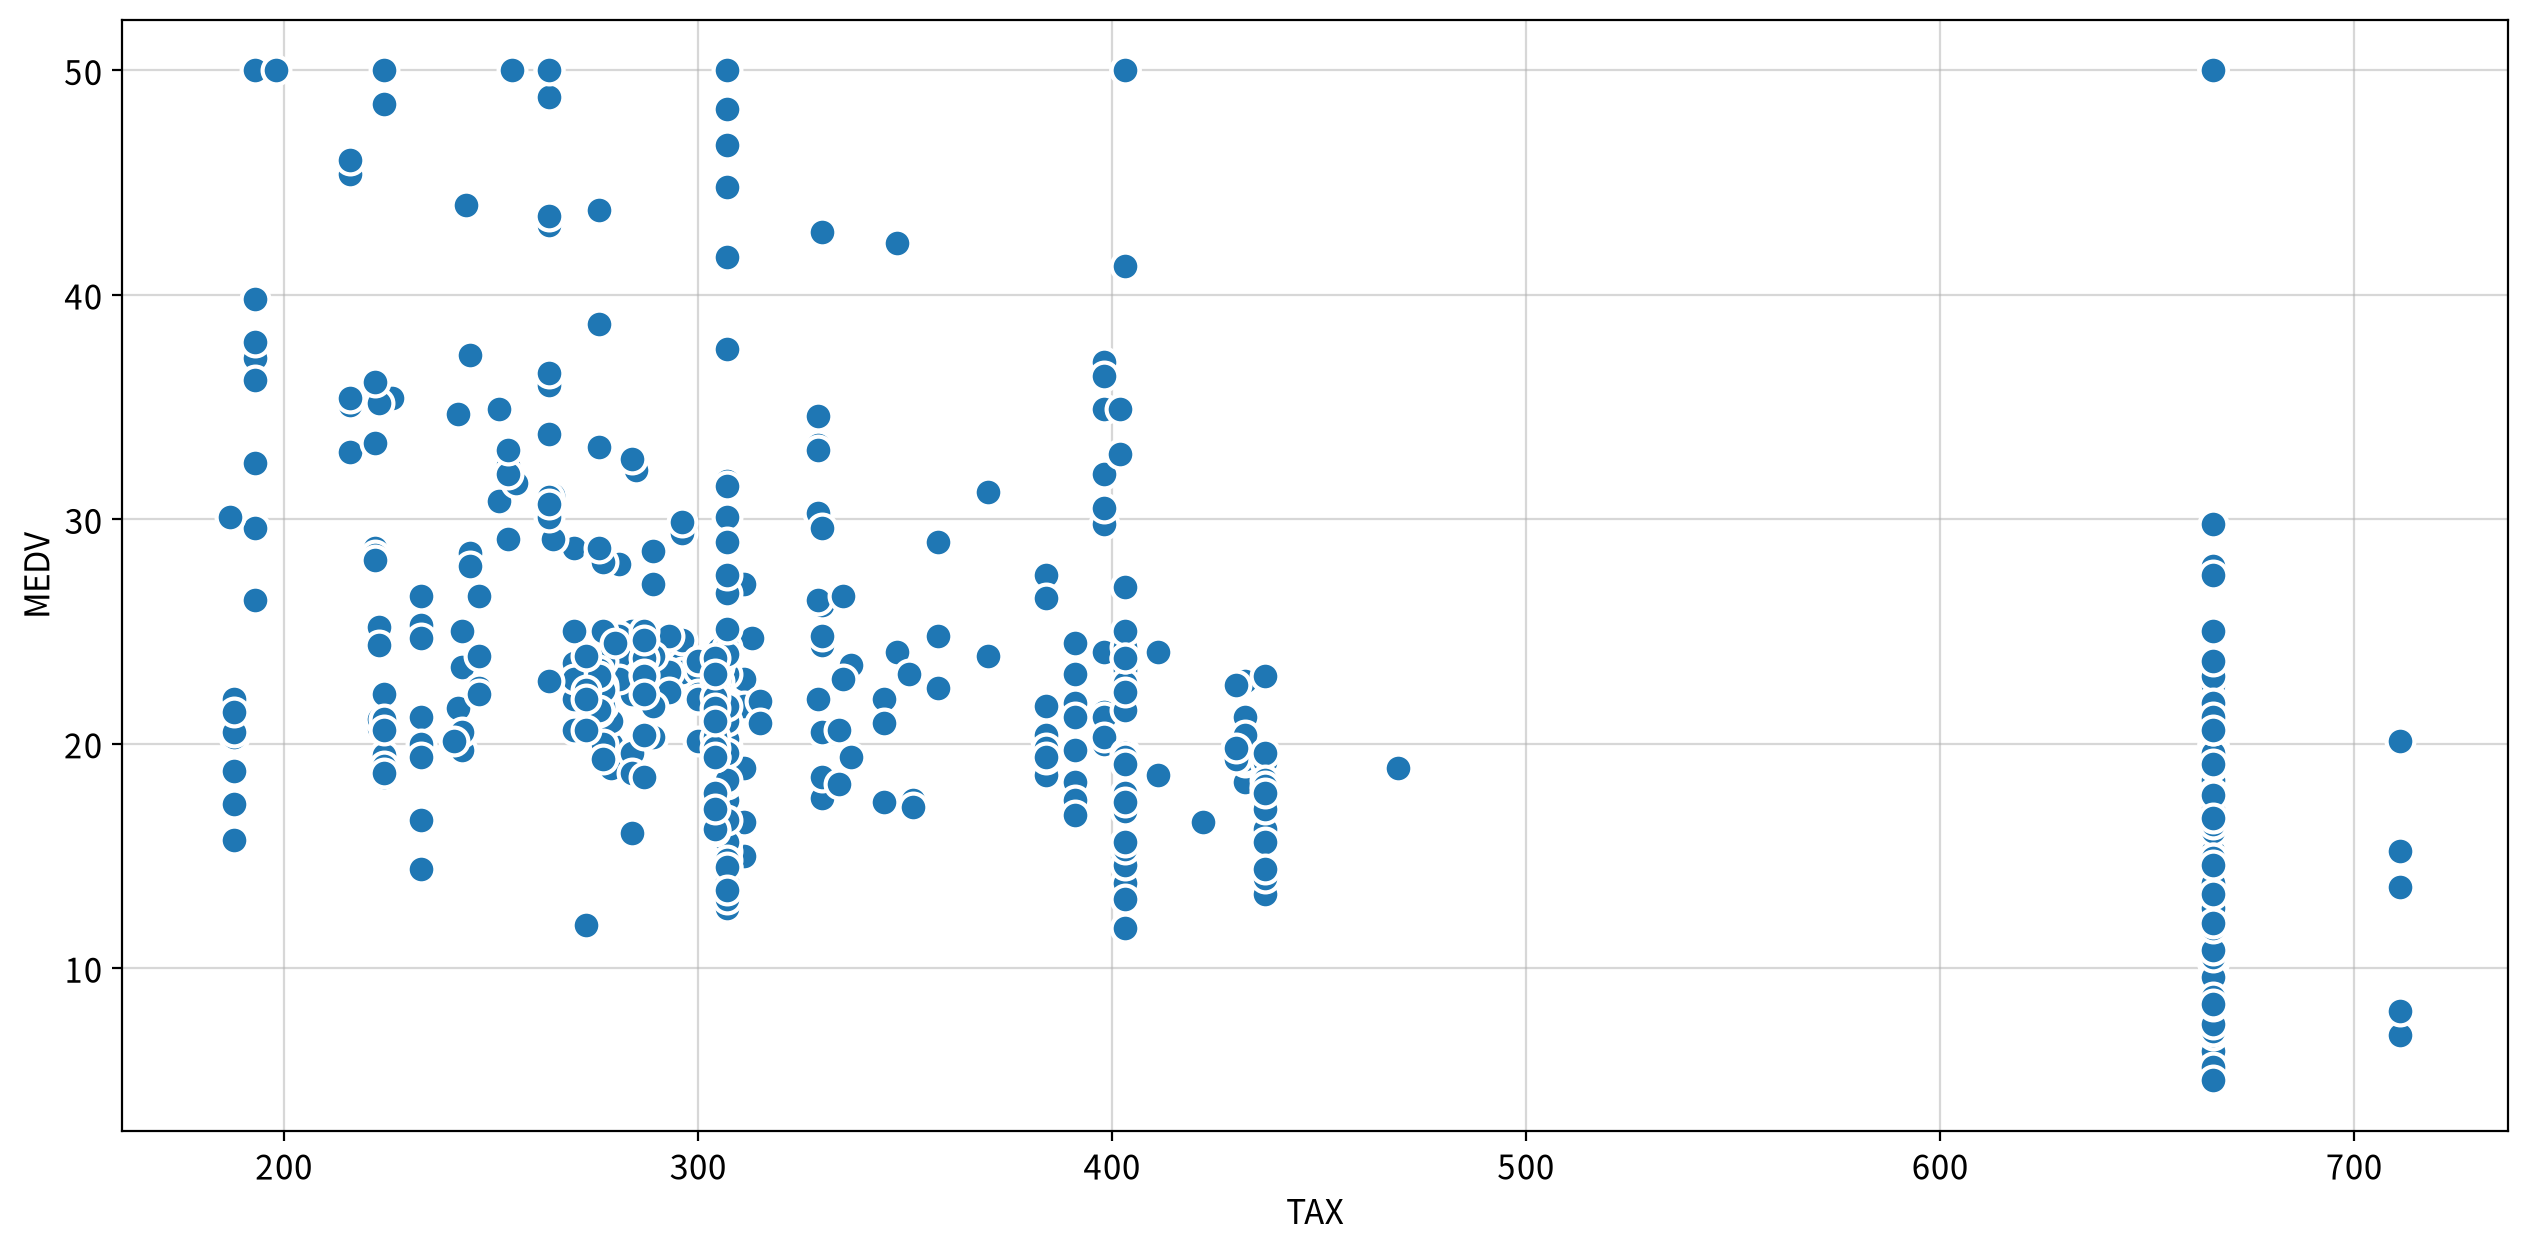

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
TAX,MEDV,Spearman,-0.562,0.000,Moderate,True,False,False,True,True,True


#### ▶︎ PTRATIO(학생교사비율) → MEDV

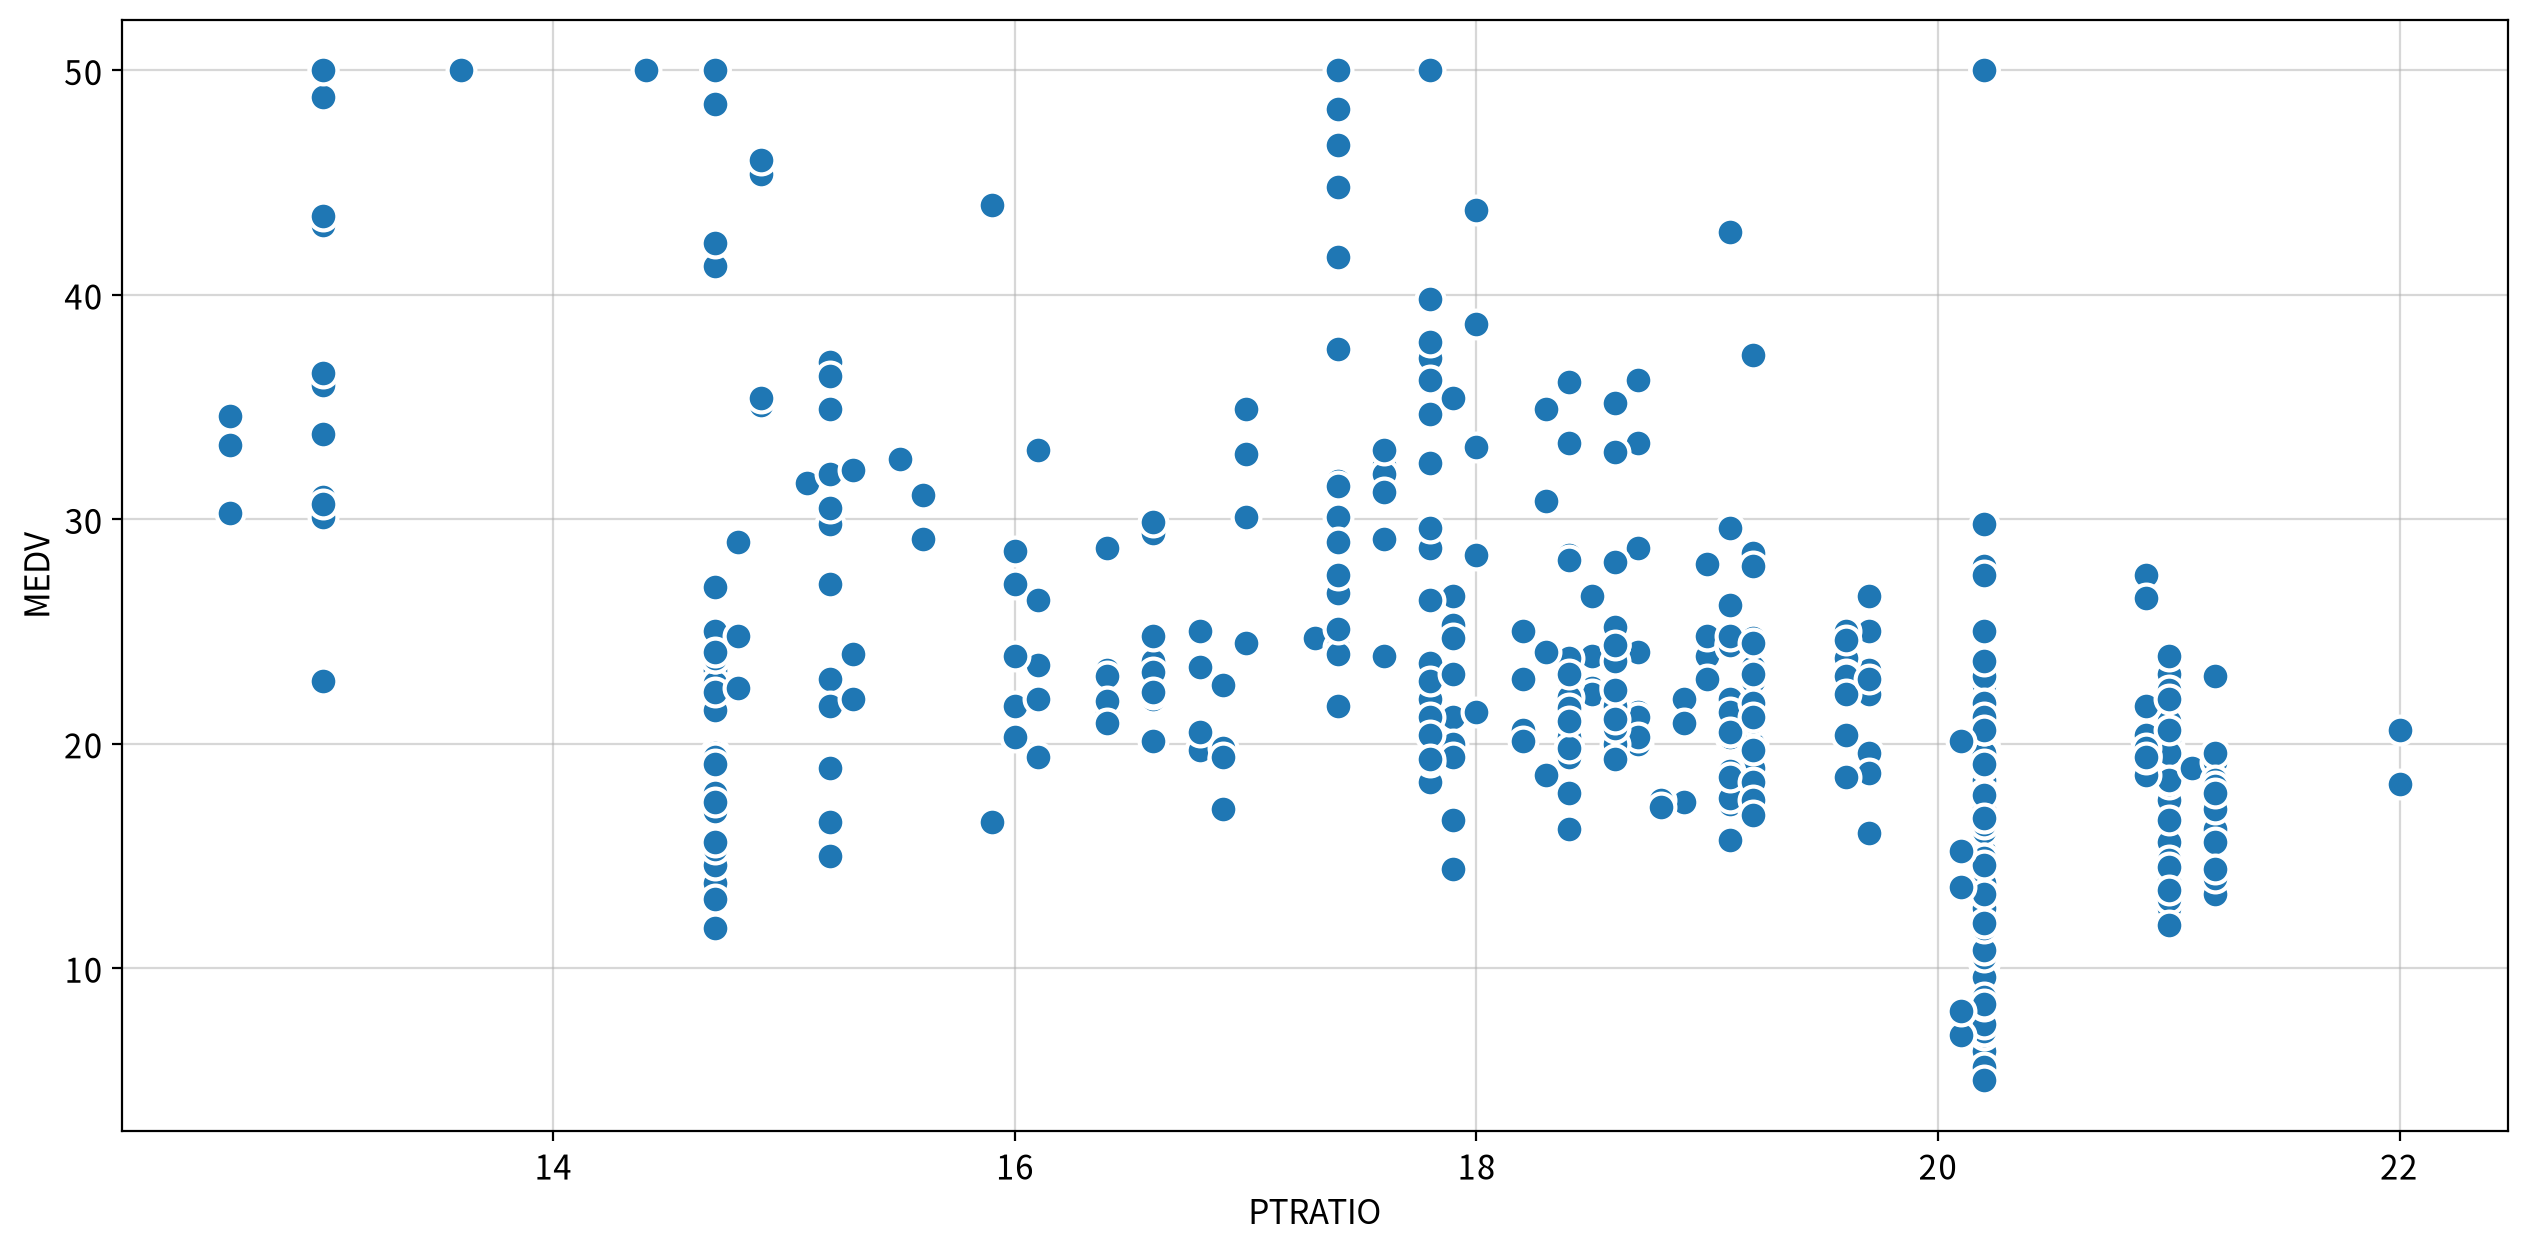

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
PTRATIO,MEDV,Spearman,-0.556,0.000,Moderate,True,False,False,True,False,True


#### ▶︎ B(흑인비율지수) → MEDV

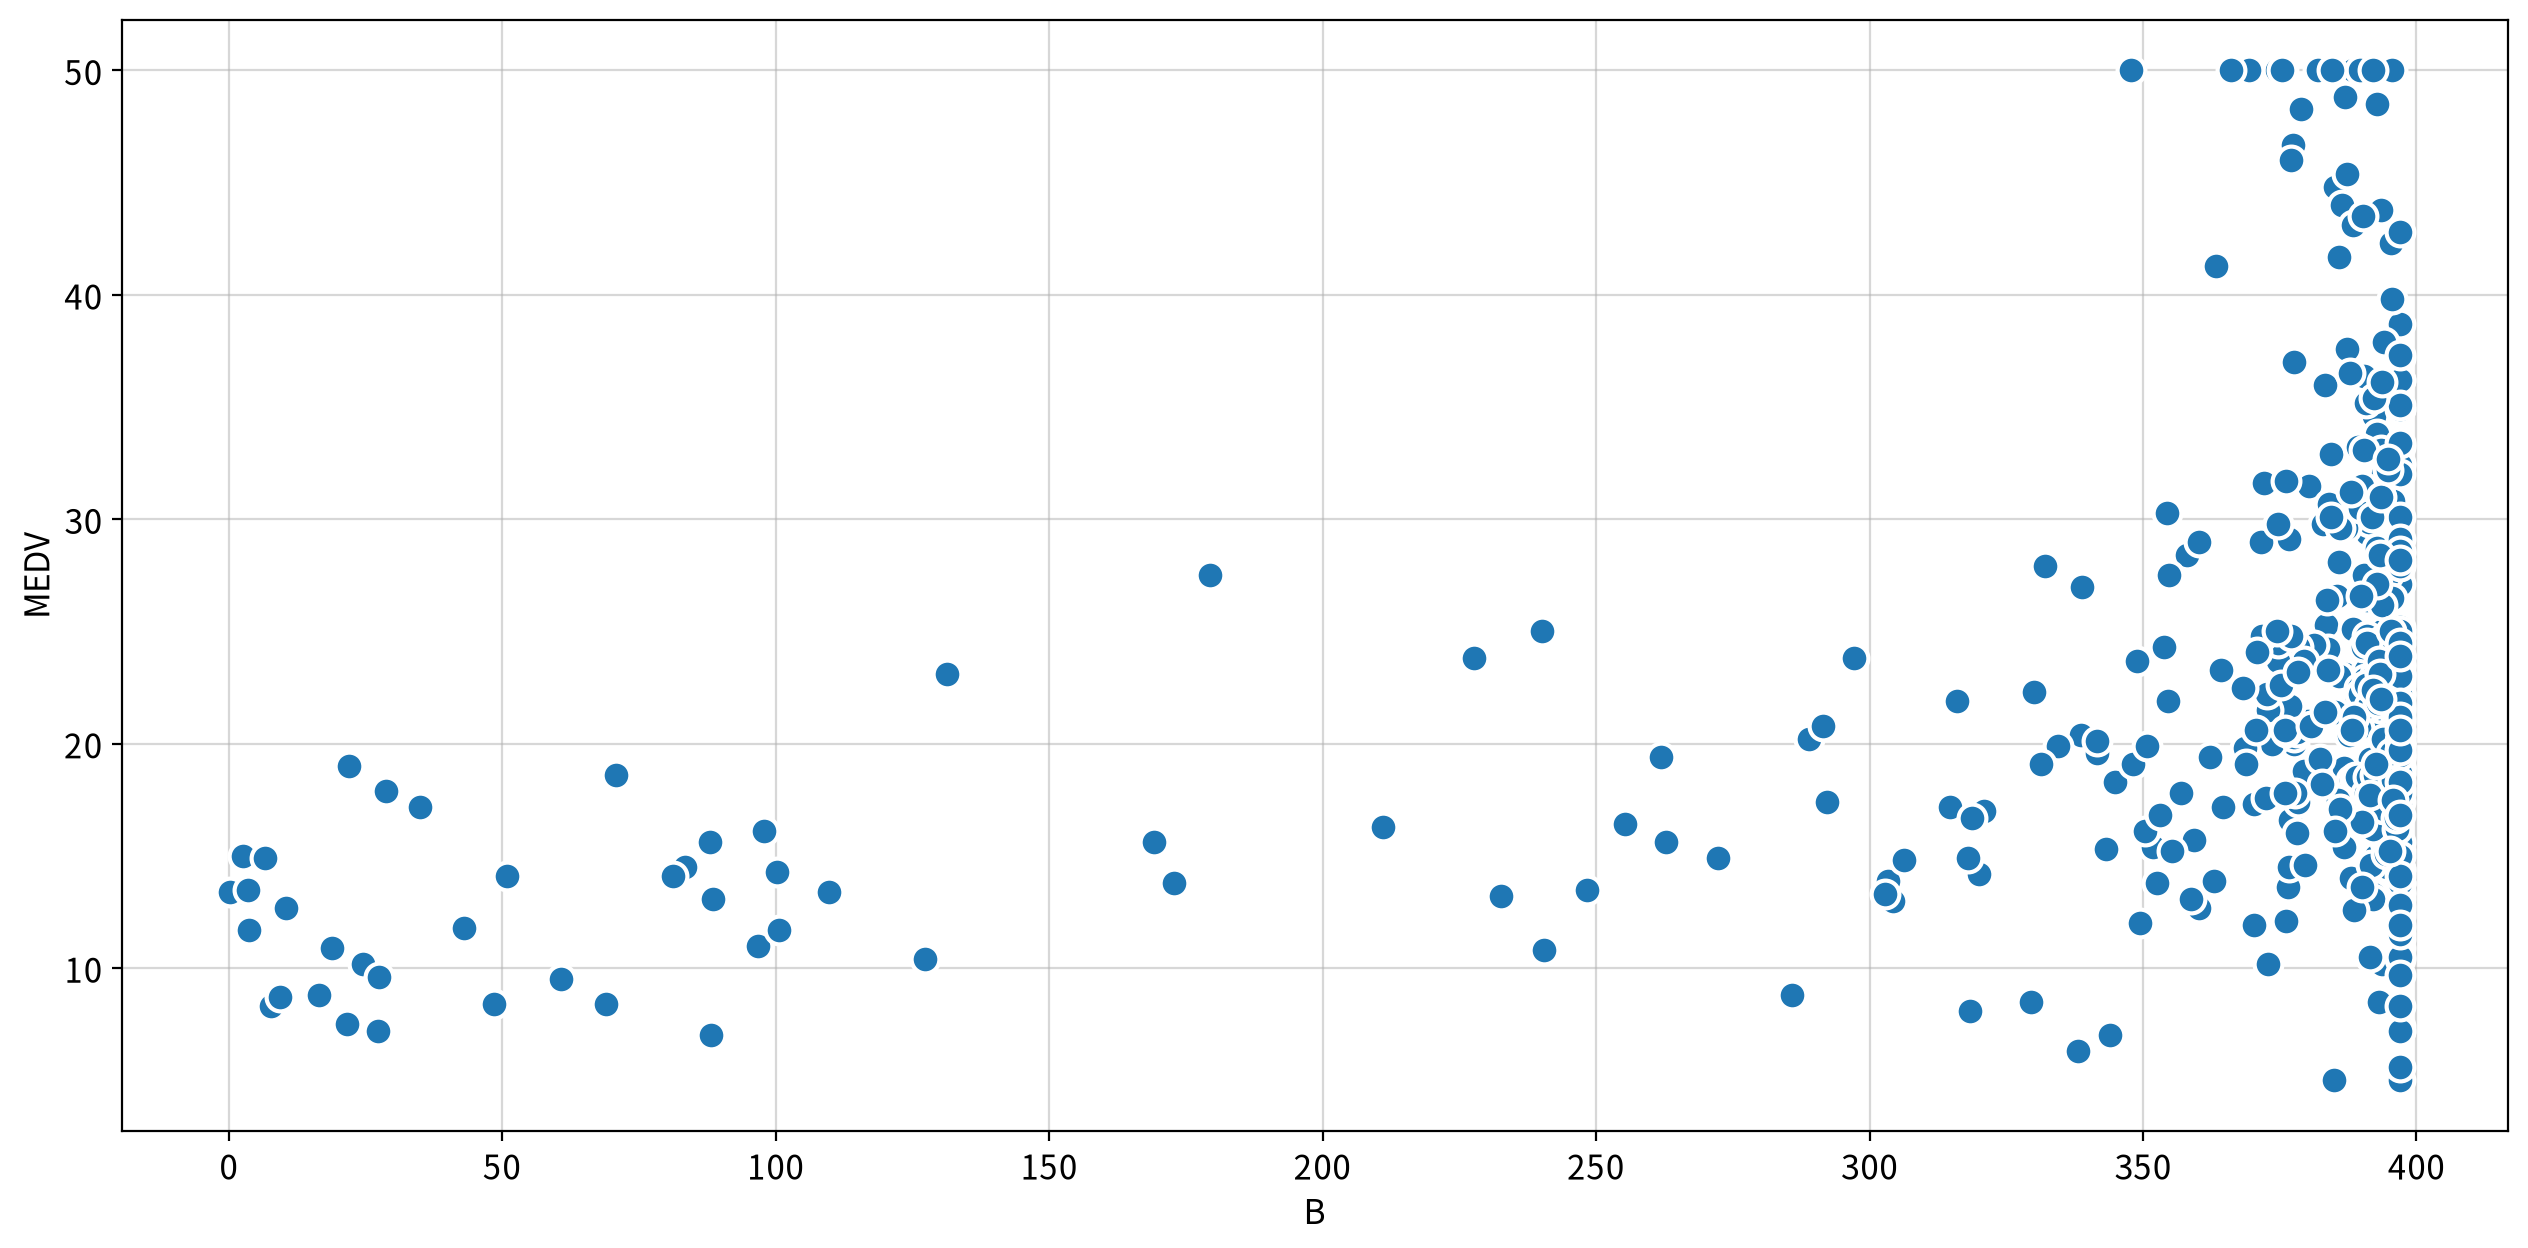

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
B,MEDV,Spearman,0.186,0.000,Weak,True,False,False,True,True,True


#### ▶︎ LSTAT(저소득층비율) → MEDV

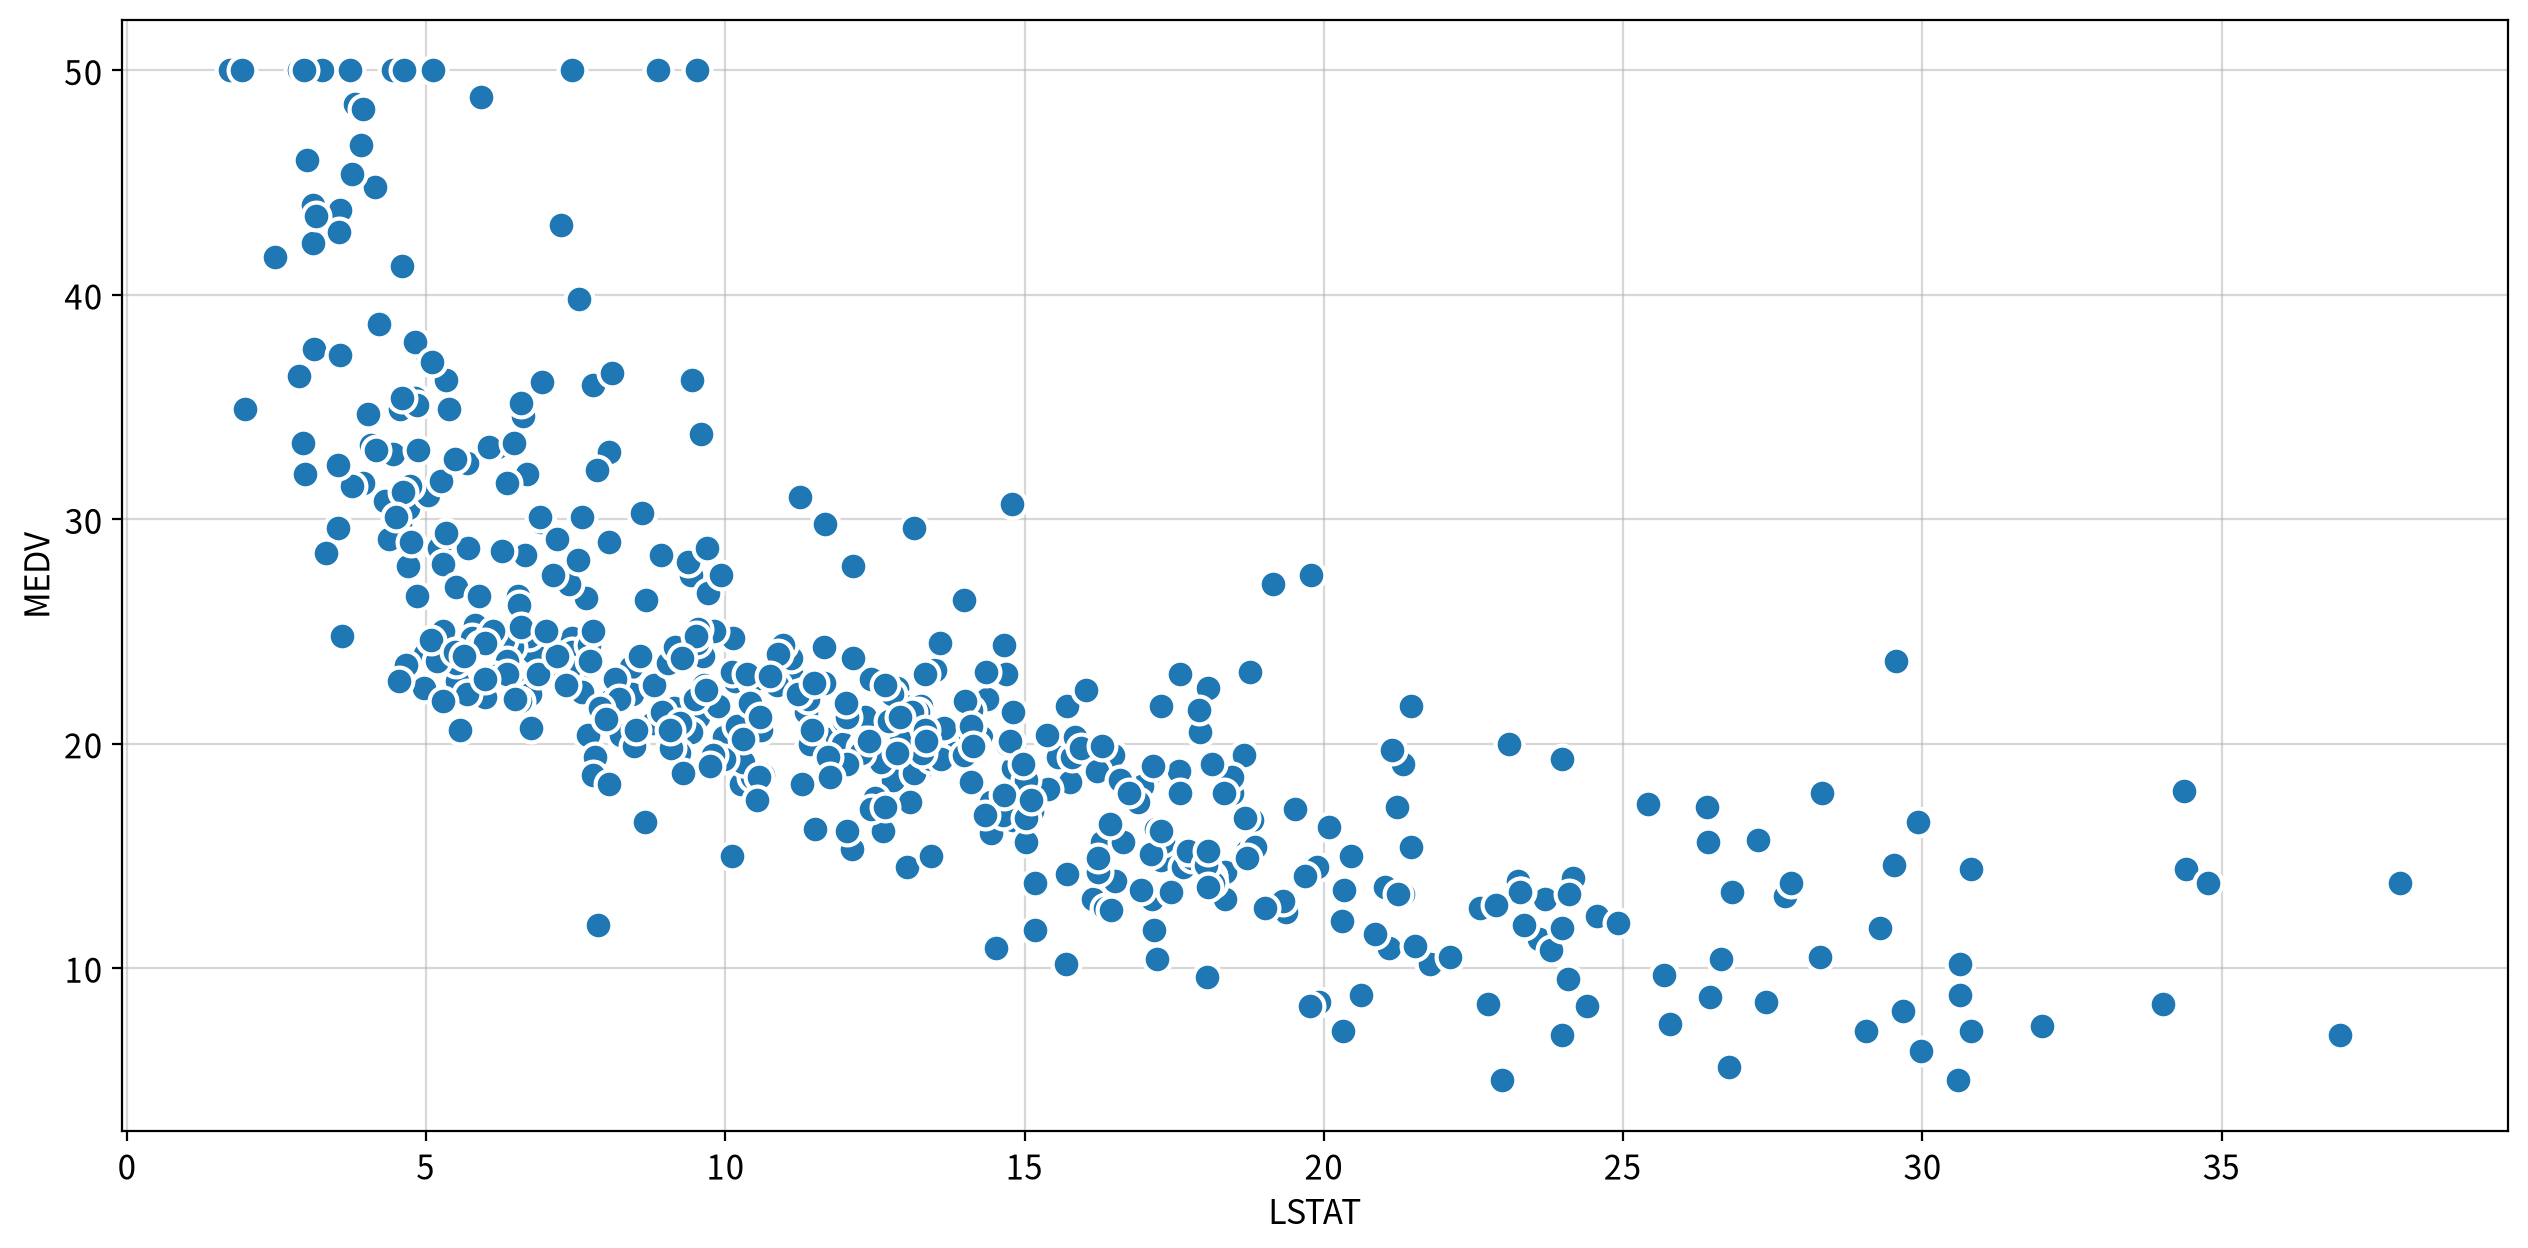

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
LSTAT,MEDV,Spearman,-0.853,0.000,Strong,True,False,False,False,False,True


In [ ]:
for f in continuous_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}")) # h4
    
    # my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(data=df, x=f, y=target))

> 💡 **인사이트 — 이변량 (연속형 × MEDV)**
>
> - ⚠️ 판정은 **"개별 독립변수 ↔ 종속변수(`MEDV`) 단독 관계"만 기준**으로 한다. 변수 간 중복(공선성)은 여기서 고려하지 않으며, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다. 변수별 최종 판정은 아래 (3) 변수 채택 결과 표에 정리했다.
>
> - **12개 중 11개 채택, 1개(`B`) 보류.** 가장 강한 신호는 **`LSTAT`(ρ = −0.853)** 과 **`RM`(ρ = +0.634)** 이다. 집값은 '누가 사는 동네인가'와 '집이 얼마나 큰가'가 두 축이다.
> - 나머지 채택 변수 중 `INDUS` · `NOX` · `TAX` · `CRIM` · `PTRATIO` · `AGE` 6개는 ρ = −0.548 ~ −0.578로 **크기가 거의 같은 음(−)의 관계**다. 모두 '공업 지역 · 도심에 가까운 오래된 동네'라는 비슷한 정보를 담고 있을 가능성이 있다 → 다변량 분석에서 확인한다.
> - **모든 변수에서 Spearman이 선택됐다.** `MEDV`와 독립변수 모두 정규성이 깨져 있어(상한 50, 치우친 분포) 순위 기반 상관이 더 적절하다.
> - **선형성이 확인된 변수는 `NOX` · `TAX` · `PTRATIO` · `B` 4개뿐**이다. 상관 1 · 2위인 `LSTAT` · `RM`도 곡선 관계다.
>   - `LSTAT`은 우편향이라 단변량에서 판정한 **로그변환으로 곡선을 펼 수 있다.**
>   - `RM`은 분포가 대칭이라 로그 대상이 아니다. 곡선이 모델에 남으면 선형성 위배로 드러날 수 있다(→ PART 3 가정 검정에서 확인).
> - `INDUS` · `NOX` · `TAX` · `AGE` · `DIS` · `RAD` · `B` 7개는 **영향점(influential outlier)** 이 감지됐다. 소수의 관측치가 계수를 끌고 갈 수 있다는 신호로, 이상치 처리 효과는 PART 3 `2_이상치대체`에서 검증한다.
> - 보류한 `B`(ρ = +0.186, 약함)는 버리지 않고 모델에 넣어, 회귀계수의 유의성으로 최종 판정한다.

### (2) 명목형(2집단) × 연속형 : 독립표본 검정

- 정규성 · 등분산성 결과에 따라 **t / Welch / Mann-Whitney U**를 자동 선택한다.

#### ▶︎ CHAS(찰스강인접여부) → MEDV

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.582e-03 U_stat=5.606e+03


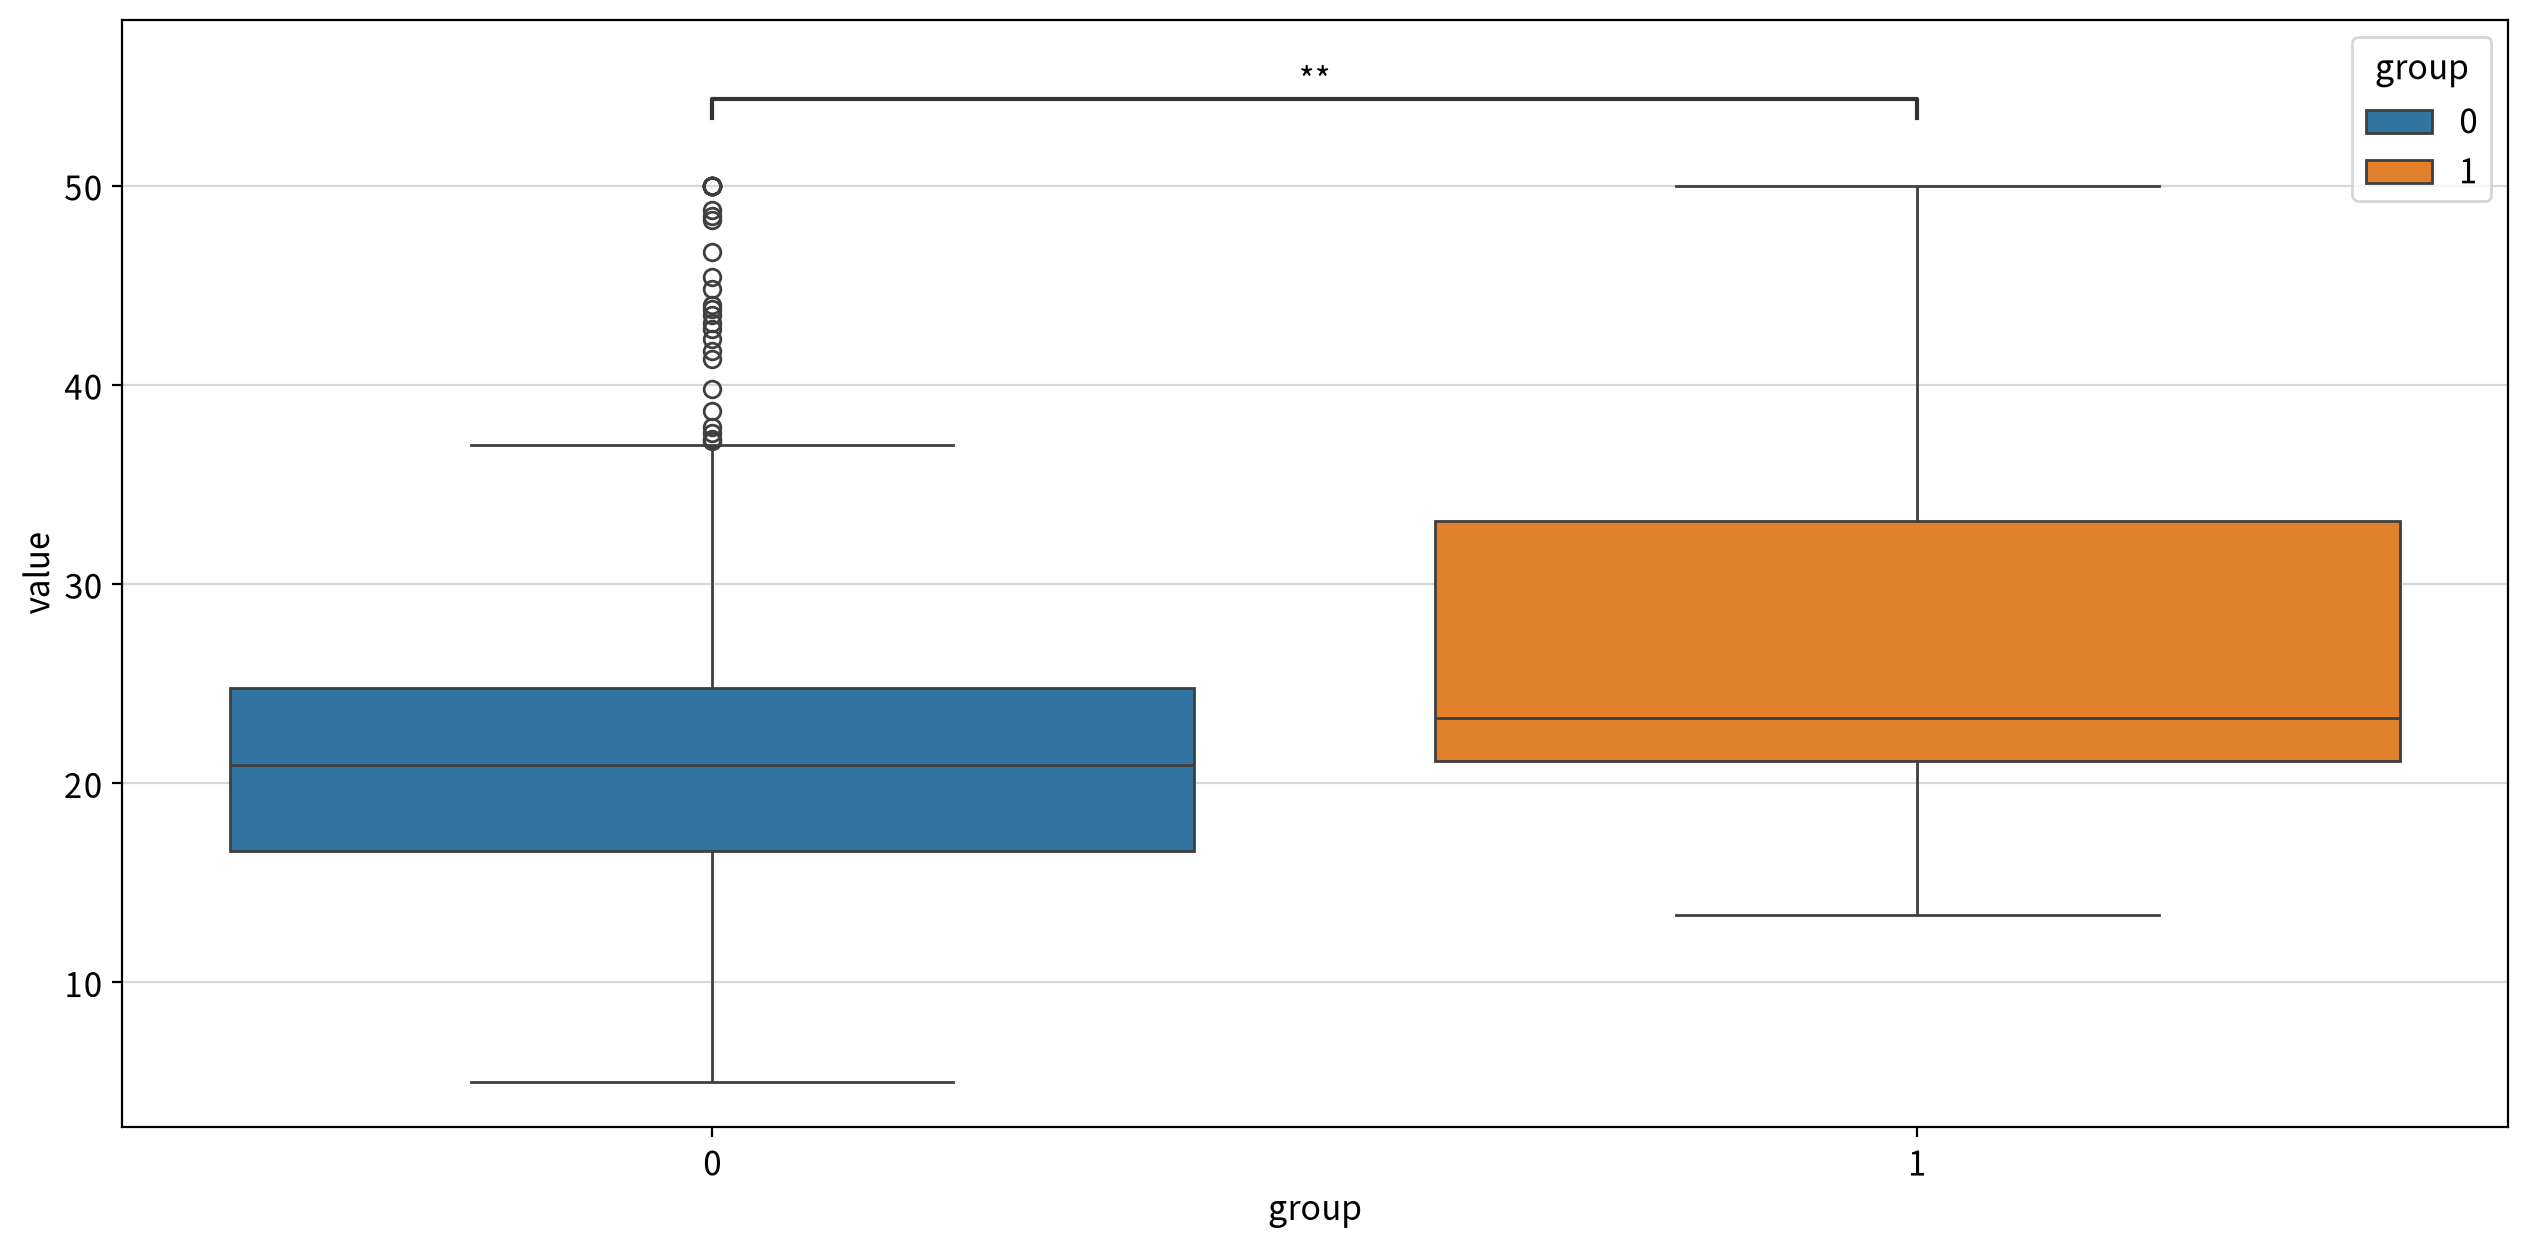

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided    5,605.500    0.002         True  0 ≠ 1
                    less         5,605.500    0.001         True  0 < 1
                    greater      5,605.500    0.999        False  0 ≤ 1

In [50]:
for n in nominal_cols:
    # 빈 줄 출력용
    print()

    # 분석 단위 제목 출력
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
    wide = my_prep.long2wide(df, hue=n, values=target)
    display(my_stats.test_independent(wide, group1=wide.columns[0], group2=wide.columns[1]))

> 💡 **인사이트 — 이변량 (CHAS × MEDV)**
>
> - `CHAS`는 Mann-Whitney U에서 **강변 집단이 유의하게 비쌌다**(양측 p = 0.002, 단측(0 < 1) p = 0.001).

### (3) 변수 채택 결과 표

- **채택 기준은 "각 독립변수 ↔ 종속변수(`MEDV`) 단독 관계"만 사용한다.**
  - 연속형 : 유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)
  - 명목형 : 집단 차이 유의(p < 0.05)
- 공선성(변수 간 중복)은 이 이변량 단계에서는 알 수 없으므로, 다음 다변량 분석과 PART 3의 VIF 단계에서 점검한다.
- 종합 판정 : **채택 12, 보류 1**
  - 보류로 판정된 변수는 일단 모델링에 투입하고, 회귀계수의 유의성으로 최종 채택 여부를 판정한다.

| 채택여부 | 변수 | 검정방법 | 유의수준 (p) | 효과크기 | 가정점검 | 비대칭신호 | 근거 |
|---|---|---|---|---|---|---|---|
| ✅ 채택 | LSTAT | Spearman | $< 0.001$ | ρ=−0.853 (강함) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 없음 | 우편향 / log 필요 | 유의미한 상관 (\|ρ\|≥0.3, 설명력 1위) |
| ✅ 채택 | RM | Spearman | $< 0.001$ | ρ=+0.634 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 없음 | 대칭 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3, 양(+)의 관계 최강) |
| ✅ 채택 | INDUS | Spearman | $< 0.001$ | ρ=−0.578 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 있음 | 대칭 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | NOX | Spearman | $< 0.001$ | ρ=−0.563 (중간) | 정규성 위배 / 선형성 충족 / 이상치 계수왜곡 있음 | 우편향 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | TAX | Spearman | $< 0.001$ | ρ=−0.562 (중간) | 정규성 위배 / 선형성 충족 / 이상치 계수왜곡 있음 | 우편향 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | CRIM | Spearman | $< 0.001$ | ρ=−0.559 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 없음 | 우편향 / log 필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | PTRATIO | Spearman | $< 0.001$ | ρ=−0.556 (중간) | 정규성 위배 / 선형성 충족 / 이상치 계수왜곡 없음 | 좌편향 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | AGE | Spearman | $< 0.001$ | ρ=−0.548 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 있음 | 좌편향 / 불필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | DIS | Spearman | $< 0.001$ | ρ=+0.446 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 있음 | 우편향 / log 필요 | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | ZN | Spearman | $< 0.001$ | ρ=+0.438 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 없음 | 우편향 / log1p 필요 (0 포함) | 유의미한 상관 (\|ρ\|≥0.3) |
| ✅ 채택 | RAD | Spearman | $< 0.001$ | ρ=−0.347 (중간) | 정규성 위배 / 선형성 위배 / 이상치 계수왜곡 있음 | 우편향 / log 필요 | 유의미한 상관 (\|ρ\|≥0.3, 기준에 가장 근접) |
| ✅ 채택 | CHAS | Mann-Whitney U | $0.002$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 집단 차이 유의 (강변(1) 집단이 더 비쌈, 단측(0 < 1) p = 0.001) |
| 🟡 보류 | B | Spearman | $< 0.001$ | ρ=+0.186 (약함) | 정규성 위배 / 선형성 충족 / 이상치 계수왜곡 있음 | 좌편향 / reverse_log1p 필요 | 유의하나 관계 약함 (\|ρ\|<0.3) → **모델링 투입 후 계수 유의성으로 최종 판정** |

## 2-3. 다변량 분석 — 독립변수끼리 같은 정보를 담고 있는가?

- `correlation_summary`는 |ρ| ≥ 0.7 인 **강한 상관 쌍**을 변수별로 묶어 보여 준다.

In [51]:
corr_x = my_stats.multi_correlation(data=df, columns=continuous_cols)
my_stats.correlation_summary(corr_x)

,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
CRIM,1.000,-0.572,0.736,0.822,-0.309,0.704,-0.745,0.728,0.729,0.465,-0.361,0.635
ZN,-0.572,1.000,-0.643,-0.635,0.361,-0.544,0.615,-0.279,-0.371,-0.449,0.163,-0.490
INDUS,0.736,-0.643,1.000,0.791,-0.415,0.679,-0.757,0.456,0.664,0.434,-0.286,0.639
NOX,0.822,-0.635,0.791,1.000,-0.310,0.795,-0.880,0.586,0.649,0.391,-0.297,0.637
RM,-0.309,0.361,-0.415,-0.310,1.000,-0.278,0.263,-0.107,-0.272,-0.313,0.054,-0.641
AGE,0.704,-0.544,0.679,0.795,-0.278,1.000,-0.802,0.418,0.526,0.355,-0.228,0.657
DIS,-0.745,0.615,-0.757,-0.880,0.263,-0.802,1.000,-0.496,-0.574,-0.322,0.250,-0.564
RAD,0.728,-0.279,0.456,0.586,-0.107,0.418,-0.496,1.000,0.705,0.318,-0.282,0.394
TAX,0.729,-0.371,0.664,0.649,-0.272,0.526,-0.574,0.705,1.000,0.453,-0.330,0.534
PTRATIO,0.465,-0.449,0.434,0.391,-0.313,0.355,-0.322,0.318,0.453,1.000,-0.072,0.467


,max-y,max-coef,count,columns
x,,,,
CRIM,NOX,0.822,6,"NOX, DIS, INDUS, TAX, RAD, AGE"
DIS,NOX,-0.880,4,"NOX, AGE, INDUS, CRIM"
NOX,DIS,-0.880,4,"DIS, CRIM, AGE, INDUS"
AGE,DIS,-0.802,3,"DIS, NOX, CRIM"
INDUS,NOX,0.791,3,"NOX, DIS, CRIM"
TAX,CRIM,0.729,2,"CRIM, RAD"
RAD,CRIM,0.728,2,"CRIM, TAX"
LSTAT,AGE,0.657,0,-
ZN,INDUS,-0.643,0,-


> 💡 **인사이트 — 다변량**
>
> - **`CRIM` · `NOX` · `DIS` · `INDUS` · `AGE` · `TAX` · `RAD`가 하나의 덩어리**로 얽혀 있다(|ρ| ≥ 0.7). 모두 '공업 지역·도심에 가까운 오래된 동네'라는 같은 정보를 다른 각도에서 재고 있다.
> - 가장 강한 쌍은 `NOX` ↔ `DIS`(ρ = −0.880)로, **고용센터에서 멀수록 공기가 깨끗하다**는 도시 구조 그대로다.
> - 다만 이 단계에서 변수를 실제로 제거하지는 않는다. 실제 VIF가 문제 수준인지는 PART 3의 `vif=True` 체크포인트에서 확인한다.

## 2-4. 최종 변수 선택

- **EDA 판정 기준**
  - 이변량 : 유의(p < 0.05) + |ρ| ≥ 0.3 → ✅ 채택, 유의하지만 |ρ| < 0.3 → 🟡 보류
  - 다변량 : |ρ| ≥ 0.7로 얽힌 덩어리에서는 종속변수와의 |ρ|가 가장 큰 변수를 대표로 남기고, 나머지는 🔶 후보로 둔다
  - 덩어리 안에서 서로 강하게 얽히지 않은 `INDUS`(도심축)와 `TAX`(세율축)를 대표로 정했다 (`INDUS` ↔ `TAX` |ρ| < 0.7)

| EDA 판정 | 변수 | 검정방법 | 유의수준 | 효과크기 | 가정점검 | 비대칭신호 | 중복 (\|ρ\| ≥ 0.7) | EDA 근거 |
|---|---|---|---|---|---|---|---|---|
| ✅ 채택 | LSTAT | Spearman | $< 0.001$ | ρ=−0.853 (강함) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | 없음 | 단독 설명력 1위 |
| ✅ 채택 | RM | Spearman | $< 0.001$ | ρ=+0.634 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 대칭 / 불필요 | 없음 | 양(+)의 관계 최강 |
| ✅ 채택 | INDUS | Spearman | $< 0.001$ | ρ=−0.578 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 있음 | 대칭 / 불필요 | NOX · DIS · CRIM | 도심축 대표 (덩어리 내 \|ρ\| 최대) |
| ✅ 채택 | TAX | Spearman | $< 0.001$ | ρ=−0.562 (중간) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 있음 | 우편향 / 불필요 | CRIM · RAD | 세율축 대표 |
| ✅ 채택 | PTRATIO | Spearman | $< 0.001$ | ρ=−0.556 (중간) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 없음 | 좌편향 / 불필요 | 없음 | 유의미한 상관 |
| ✅ 채택 | ZN | Spearman | $< 0.001$ | ρ=+0.438 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log1p | 없음 | 유의미한 상관 |
| ✅ 채택 | CHAS | Mann-Whitney U | $0.002$ | — | 정규성 위배 → 비모수 검정 | 해당 없음 | 해당 없음 | 강변(1) 집단이 더 비쌈 → 더미로 투입 |
| 🔶 후보 | NOX | Spearman | $< 0.001$ | ρ=−0.563 (중간) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 있음 | 우편향 / 불필요 | DIS · CRIM · AGE · INDUS | 도심축 중복 |
| 🔶 후보 | CRIM | Spearman | $< 0.001$ | ρ=−0.559 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 없음 | 우편향 / log | NOX · DIS · INDUS · TAX · RAD · AGE | 덩어리의 중심 (6개와 연결) |
| 🔶 후보 | AGE | Spearman | $< 0.001$ | ρ=−0.548 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 있음 | 좌편향 / 불필요 | DIS · NOX · CRIM | 도심축 중복 |
| 🔶 후보 | DIS | Spearman | $< 0.001$ | ρ=+0.446 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 있음 | 우편향 / log | NOX · AGE · INDUS · CRIM | 도심축 중복 |
| 🔶 후보 | RAD | Spearman | $< 0.001$ | ρ=−0.347 (중간) | 정규성 위배 / 선형성 위배 / 이상치 왜곡 있음 | 우편향 / log | CRIM · TAX | 세율축 중복, 효과크기 최약 |
| 🟡 보류 | B | Spearman | $< 0.001$ | ρ=+0.186 (약함) | 정규성 위배 / 선형성 충족 / 이상치 왜곡 있음 | 좌편향 / reverse_log1p | 없음 | 관계 약함 (\|ρ\| < 0.3) |

<br>

> 💡 **인사이트 — EDA 판정 요약**
>
> - **채택 7개, 후보 5개, 보류 1개.** 후보는 단독으로는 유의하지만 다른 변수와 강하게 얽힌 변수이고, 보류는 유의하지만 관계가 약한 변수다.
> - 후보 · 보류 변수는 EDA에서 지우지 않는다. 두 변수 간 상관만으로는 '같은 정보일 가능성'만 알 수 있으므로, 모두 모델에 투입한 뒤 **VIF와 후진소거로 최종 판정**한다.

---
# PART 3. 회귀모델링

### (1) 전처리 체크포인트 정의

- 전처리를 **하나씩 누적**한 5개 조합을 같은 데이터에 적용하고, 성능을 원본 척도($1,000)로 되돌려 비교한다.
- 모든 조합에서 **후진소거법**(p ≥ 0.05인 변수 하나씩 제거)이 적용되고, 등분산 위배 시 **HC3** 기준으로 판단한다.

In [52]:
checkpoints = {
    "0_기준선":     dict(),
    "1_로그변환":   dict(log=True),
    "2_이상치대체": dict(log=True, outlier=True),
    "3_공선성제거": dict(log=True, outlier=True, vif=True),
    "4_스케일링":   dict(log=True, outlier=True, vif=True, scale=True),
}

### (2) 체크포인트별 적합

In [53]:
fits = {}

for name in checkpoints:           # 딕셔너리를 반복문에 설정하면 key에 대한 반복이 수행된다
    print(f"\n▶︎ --- {name} ---")

    # 전처리 + 모델 적합을 한 번에 수행한다.
    # -> name 을 지정해 두면 compare_models 의 결과표에 그대로 사용된다.
    fits[name] = my_ols.fit_pipeline(data=df, y=target, 
                                    nominal_cols=nominal_cols, name=name, verbose=False, 
                                    **checkpoints[name])


▶︎ --- 0_기준선 ---

유의하지 않은 독립변수 제거 → AGE (p = 0.9678)
유의하지 않은 독립변수 제거 → INDUS (p = 0.6898)

▶︎ --- 1_로그변환 ---

유의하지 않은 독립변수 제거 → B (p = 0.9465)
유의하지 않은 독립변수 제거 → INDUS (p = 0.2089)
유의하지 않은 독립변수 제거 → AGE (p = 0.1922)

▶︎ --- 2_이상치대체 ---

유의하지 않은 독립변수 제거 → B (p = 0.9141)
유의하지 않은 독립변수 제거 → AGE (p = 0.2096)
유의하지 않은 독립변수 제거 → INDUS (p = 0.1942)

▶︎ --- 3_공선성제거 ---

완료! 남은 변수: ['AGE', 'B', 'CRIM', 'DIS', 'INDUS', 'LSTAT', 'NOX', 'PTRATIO', 'RAD', 'RM', 'TAX', 'ZN']
최대 VIF = 7.57

유의하지 않은 독립변수 제거 → B (p = 0.9141)
유의하지 않은 독립변수 제거 → AGE (p = 0.2096)
유의하지 않은 독립변수 제거 → INDUS (p = 0.1942)

▶︎ --- 4_스케일링 ---

완료! 남은 변수: ['AGE', 'B', 'CRIM', 'DIS', 'INDUS', 'LSTAT', 'NOX', 'PTRATIO', 'RAD', 'RM', 'TAX', 'ZN']
최대 VIF = 7.57

유의하지 않은 독립변수 제거 → B (p = 0.9141)
유의하지 않은 독립변수 제거 → AGE (p = 0.2096)
유의하지 않은 독립변수 제거 → INDUS (p = 0.1942)


### (3) 성능 비교

- 1순위 **원본 척도 RMSE**, 1위와 5% 이내면 **변수 수가 적은 모델(간명성)** 을 우선한다.

In [54]:
best = my_ols.compare_models(fits)
print("선택된 모델 :", best.name_)

,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
1_로그변환,10,0.762,0.757,-174.094,-127.602,0.777,4.336,3.075,0.000
4_스케일링,10,0.762,0.757,-174.370,-127.878,0.775,4.359,3.080,0.550
2_이상치대체,10,0.762,0.757,-174.370,-127.878,0.775,4.359,3.080,0.550
3_공선성제거,10,0.762,0.757,-174.370,-127.878,0.775,4.359,3.080,0.550
0_기준선,11,0.741,0.735,"3,021.726","3,072.445",0.741,4.680,3.272,7.940


선택된 모델 : 1_로그변환


> 💡 **인사이트 — 전처리 비교**
>
> - **성능 향상은 로그변환에서 거의 전부 나왔다.** RMSE 4.680 → **4.336**, R²(원본척도) 0.741 → 0.777.
> - **이상치 대체는 오히려 손해**였다(RMSE 4.359). 로그로 이미 꼬리를 눌렀기 때문에, 경계값으로 자르는 것은 정보만 잃는다.
> - **공선성 제거는 아무것도 하지 않았다.** 최대 VIF가 7.57로 임계값(10) 아래라 제거 대상이 없었고, 그래서 2·3·4번 지표가 완전히 같다. EDA의 '강한 상관 덩어리'가 곧 '제거해야 할 공선성'은 아니라는 뜻이다.
> - **스케일링은 OLS 성능을 바꾸지 못한다**(선형 변환일 뿐). 계수 비교용일 뿐이다.
> - 후진소거로 `AGE` · `INDUS` · `B`가 빠졌다. 특히 `B`(인종 구성 지표)는 **윤리적으로도 모델에 넣기 부적절한 변수**인데, 통계적으로도 설명력이 없어 자연스럽게 제외됐다.
> - → **최종 선택: `1_로그변환`** (10개 변수, RMSE 4.336)

### (4) EDA 판정 vs 모델 결과

| 변수 | EDA 판정 | 모델 결과 |
|---|---|---|
| `INDUS` | ✅ 채택 (도심축 대표) | ❌ 후진소거 제거 |
| `AGE` | 🔶 후보 | ❌ 후진소거 제거 |
| `B` | 🟡 보류 | ❌ 후진소거 제거 |
| `CRIM` · `NOX` · `DIS` · `RAD` | 🔶 후보 | ✅ 모두 유지 |
| 나머지 채택 6개 | ✅ 채택 | ✅ 유지 |

<br>

> 💡 **인사이트 — EDA는 변수 후보를 좁힐 뿐, 최종 판정은 모델이 한다**
>
> - EDA에서 도심축 대표로 고른 **`INDUS`는 모델에서 제거**됐고, 중복이라 의심한 **`CRIM` · `NOX` · `DIS` · `RAD`는 모두 유의하게 남았다.**
> - 두 변수의 단순 상관은 '같은 정보를 담고 있을 가능성'만 보여 준다. 다른 변수를 함께 통제하면 각 변수의 고유한 설명력은 달라진다.
> - 실제로 VIF는 아무 변수도 제거하지 않았다(최대 7.57 < 10). **강한 상관 덩어리 ≠ 제거해야 할 공선성**이다.
> - 후보 변수를 EDA에서 미리 지웠다면 유의한 변수 4개를 잃었을 것이다.

### (5) 민감도 분석 — 상한(50)에 걸린 16건을 빼면 결론이 바뀌는가?

- 품질 점검에서 찾은 `MEDV = 50` 행은 **실제 가격이 아니라 잘린 값**이다. 이 행을 뺀 데이터로 같은 전처리를 적용해 결과를 비교한다.
- 단, 두 모델은 평가 행 수가 달라(506 vs 490) RMSE를 직접 비교할 수 없으므로, **같은 490행 기준**으로 다시 비교한다.

In [55]:
df_uncap = df[df[target] < 50]

# 최종 모델(1_로그변환)과 똑같은 전처리로 다시 적합
fit_uncap = my_ols.fit_pipeline(data=df_uncap, y=target, nominal_cols=nominal_cols,
                                log=True, name="1_로그변환_상한제외", verbose=False)

# 두 모델의 성능을 비교
my_ols.compare_models({"1_로그변환": best, "1_로그변환_상한제외": fit_uncap})

# 두 모델의 행 수를 확인
print("1_로그변환          :", int(best.nobs), "행")
print("1_로그변환_상한제외 :", int(fit_uncap.nobs), "행")


유의하지 않은 독립변수 제거 → B (p = 0.6608)
유의하지 않은 독립변수 제거 → AGE (p = 0.3981)
유의하지 않은 독립변수 제거 → INDUS (p = 0.1098)


,변수 수,R²(모델척도),Adj.R²,AIC,BIC,R²(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
1_로그변환_상한제외,10,0.754,0.749,-217.771,-171.633,0.792,3.580,2.752,0.000
1_로그변환,10,0.762,0.757,-174.094,-127.602,0.777,4.336,3.075,21.110


1_로그변환          : 506 행
1_로그변환_상한제외 : 490 행


In [21]:
# 같은 490행 기준으로 두 모델의 RMSE를 비교한다 (종속변수가 log이므로 exp로 되돌림)
from sklearn.metrics import root_mean_squared_error

mask = (df[target] < 50).values
print("전체 모델  (같은 490행):", round(root_mean_squared_error(df_uncap[target], np.exp(best.fittedvalues[mask])), 3))
print("상한 제외 모델 (490행)  :", round(root_mean_squared_error(df_uncap[target], np.exp(fit_uncap.fittedvalues)), 3))

전체 모델  (같은 490행): 3.653
상한 제외 모델 (490행)  : 3.58


> 💡 **인사이트 — 상한값(50) 민감도 분석**
>
> - 상한 16건을 빼면 RMSE가 4.336 → 3.580으로 약 17% 낮아진다. 하지만 두 모델은 채점한 행이 달라(506행 vs 490행) 이 숫자를 그대로 비교할 수 없다.
> - 그래서 **같은 490행으로 다시 채점**했다.
>   - 전체 모델(`best`) : 506행 전체로 학습한 모델을, 상한을 뺀 490행에 대해서만 채점
>   - 상한 제외 모델(`fit_uncap`) : 처음부터 490행만으로 학습해, 바로 그 490행에 최적화된 모델
> - 결과는 3.653 vs 3.580으로 **차이가 2%에 그쳤다.** 상한 제외 모델은 채점 대상으로 직접 학습해 유리한 조건인데도 차이가 작다. 상한 16건이 나머지 지역의 학습을 거의 흔들지 않았다는 뜻이다.
> - **모델의 구조도 안정적**이다. 두 모델 모두 독립변수 10개가 남았고, 후진소거로 빠진 변수도 `B` · `AGE` · `INDUS`로 같다.
> - 따라서 최종 모델은 **상한 행을 포함한 전체 506행 모델**로 정하고, 다음 단계에서 보고한다.

### (6) 최종 모델 보고

- 적합도 · 회귀계수표 · 영향력 순위(β) · 해석 문장 · 4대 가정 검정을 `report_model` 한 줄로 출력한다.

## 최종 모델: 1_로그변환

### ▶ 성능 보고

#### 1) 모형 적합도

**[Note] n = 506. F(10, 495) = 158.21, p < 0.001, R² = 0.762, Adj.R² = 0.757, Durbin-Watson = 0.945**

log(MEDV)를 종속변수로, log(CRIM), log1p(ZN), CHAS, NOX, RM, log(DIS), log(RAD), TAX, PTRATIO, log(LSTAT)(을)를 독립변수로한 다중선형회귀분석 결과, 모형은 통계적으로 유의하였다.

> F(10, 495) = 158.21, p < 0.001, R² = 0.762.

즉, log(CRIM), log1p(ZN), CHAS, NOX, RM, log(DIS), log(RAD), TAX, PTRATIO, log(LSTAT)는 log(MEDV)의 약 76.17%를 설명하는 것으로 나타났다.

#### 2) 회귀계수 보고표

,종속변수,독립변수,B,표준오차,표준오차(HC3),β,t,t(HC3),유의확률,유의확률(HC3),VIF,공차
0,MEDV,LSTAT,-0.397,0.025,0.036,-0.584,-15.980,-10.983,0.000,0.000,2.774,0.360
1,MEDV,DIS,-0.169,0.034,0.039,-0.223,-5.035,-4.369,0.000,0.000,4.092,0.244
2,MEDV,TAX,-0.001,0.000,0.000,-0.222,-4.510,-4.625,0.000,0.000,5.011,0.200
3,MEDV,RAD,0.102,0.023,0.020,0.218,4.368,5.157,0.000,0.000,5.189,0.193
4,MEDV,CRIM,-0.036,0.011,0.011,-0.191,-3.245,-3.159,0.001,0.002,7.194,0.139
5,MEDV,PTRATIO,-0.032,0.006,0.004,-0.168,-5.664,-7.101,0.000,0.000,1.831,0.546
6,MEDV,NOX,-0.564,0.167,0.187,-0.160,-3.375,-3.014,0.001,0.003,4.657,0.215
7,MEDV,RM,0.074,0.018,0.026,0.127,4.201,2.792,0.000,0.005,1.900,0.526
8,MEDV,CHAS,0.114,0.036,0.039,0.071,3.127,2.893,0.002,0.004,1.058,0.946
9,MEDV,ZN,-0.015,0.008,0.007,-0.059,-1.806,-2.245,0.071,0.025,2.214,0.452


#### 3) 영향력 순위 시각화 (표준화 계수 β)

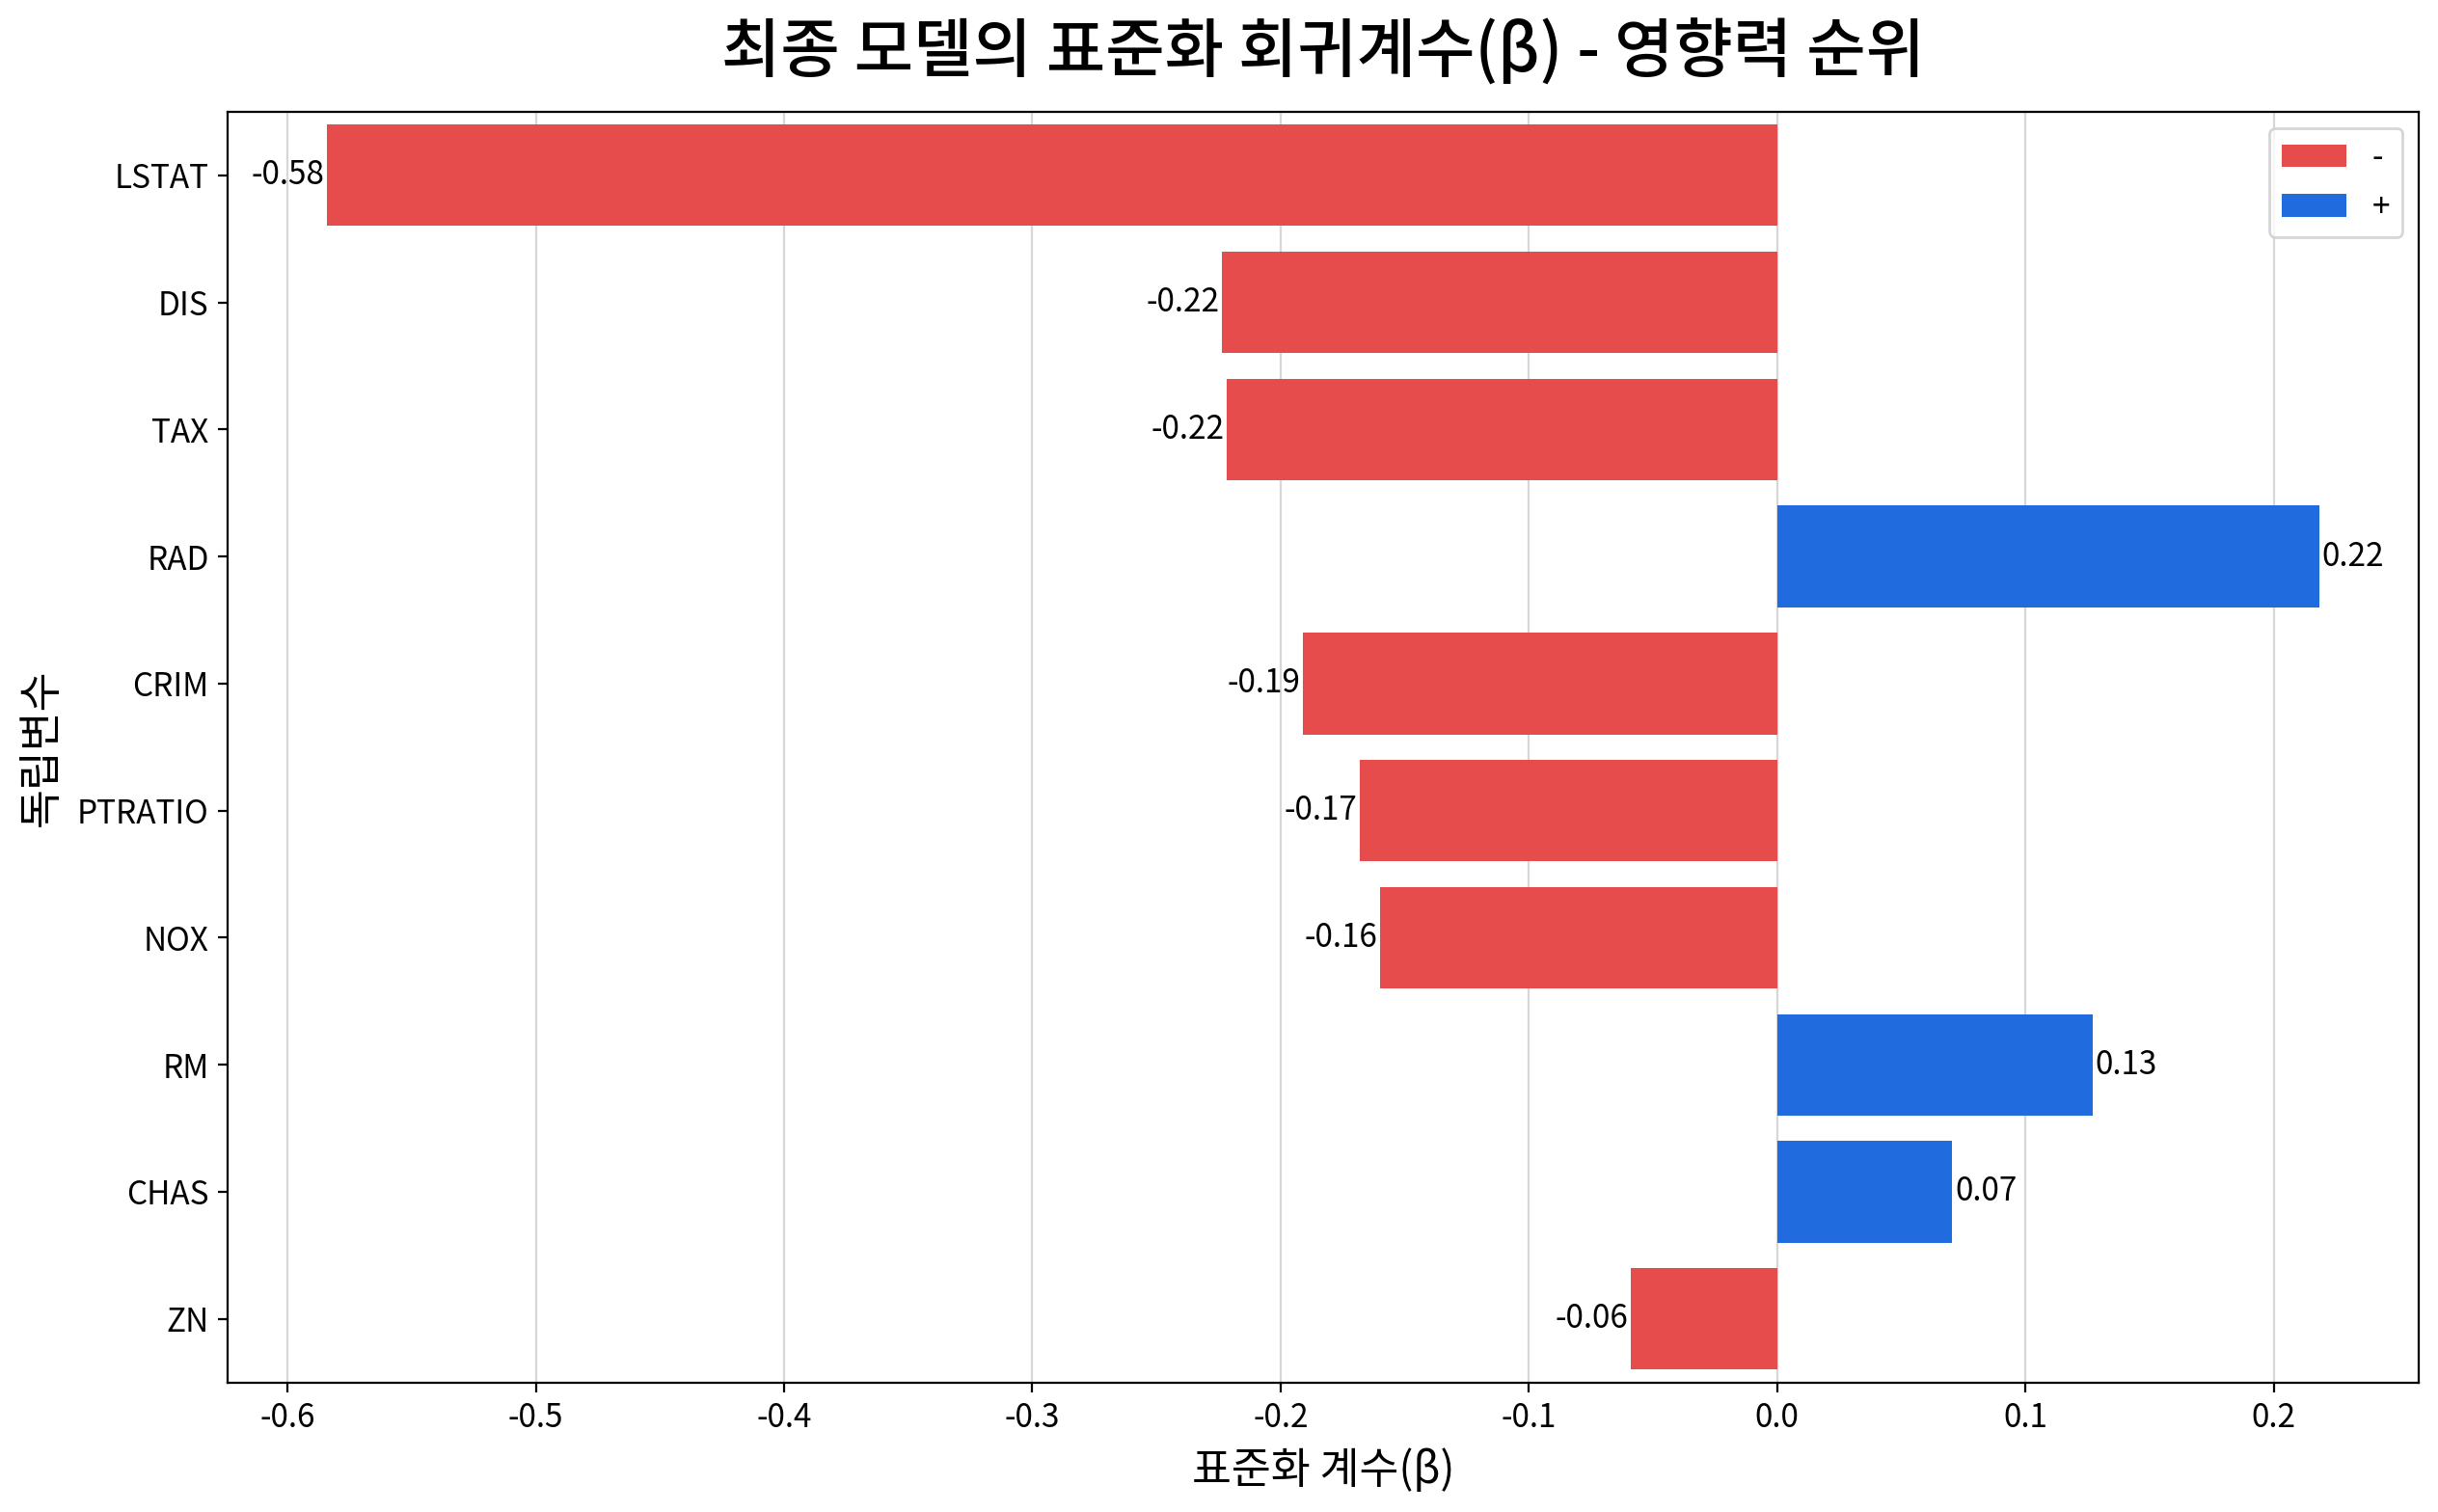

#### 4) 회귀계수 해석 문장

- **CRIM** 의 회귀계수는 **B = -0.04** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -3.16**, **p = .002**) 즉, CRIM가 **1% 증가**할 때 MEDV는 평균적으로 약 **0.04% 감소**하는 것으로 해석된다.
- **ZN** 의 회귀계수는 **B = -0.01** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -2.24**, **p = .025**) 즉, **(1+ZN)가 1% 증가**할 때 MEDV는 평균적으로 약 **0.01% 감소**하는 것으로 해석된다.
- **CHAS** 의 회귀계수는 **B = 0.11** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = 2.89**, **p = .004**) 즉, CHAS가 **1 증가**할 때 MEDV는 평균적으로 약 **12.02% 증가**하는 것으로 해석된다.
- **NOX** 의 회귀계수는 **B = -0.56** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -3.01**, **p = .003**) 즉, NOX가 **1 증가**할 때 MEDV는 평균적으로 약 **43.09% 감소**하는 것으로 해석된다.
- **RM** 의 회귀계수는 **B = 0.07** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = 2.79**, **p = .005**) 즉, RM가 **1 증가**할 때 MEDV는 평균적으로 약 **7.67% 증가**하는 것으로 해석된다.
- **DIS** 의 회귀계수는 **B = -0.17** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -4.37**, **p < .001**) 즉, DIS가 **1% 증가**할 때 MEDV는 평균적으로 약 **0.17% 감소**하는 것으로 해석된다.
- **RAD** 의 회귀계수는 **B = 0.1** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = 5.16**, **p < .001**) 즉, RAD가 **1% 증가**할 때 MEDV는 평균적으로 약 **0.10% 증가**하는 것으로 해석된다.
- **TAX** 의 회귀계수는 **B = -0.0** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -4.62**, **p < .001**) 즉, TAX가 **1 증가**할 때 MEDV는 평균적으로 약 **0.05% 감소**하는 것으로 해석된다.
- **PTRATIO** 의 회귀계수는 **B = -0.03** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -7.1**, **p < .001**) 즉, PTRATIO가 **1 증가**할 때 MEDV는 평균적으로 약 **3.13% 감소**하는 것으로 해석된다.
- **LSTAT** 의 회귀계수는 **B = -0.4** 으로 나타났으며, 이는 **MEDV** 에 유의한 요인임을 의미한다. (**t(495) = -10.98**, **p < .001**) 즉, LSTAT가 **1% 증가**할 때 MEDV는 평균적으로 약 **0.40% 감소**하는 것으로 해석된다.

> ※ **log1p**(=ln(1+·))의 % 해석은 변수 자체가 아니라 **(1+변수)** 기준이다.  
 값이 충분히 클 때만 변수 자체의 % 변화로 볼 수 있고, 0 근처·작은 값 구간에서는 원본처럼 동작하게 되어 % 해석이 맞지 않는다.   
 따라서 이때는 부호·유의성 중심으로 해석하거나 예측값을 'expm1(예측값)'로 원 척도에 되돌려 비교한다.

> ※ **반사 후 log1p**(=ln(1+max-·))는 값의 대소가 뒤집힌 변환이다.     
위 문장의 변화량(%)과 증가·감소 방향은 **(1+max-변수)** 기준이며, 원 변수 기준 방향은 각 문장 끝 괄호에 적었다.      
변수가 **최댓값에 가까운 구간**에서는 (1+max-변수)가 1 근처의 작은 값이 되어 해석이 부정확하므로 부호·유의성 중심으로 해석하거나 예측값을 'max - expm1(예측값)'으로 원 척도에 되돌려 비교한다. (max는 학습 데이터 기준)

> ※ 위 **t** 와 **유의확률** 은 등분산 가정이 충족되지 않은 경우를 대비해 **HC3 로버스트 표준오차**로 계산한 값이다.   
회귀계수(B)와 효과 크기 해석은 일반 OLS와 동일하며, 표준오차만 이분산에 강건하게 보정되어 t와 유의확률, 그에 따른 유의성 판정이 달라질 수 있다.

---

### ▶ 회귀모형 가정 검정

#### 1) 선형성 검정

,statistic,p-value,linearity,result
Ramsey RESET,15.127,0.000,False,대립가설 채택 → 선형성 위배(곡선 관계 존재)


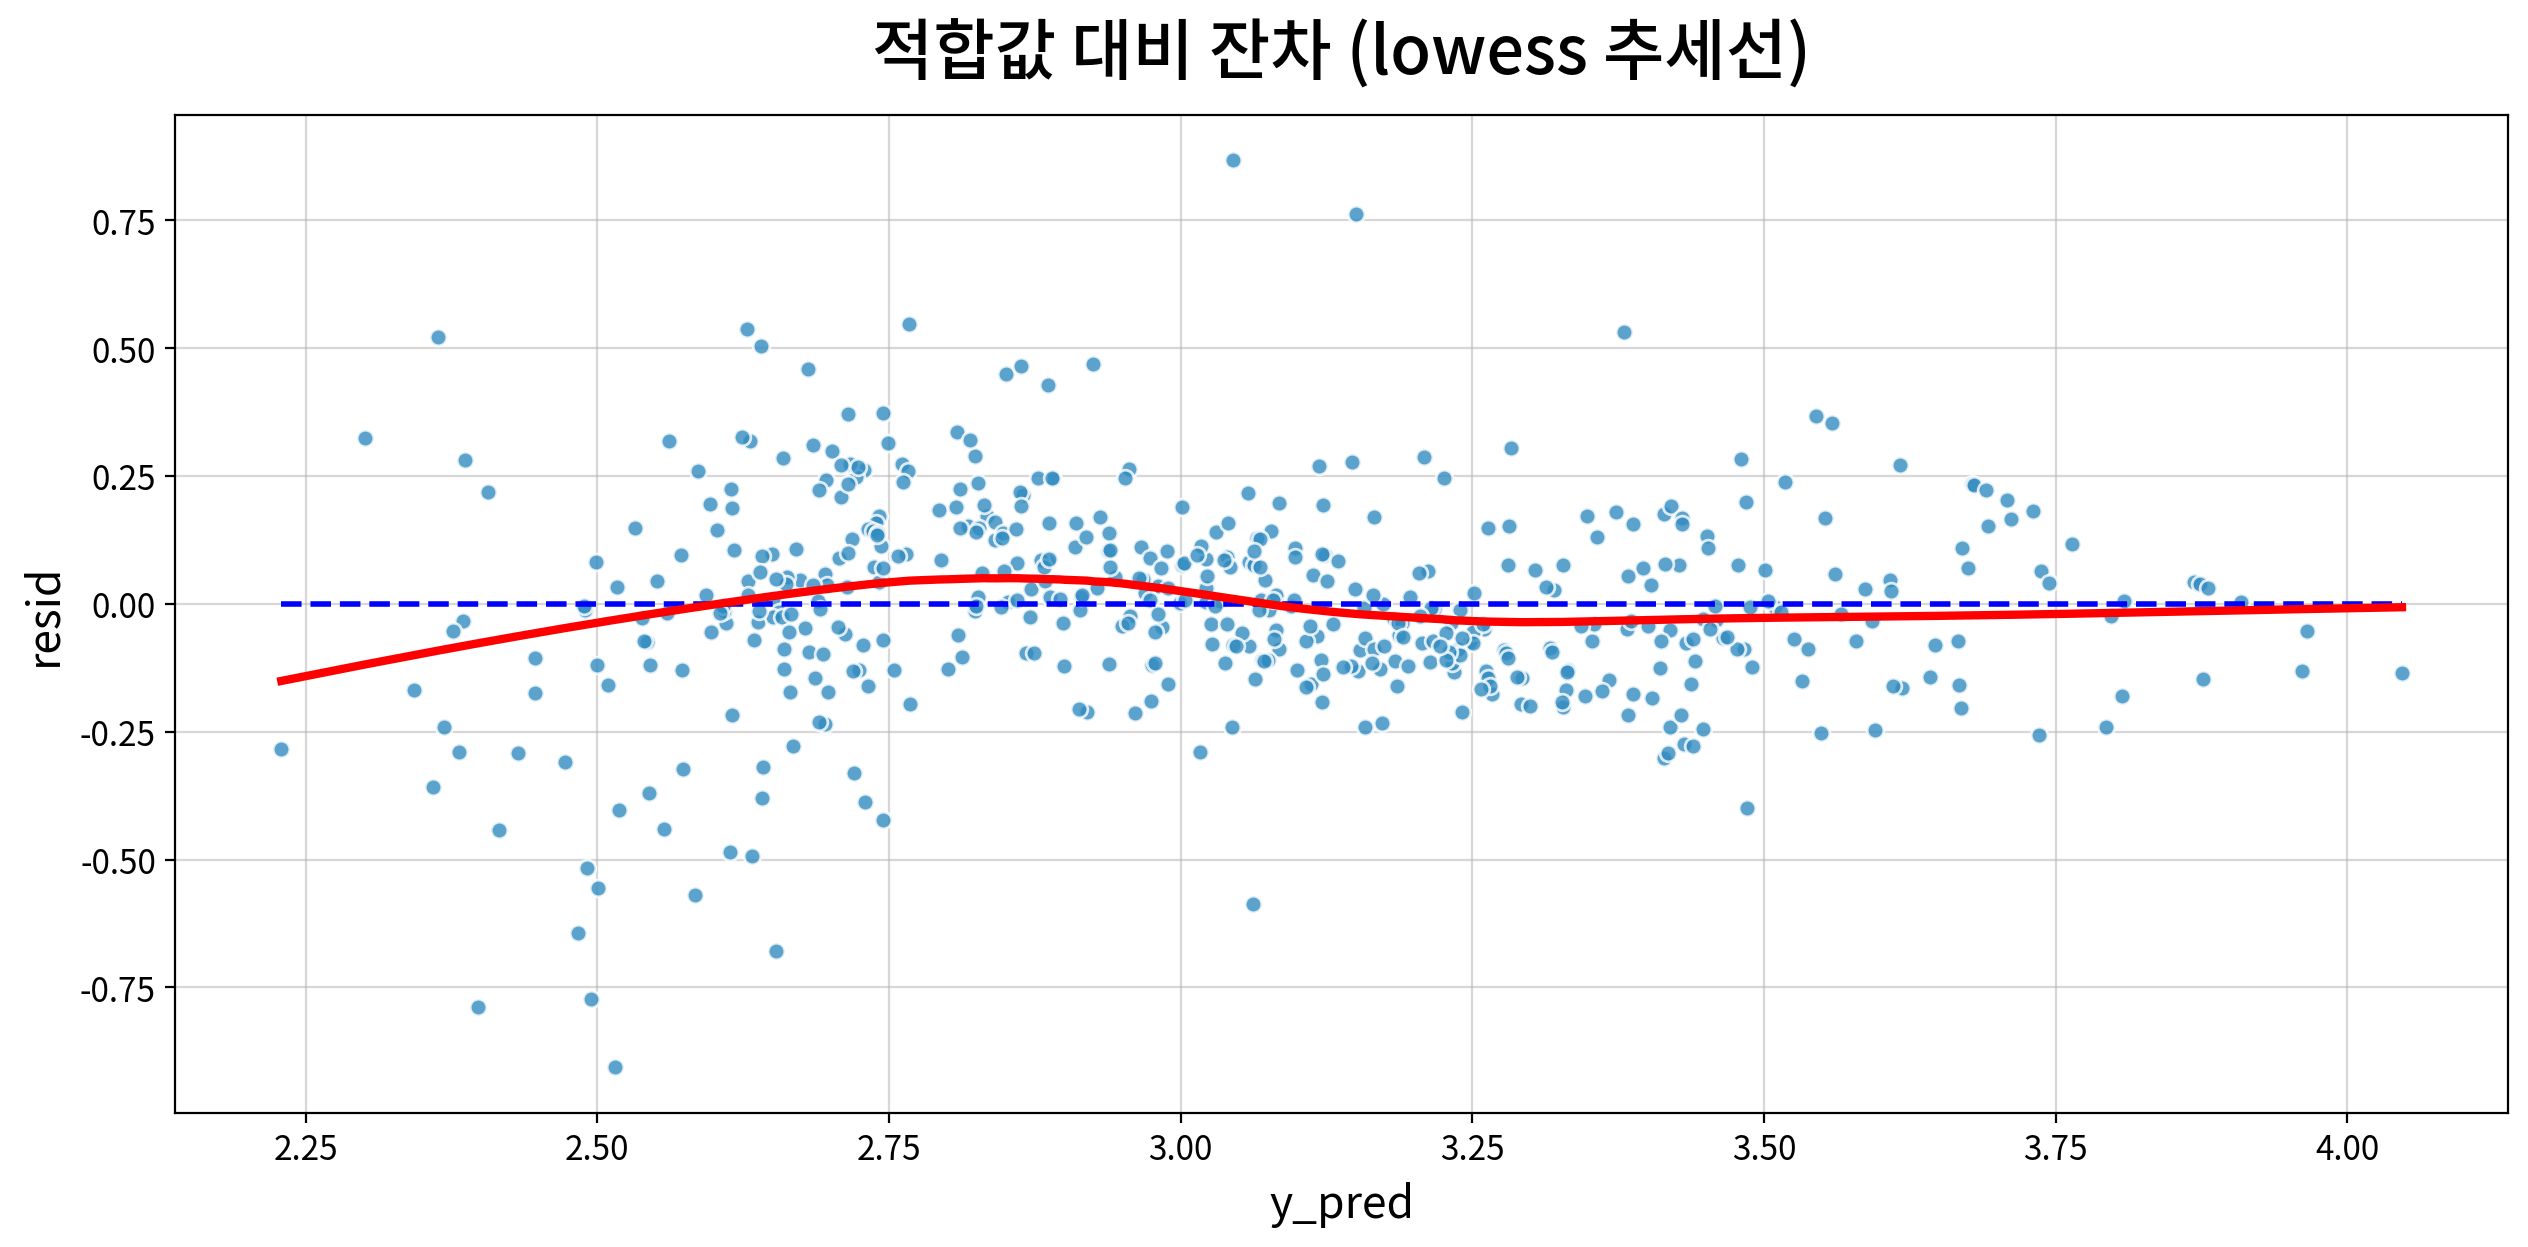

#### 2) 정규성 검정

▶ 검정통계량을 이용한 정규성 검정

,statistic,p-value,normality,result
Kolmogorov-Smirnov,0.066,0.024,False,대립가설 채택 → 정규성 위배


▶ Q-Q 플롯을 이용한 정규성 검정

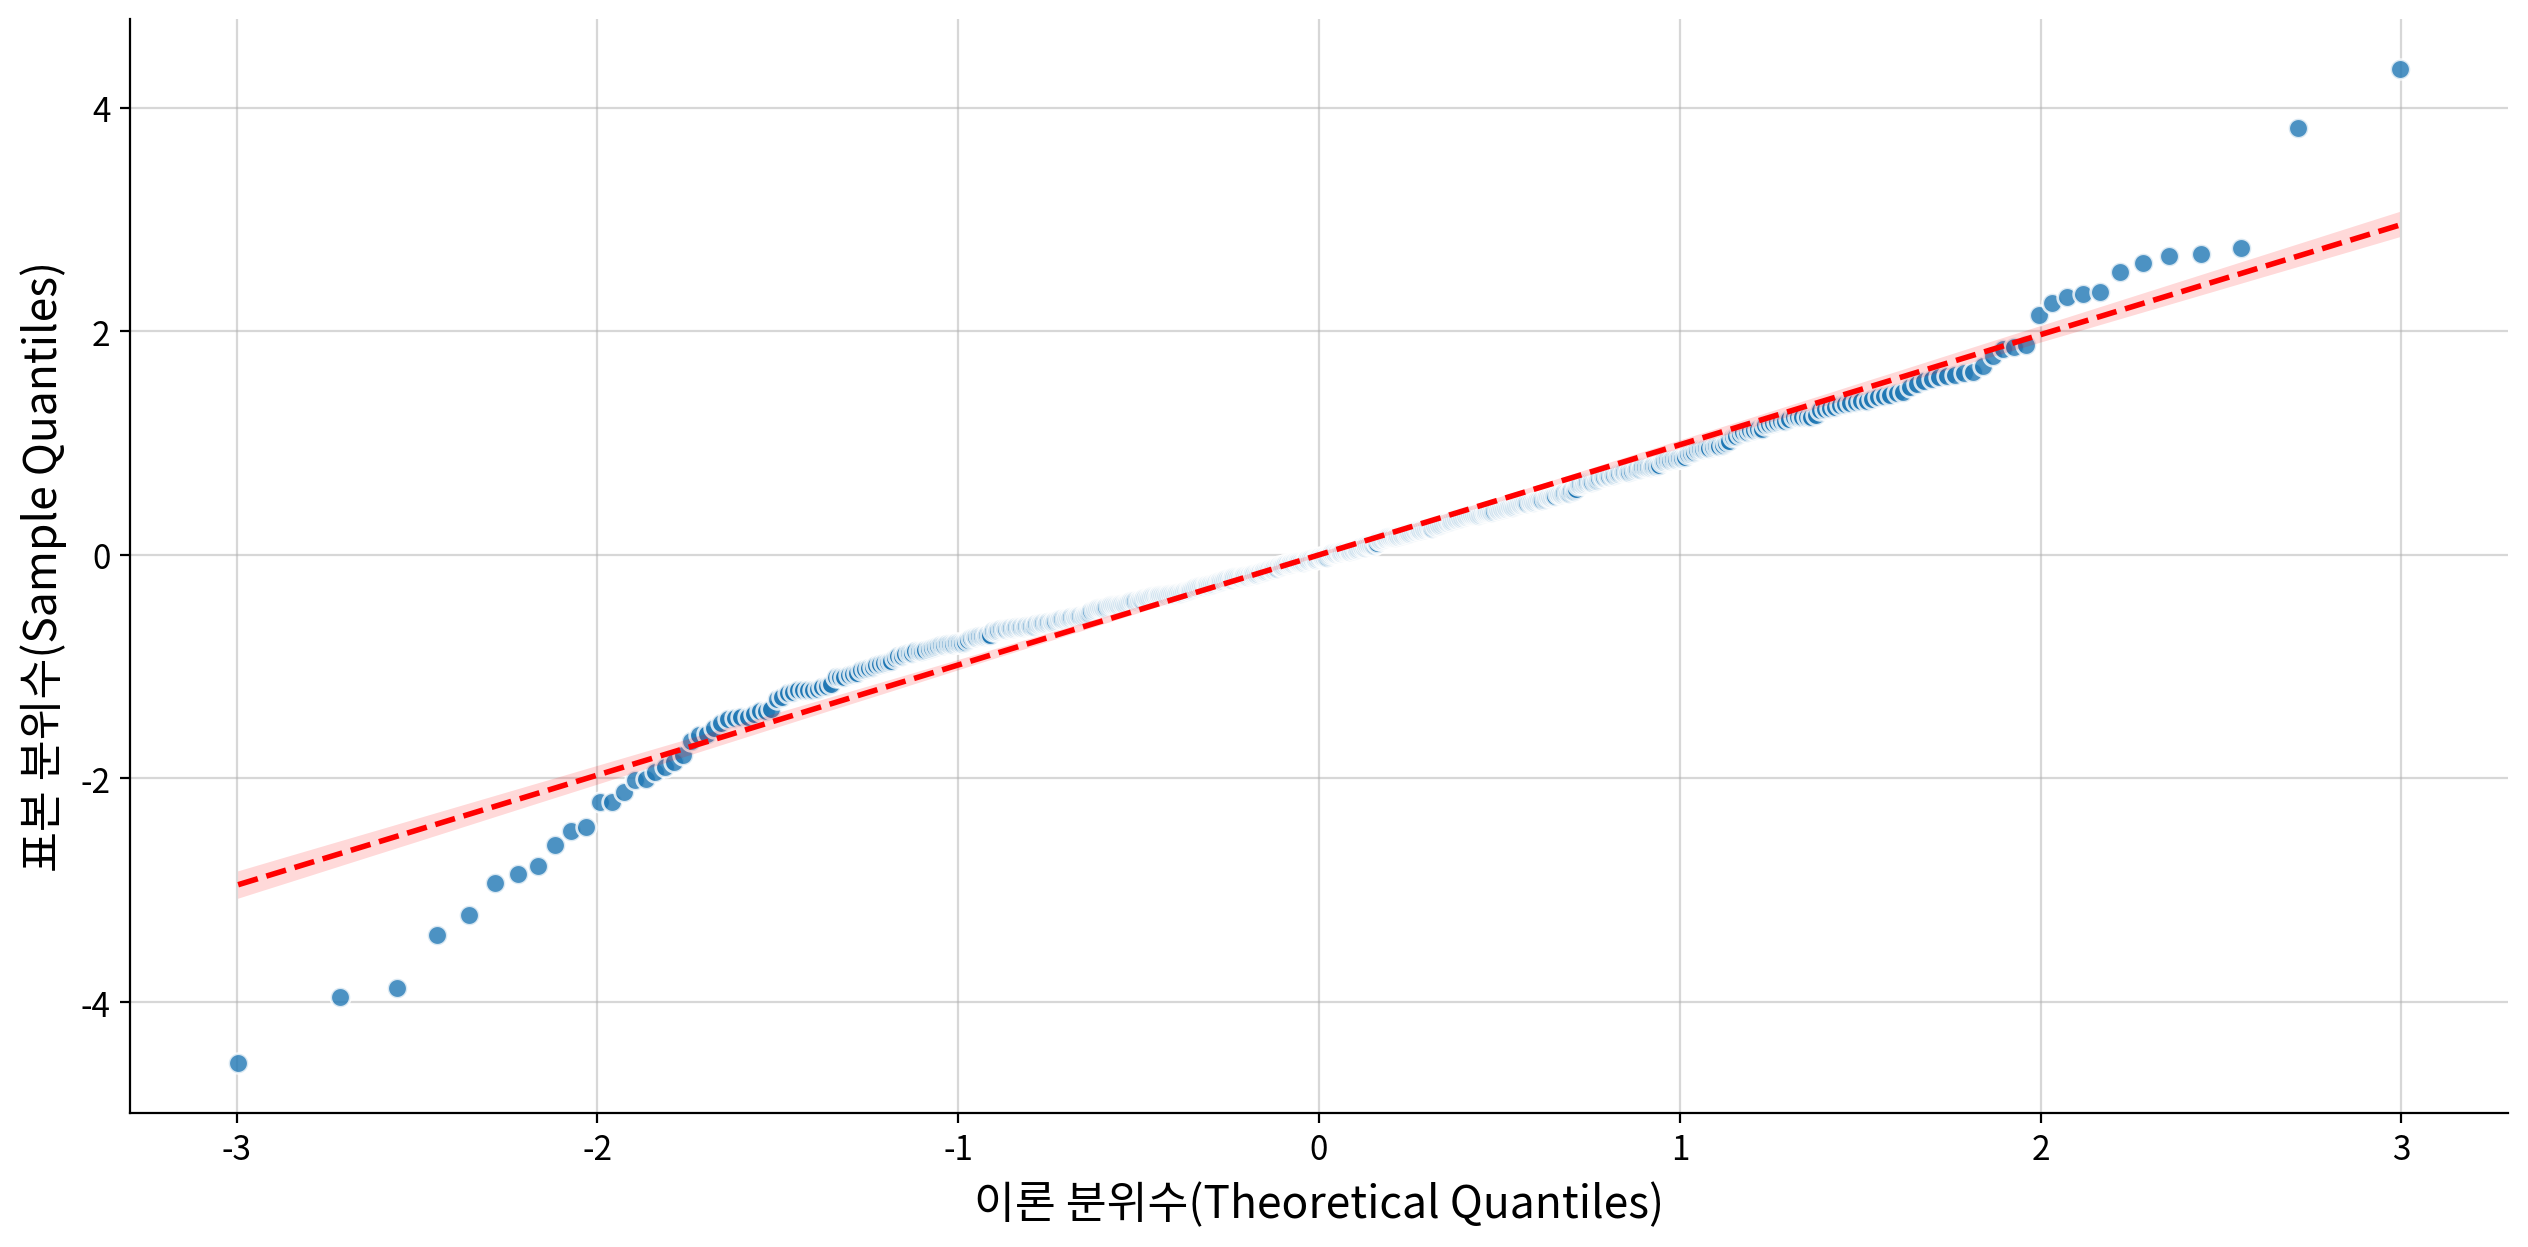

▶ √MSE 구간 규칙을 이용한 정규성 검정

,기대(%),허용 구간(%),실제(%),판정
구간,,,,
±1√MSE,68.000,64~72,76.680,위배
±2√MSE,95.000,93~97,94.860,충족
±3√MSE,99.700,99~100,98.620,위배


√MSE = 0.20 · 구간 규칙 판정: 정규성 위배


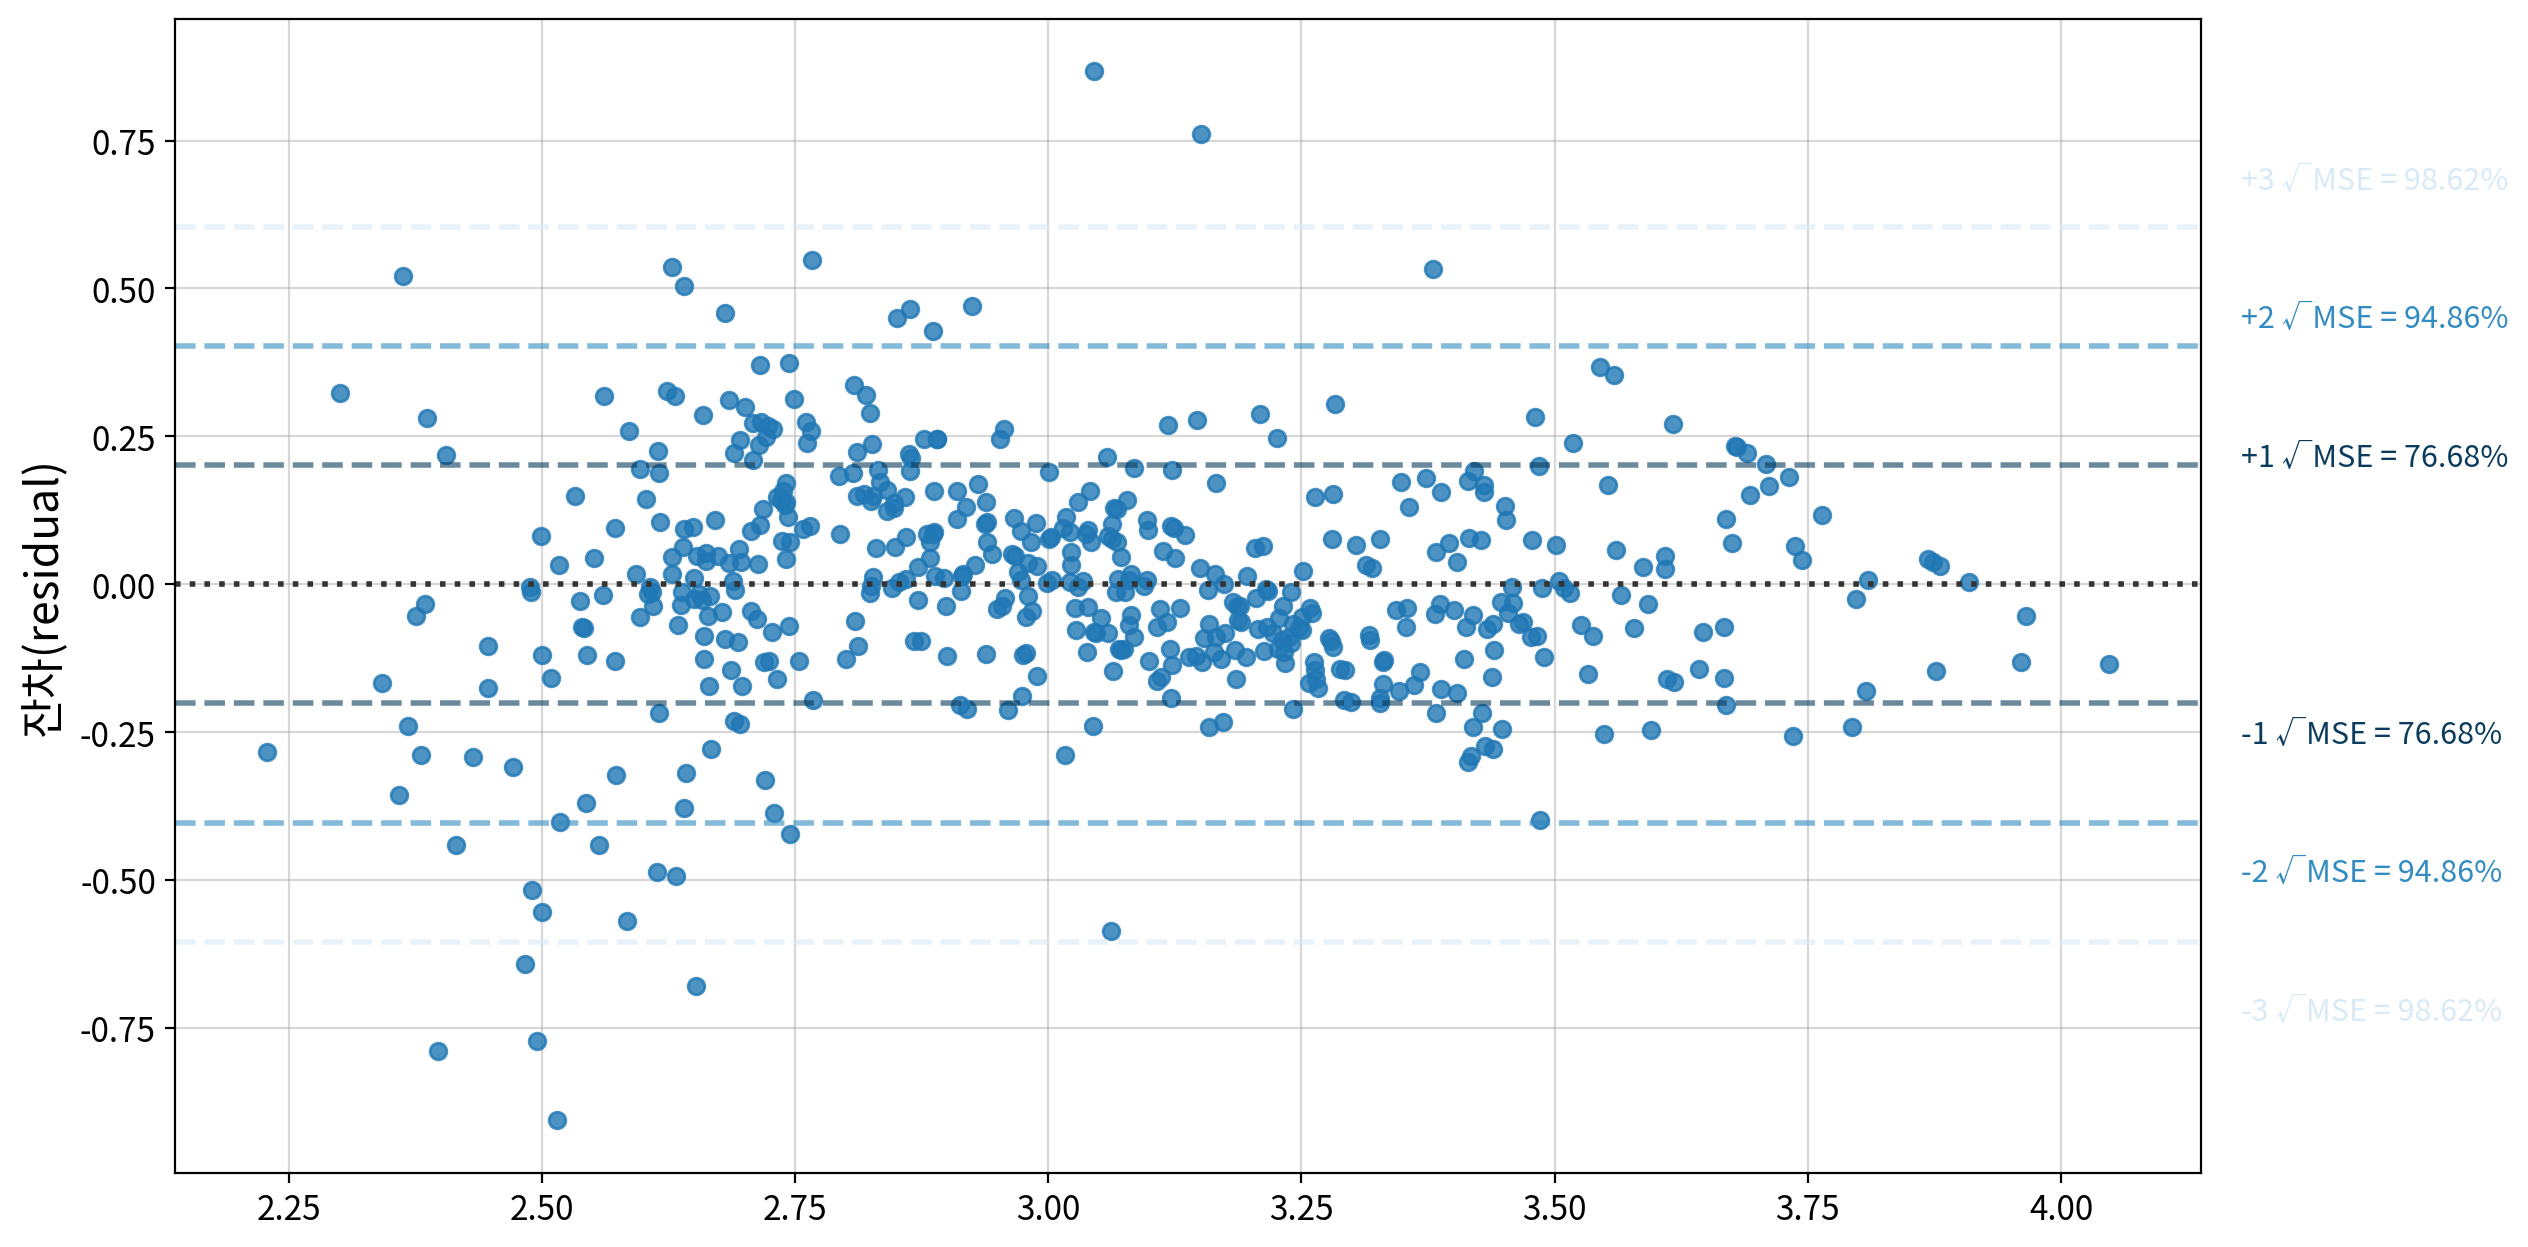

#### 3) 등분산성 검정

,LM Statistic,LM p-value,F Statistic,F p-value,homoscedasticity
Breusch-Pagan,91.866,0.000,10.980,0.000,False


F p-value = 0.0000 · 등분산성 판정: 대립가설 채택 → 등분산성 위배



#### 4) 독립성 검정

,statistic,independence,result
Durbin-Watson,0.945,False,독립성 위반 (양(+)의 자기상관)


In [22]:
final_fit = best
my_ols.report_model(final_fit)

> 💡 **인사이트 — 최종 모델**
>
> - **F(10, 495) = 158.21, p < .001, R² = 0.762** — log(MEDV) 변동의 약 76%를 설명한다. 등분산성이 위배돼 모든 유의성은 **HC3** 기준으로 판단했다.
> - **영향력 1위는 `LSTAT`(β = −0.584)** 로, 2위 `DIS`(−0.223)의 약 2.6배다. 로그-로그 계수로 읽으면 **저소득층 비율이 1% 늘 때 집값은 약 0.40% 하락**한다.
> - `RM`은 방이 1개 늘 때 약 **7.7% 상승**, `CHAS`는 강변이면 약 **12.0% 프리미엄**, `PTRATIO`(학생/교사 비율)는 1 늘 때 **3.1% 하락** — 학군도 가격에 반영된다.
> - ⚠️ **부호가 뒤집힌 변수에 주의**: `RAD`는 단독으로는 가격과 음(−)의 관계(ρ = −0.347)였지만 모델에서는 양(+)(β = +0.218)이다. 다변량 분석에서 확인했듯 `RAD`는 `CRIM` · `TAX`와 강하게 얽혀 있어(|ρ| ≥ 0.7), 범죄율·세율의 효과를 그 변수들이 가져가고 남은 부분만 양수로 남은 것으로 보인다. `ZN`도 단독 상관(+0.438)과 계수(−0.059)의 부호가 반대다. **이런 변수는 인과적으로 해석하기보다 통제변수로 보는 것이 맞다.**
> - **선형성 · 정규성 · 등분산성 · 독립성 모두 위배.** DW = 0.945는 행 순서상 이웃한 지역끼리 잔차가 닮았다는 뜻으로, 데이터가 지역 순서대로 정렬돼 있다면 **공간 자기상관**의 신호로 볼 수 있다.

---

# 📌 종합 인사이트

### 1. 데이터는 깨끗했지만, '분포'와 '상한값'이 진짜 문제였다
- 결측·중복은 0건이었다. 대신 `CRIM` · `ZN`의 극단적 우편향과 **`MEDV = 50` 상한(16건)** 이 분석의 핵심 과제였다.
- 상한 16건을 빼면 RMSE가 4.336 → 3.580으로 낮아지지만, 같은 490행으로 비교하면 차이는 2%뿐이다.

### 2. 집값은 '누가 사는가'와 '얼마나 큰가'가 결정한다
- 영향력 1위 **`LSTAT`(β = −0.584)**: 저소득층 비율이 1% 늘면 집값은 약 0.40% 하락한다.
- `RM`(방 1개 +7.7%) · `CHAS`(강변 +12.0%) · `PTRATIO`(학급 규모 1 증가당 −3.1%)가 뒤를 잇는다.

### 3. 전처리는 '많이'가 아니라 '맞게'한다
| 체크포인트 | RMSE | 판정 |
|---|---|---|
| 0_기준선 | 4.680 | — |
| **1_로그변환** | **4.336** | ✅ 최고 성능 |
| 2_이상치대체 | 4.359 | 로그 뒤 이상치 대체는 정보 손실 |
| 3_공선성제거 | 4.359 | 최대 VIF 7.57 → 제거 대상 없음 |
| 4_스케일링 | 4.359 | OLS 성능 불변 |

### 4. 계수는 '상관'이지 '인과'가 아니다
- `RAD`는 단독 상관과 모델 계수의 **부호가 반대**였다. `CRIM` · `TAX`와 강하게 얽혀 있어 공통 정보를 나눠 갖기 때문으로 보인다.
- `B`(인종 구성 지표)는 통계적으로도 제외됐지만, 실무 모델이라면 **처음부터 쓰지 않는 것**이 맞다.

### ⚠️ 한계와 개선 방향
- **종속변수 상한(50) :** `MEDV = 50`인 16건은 실제 가격이 50보다 높을 텐데 50으로 기록된 값이라, 이 구간의 예측 오차가 클 수밖에 없다.
  - 민감도 분석에서 이 16건을 빼도 예측력(같은 490행 기준 2% 차이)과 모델 구조(같은 10개 변수)는 거의 바뀌지 않았다.
  - 그래도 제거하지 않았다. 오류가 아니라 **실제로 존재하는 최고급 주거지**이고, 지우면 모델이 이 구간을 학습하지 못하며, 성능을 좋게 보이려고 데이터를 고르는 것이 되기 때문이다.
  - 성능은 전체 506행 기준(RMSE 4.336)으로 보고했다. 더 정확히 하려면 상한값을 '50 이상'이라는 정보로 다루는 모델(중도절단 회귀)이 필요하다.
- 네 가지 가정이 모두 위배됐다. 선형성 위배(RESET p < .001)는 `LSTAT` · `RM`의 곡선 관계에서 온 것으로 보이고, 독립성 위배(DW = 0.945)는 이웃한 지역끼리 잔차가 닮았다는 신호다.
- 성능은 **학습 데이터 기준(in-sample)** 이다. 실제 예측력은 train/test 분할이나 교차검증으로 확인해야 한다.
- 개선안: 곡선 관계를 담기 위해 제곱항(`RM²` 등)이나 변수 간 상호작용항을 시도하고, 학습에 쓰지 않은 데이터로 성능을 검증한다.

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 형태 | `log(MEDV)` ~ 10개 변수 (CRIM·DIS·RAD·LSTAT는 log, ZN은 log1p) |
| 성능 (원본 척도) | **RMSE 4.336** · MAE 3.075 · R² 0.777 |
| 가장 큰 영향 | `LSTAT` (β = −0.584) |